# Evaluación de la deformación superficial asociada a movimientos en masa mediante análisis InSAR y datos GNSS en la cuenca media y baja del río Suárez, Colombia

## Notebook 4. Figuras de la tesis y capas para el SIG

**Autores:** Mariana Paredes Galindo · Sair Granada Garzón
Universidad Industrial de Santander · Escuela de Geología · Bucaramanga, 2026

Este cuaderno parte de los resultados de los notebooks 1 a 3 (GeoTIFF, series de MintPy, zonas de deformación activa y series GNSS) y no repite ningún procesamiento. Hace dos cosas: dibuja cada figura de resultados completa, con sus paneles A, B, C, lista para el documento, y exporta las mismas capas en GeoTIFF y GeoPackage para cargarlas en el sistema de información geográfica (SIG). Las figuras usan el diseño común de los cuatro notebooks: letra Times New Roman (o Liberation Serif, de las mismas medidas) de 11 puntos, gráficas con el formato de Excel y la escala de velocidad de rojo a azul pasando por amarillo y verde.

Salidas: `03_resultados/figuras_documento/` (PNG a 300 ppp, con el nombre del título de cada figura), `03_resultados/figuras_tesis/paneles/` (tablas y cifras), `03_resultados/fichas_zonas_deformacion_activa.pdf` (fichas de las zonas) y `03_resultados/sig/zonas_deformacion_activa_google_earth.kmz` (capa para Google Earth).

## 1. Preparación: rutas, estilo y funciones comunes

Define las rutas, la malla de 80 m de referencia (la del mosaico de velocidad) y las funciones que leen los rásteres en esa malla, recortan a la cuenca y dibujan el marco de los mapas (coordenadas, norte y escala). La celda siguiente fija el diseño de las figuras. No produce figuras.

In [ ]:
import os, io, json, warnings, numpy as np, pandas as pd, h5py, rasterio, geopandas as gpd, matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin, rowcol
from rasterio.features import geometry_mask, rasterize
import requests
warnings.filterwarnings('ignore')

R = os.path.expanduser('~/Tesis_InSAR_Rio_Suarez')
Z = f'{R}/03_resultados/zda'
GT = f'{R}/03_resultados/geotiff'
MP = f'{R}/02_mintpy/suarez_2024_2026_v1_'
PAN = f'{R}/03_resultados/figuras_tesis/paneles'
SIG = f'{R}/03_resultados/sig'
for d in (PAN, SIG): os.makedirs(d, exist_ok=True)

cuenca = gpd.read_file(f'{R}/01_datos/area_estudio/Cuenca_RioMedioyBajoSuarez.shp').to_crs(32618)
zda = gpd.read_file(f'{Z}/zda.gpkg').to_crs(32618)
geo = gpd.read_file(f'{Z}/geologia_sgc2023.gpkg').to_crs(32618)
with rasterio.open(f'{GT}/mosaicos/velocidad_local_mm_anio_DESCENDING_R69_area.tif') as r:
    T, S, CRS = r.transform, r.shape, r.crs
DENTRO = geometry_mask(cuenca.geometry, out_shape=S, transform=T, invert=True)

def leer_tif(ruta, metodo=Resampling.bilinear):
    """Lee un GeoTIFF y lo lleva a la malla de referencia."""
    with rasterio.open(ruta) as r:
        a = r.read(1).astype('float32')
        if r.nodata is not None: a[a == r.nodata] = np.nan
        if r.transform == T and r.shape == S: return a
        o = np.full(S, np.nan, 'float32')
        reproject(a, o, src_transform=r.transform, src_crs=r.crs, dst_transform=T, dst_crs=CRS,
                  src_nodata=np.nan, dst_nodata=np.nan, resampling=metodo)
        return o

def leer_h5(nombre, clave, frames=('F572', 'F567'), orbita='DESCENDING_R69_'):
    """Lee una capa de MintPy de uno o varios frames y la une en la malla de referencia."""
    res = None
    for fr in frames:
        with h5py.File(f'{MP}{orbita}{fr}/{nombre}') as f:
            a = f[clave][()].astype('float32'); at = dict(f.attrs)
        o = np.full(S, np.nan, 'float32')
        reproject(a, o, src_transform=from_origin(float(at['X_FIRST']), float(at['Y_FIRST']), 80, 80), src_crs='EPSG:32618',
                  dst_transform=T, dst_crs=CRS, src_nodata=np.nan, dst_nodata=np.nan, resampling=Resampling.bilinear)
        o[o <= 0] = np.nan
        res = o if res is None else np.fmax(res, o)
    return res

def guardar_tif(a, nombre, nodata=np.nan, tipo='float32'):
    perfil = dict(driver='GTiff', height=S[0], width=S[1], count=1, dtype=tipo, crs=CRS, transform=T, nodata=nodata, compress='deflate')
    with rasterio.open(f'{SIG}/{nombre}.tif', 'w', **perfil) as w: w.write(a.astype(tipo), 1)

# recorte común de los mapas de la cuenca
_b = cuenca.total_bounds; _p = 2000
r0, c0 = rowcol(T, _b[0] - _p, _b[3] + _p); r1, c1 = rowcol(T, _b[2] + _p, _b[1] - _p)
r0, c0, r1, c1 = max(r0, 0), max(c0, 0), min(r1, S[0]), min(c1, S[1])
xa, ya = T * (c0, r0); xb, yb = T * (c1, r1); EXT = (xa, xb, yb, ya)
ASPECTO = (ya - yb) / (xb - xa)  # alto / ancho de los mapas de la cuenca
def recorte(a):
    a = a.copy(); a[~DENTRO] = np.nan; return a[r0:r1, c0:c1]

fmt = lambda v, d=1: f'{v:.{d}f}'.replace('.', ',')
CIFRAS = {}
print('Malla', S, '· píxeles en la cuenca', int(DENTRO.sum()))

Malla (2158, 1535) · píxeles en la cuenca 952795


### Diseño de figuras

Fija el diseño común de las figuras (el mismo de los notebooks 1 a 3) y las funciones de los mapas de la cuenca: marco con coordenadas en grados y minutos, norte, escala, leyenda y barra de colores debajo del mapa. Cada figura se guarda completa en `03_resultados/figuras_documento/` al mostrar su título.

In [ ]:
# Diseño común de los notebooks: fuente, paleta, estilo de los ejes, títulos de figura y tablas
import html
import unicodedata
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# Fuente: Times New Roman o la serif de las mismas medidas que esté instalada
FUENTES = ["Times New Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"]
instaladas = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = next(f for f in FUENTES if f in instaladas or f == "DejaVu Serif")

# Medidas: las figuras se dibujan al tamaño con que van en el documento (16 cm de ancho útil)
CM = 1 / 2.54
FIG_ANCHO = 16 * CM        # pulgadas
ESCALA_KM = 20             # longitud de la escala gráfica de los mapas, km
FIG_DOC = Path.home() / "Tesis_InSAR_Rio_Suarez" / "03_resultados" / "figuras_documento"
FIG_DOC.mkdir(parents=True, exist_ok=True)

# Colores de las gráficas, con la paleta de Excel
AZUL, NARANJA, GRIS, ORO, AZUL_CLARO, VERDE = "#4472C4", "#ED7D31", "#A5A5A5", "#FFC000", "#5B9BD5", "#70AD47"
FONDO = "#E7E6E6"          # sin dato en los mapas
COLOR_AZUL, COLOR_ROJO, COLOR_DATOS, COLOR_NARANJA = AZUL, "#C00000", GRIS, NARANJA
# Velocidad y desplazamiento: rojo (se aleja del satélite), amarillo, verde y azul (se acerca)
DESPLAZAMIENTO = LinearSegmentedColormap.from_list(
    "desplazamiento", ["#B2001A", "#FF0000", "#FF8C00", "#FFFF00", "#33CC33", "#00CCFF", "#0050FF", "#000096"])
PALETA_VELOCIDAD, PALETA_INCERTIDUMBRE = DESPLAZAMIENTO, "YlOrBr"
# Series temporales: descendente en azul, ascendente en naranja (tono claro para un segundo stack) y GNSS en negro
COLORES_STACK = {"DESCENDING": [AZUL, AZUL_CLARO], "ASCENDING": [NARANJA, ORO]}
COLOR_GNSS = "black"

plt.rcParams.update({
    "font.family": "serif", "font.serif": [FUENTE], "mathtext.fontset": "stix", "font.size": 11,
    "axes.titlesize": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "axes.labelweight": "bold",
    "axes.edgecolor": "#7F7F7F", "axes.linewidth": 0.75, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "axes.grid": False, "grid.color": "#D9D9D9", "grid.linewidth": 0.75,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "xtick.color": "#404040", "ytick.color": "#404040",
    "xtick.direction": "out", "ytick.direction": "out", "xtick.major.size": 3, "ytick.major.size": 3,
    "legend.fontsize": 10, "legend.frameon": False, "legend.title_fontsize": 10,
    "lines.linewidth": 1.25, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.04,
})
TIPO_HTML = "font-family:'Times New Roman',Times,serif;font-size:13px"


# Número con coma decimal
def coma(valor, decimales=1):
    return f"{valor:.{decimales}f}".replace(".", ",")


# Grados decimales a texto en grados y minutos con hemisferio
def gms(valor, positivo, negativo):
    total = round(abs(valor) * 60)
    return f"{total // 60}°{total % 60:02d}'{positivo if valor >= 0 else negativo}"


# Letra del panel: mayúscula en negrita, encima de la esquina superior izquierda, sin recuadro
def letra_panel(eje, letra, x=None, y=None):
    eje.text(0, 1.015, letra.upper(), transform=eje.transAxes, ha="left", va="bottom", fontsize=12,
             fontweight="bold", zorder=10)


# Ejes: en las gráficas, solo los bordes izquierdo e inferior; en los mapas, el marco completo
def estilo_eje(eje):
    mapa = eje.get_aspect() != "auto"
    for lado, borde in eje.spines.items():
        borde.set_visible(mapa or lado in ("left", "bottom"))
        borde.set_linewidth(0.75)
        borde.set_color("#404040" if mapa else "#7F7F7F")
    eje.tick_params(direction="out", length=3, top=False, right=False)


# Marcas de longitud en el borde inferior y de latitud en el izquierdo, en grados y minutos
def coordenadas_geograficas(eje, epsg, paso_x, paso_y, rotulos_y=True):
    from pyproj import Transformer
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    a_geo = Transformer.from_crs(epsg, 4326, always_xy=True)
    a_map = Transformer.from_crs(4326, epsg, always_xy=True)
    lon_min, lat_min = a_geo.transform(x0, y0)
    lon_max, lat_max = a_geo.transform(x1, y1)
    _, lat_borde = a_geo.transform((x0 + x1) / 2, y0)
    lon_borde, _ = a_geo.transform(x0, (y0 + y1) / 2)
    lons = np.arange(np.ceil(lon_min / paso_x) * paso_x, lon_max, paso_x)
    lats = np.arange(np.ceil(lat_min / paso_y) * paso_y, lat_max, paso_y)
    xs = [(a_map.transform(lon, lat_borde)[0], lon) for lon in lons]
    ys = [(a_map.transform(lon_borde, lat)[1], lat) for lat in lats]
    xs = [(x, v) for x, v in xs if x0 + 0.06 * (x1 - x0) < x < x1 - 0.06 * (x1 - x0)]
    ys = [(y, v) for y, v in ys if y0 + 0.05 * (y1 - y0) < y < y1 - 0.05 * (y1 - y0)]
    eje.set_xticks([x for x, _ in xs])
    eje.set_xticklabels([gms(v, "E", "W") for _, v in xs])
    eje.set_yticks([y for y, _ in ys])
    eje.set_yticklabels([gms(v, "N", "S") for _, v in ys] if rotulos_y else [], rotation=90, va="center")
    eje.set_xlabel("")
    eje.set_ylabel("")
    eje.tick_params(labelsize=9, length=2.5)


# Inserta NaN donde hay huecos mayores que "dias" para que la línea no cruce los vacíos
def cortar_huecos(fechas, valores, dias=60):
    fechas = pd.DatetimeIndex(fechas)
    corte = np.where(np.diff(fechas.asi8) / 86.4e12 > dias)[0] + 1
    return np.insert(fechas.to_numpy(), corte, np.datetime64("NaT")), np.insert(np.asarray(valores, dtype=float), corte, np.nan)


# Serie temporal: puntos, mediana móvil de "ventana" fechas y tendencia lineal discontinua.
# Devuelve la pendiente en mm/año (la ajustada, o la dada en "pendiente")
def trazar_serie(eje, fechas, serie, color, ventana=5, hueco=60, tamano=2.6, color_puntos=None, pendiente=None):
    fechas, serie = pd.DatetimeIndex(fechas), np.asarray(serie, dtype=float)
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if pendiente is None:
        pendiente, intercepto = np.polyfit(anios, serie, 1)
    else:
        intercepto = np.median(serie - pendiente * anios)
    eje.plot(fechas, serie, "o", ms=tamano, color=color_puntos or color, alpha=0.5, mew=0, zorder=2)
    suave = pd.Series(serie).rolling(ventana, center=True, min_periods=1).median().to_numpy()
    eje.plot(*cortar_huecos(fechas, suave, hueco), "-", lw=1.4, color=color, zorder=4)
    eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.1, color=color, zorder=5)
    return float(pendiente)


# Eje de una serie temporal: años en x, cuadrícula horizontal, línea en cero y un margen de 30 días a cada lado
def estilo_serie(eje, inicio, fin):
    eje.set_xlim(inicio - pd.Timedelta(days=30), fin + pd.Timedelta(days=30))
    eje.xaxis.set_major_locator(mdates.YearLocator())
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eje.axhline(0, color="#7F7F7F", lw=0.6, zorder=0)
    eje.grid(axis="y")
    estilo_eje(eje)


# Leyenda de una serie temporal, sin recuadro
def leyenda_serie(eje, manijas):
    eje.legend(handles=manijas, loc="best")


# Norte en la esquina superior derecha y escala gráfica en la inferior izquierda (mapa en metros), sin recuadros
def norte_y_escala(eje, escala_km=ESCALA_KM):
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    ancho, alto = x1 - x0, y1 - y0
    largo = escala_km * 1000; bx, by = x1 - 0.06 * ancho - largo, y0 + 0.035 * alto   # abajo a la derecha
    for i in range(2):
        eje.add_patch(plt.Rectangle((bx + i * largo / 2, by), largo / 2, 0.008 * alto,
                                    facecolor="black" if i == 0 else "white", edgecolor="black", lw=0.5, zorder=8))
    for v, x in (("0", bx), (f"{escala_km} km", bx + largo)):
        eje.text(x, by + 0.014 * alto, v, ha="center", va="bottom", fontsize=9, zorder=8)
    nx, ny = x1 - 0.07 * ancho, y1 - 0.11 * alto
    eje.annotate("", xy=(nx, ny + 0.065 * alto), xytext=(nx, ny), zorder=8,
                 arrowprops=dict(arrowstyle="-|>,head_width=0.25,head_length=0.5", color="black", lw=1.1))
    eje.text(nx, ny + 0.07 * alto, "N", ha="center", va="bottom", fontsize=10, fontweight="bold", zorder=8)


# Barra de colores horizontal con rótulo; con límite, marcas cada 10 o 20 unidades
def barra_colores(fig, imagen, ejes, rotulo, limite=None, encoger=0.6):
    marcas = range(-limite, limite + 1, 20 if limite > 40 else 10) if limite else None
    barra = fig.colorbar(imagen, ax=ejes, orientation="horizontal", shrink=encoger, pad=0.04, aspect=35, ticks=marcas)
    barra.set_label(rotulo, fontsize=10)
    barra.ax.tick_params(labelsize=9, length=2.5)
    barra.outline.set_linewidth(0.5)
    return barra


# Nombre de archivo a partir del título de la figura
def nombre_archivo(titulo):
    texto = unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()
    nombre = ""
    for palabra in "".join(c if c.isalnum() else " " for c in texto).split():
        if len(nombre) + len(palabra) > 120:
            break
        nombre = f"{nombre}_{palabra}" if nombre else palabra
    return nombre


# Título de la figura encima de ella ("Figura N" en negrita, si se da el número, y el título en cursiva).
# La figura actual se guarda en 03_resultados/figuras_documento con el nombre del título, a 300 ppp
def titulo_figura(titulo, numero=None, fig=None):
    (fig or plt.gcf()).savefig(FIG_DOC / f"{nombre_archivo(titulo)}.png", facecolor="white")
    cabeza = f'<div style="font-weight:bold">Figura {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 2px">{cabeza}'
                 f'<div style="font-style:italic">{html.escape(titulo)}</div></div>'))


# Inserta NaN donde hay un hueco de más de max_dias días, para que la línea no lo cruce
def romper_huecos(fechas, valores, max_dias=30):
    f, v = [fechas[0]], [valores[0]]
    for k in range(1, len(fechas)):
        if (fechas[k] - fechas[k - 1]).days > max_dias:
            f.append(fechas[k - 1] + pd.Timedelta(days=1))
            v.append(np.nan)
        f.append(fechas[k])
        v.append(valores[k])
    return pd.DatetimeIndex(f), np.array(v, dtype=float)


# Serie de desplazamiento: puntos, mediana móvil y tendencia lineal (discontinua). Devuelve el elemento de la leyenda
def dibujar_serie(eje, fechas, valores, color, etiqueta, ventana=5, color_puntos=None, pendiente=None, tam=2.8, max_hueco=30):
    fechas, valores = pd.DatetimeIndex(fechas), np.asarray(valores, dtype=float)
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if pendiente is None:
        pendiente, intercepto = np.polyfit(anios, valores, 1)
    else:
        intercepto = np.median(valores - pendiente * anios)
    color_puntos = color_puntos or color
    suave = pd.Series(valores).rolling(ventana, center=True, min_periods=1).median().to_numpy()
    eje.plot(fechas, valores, "o", ms=tam, color=color_puntos, alpha=0.5, mew=0, zorder=3)
    eje.plot(*romper_huecos(fechas, suave, max_hueco), "-", lw=1.4, color=color, zorder=4)
    eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.1, color=color, zorder=5)
    return Line2D([], [], color=color, lw=1.4, marker="o", ms=3.5, mfc=color_puntos, mec="none", label=etiqueta)


# Formato común de una serie temporal: línea en cero, cuadrícula horizontal, fechas legibles y rótulo del eje y
def formato_serie(eje, rotulo="Desplazamiento LOS (mm)"):
    inicio, fin = (mdates.num2date(v) for v in eje.get_xlim())
    anios = (fin - inicio).days / 365.25
    if anios <= 1.5:
        localizador, formato = mdates.MonthLocator(bymonth=(1, 4, 7, 10)), "%Y-%m"
    elif anios <= 3.5:
        localizador, formato = mdates.MonthLocator(bymonth=(1, 7)), "%Y-%m"
    else:
        localizador, formato = mdates.YearLocator(), "%Y"
    eje.xaxis.set_major_locator(localizador)
    eje.xaxis.set_major_formatter(mdates.DateFormatter(formato))
    eje.axhline(0, color="#7F7F7F", lw=0.6, zorder=0)
    eje.grid(axis="y")
    eje.set_ylabel(rotulo)
    estilo_eje(eje)


# Texto de una celda de tabla: coma decimal, decimales parejos por columna y guion para los vacíos
def texto_celda(valor, decimales):
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "-"
    if isinstance(valor, (float, np.floating)):
        return f"{valor:,.{decimales}f}".replace(",", " ").replace(".", ",")
    if isinstance(valor, (int, np.integer)):
        return f"{valor:,}".replace(",", " ") if abs(valor) >= 10000 else str(valor)
    return html.escape(str(valor))

# ---- Solo de este notebook ----
VEL = dict(cmap=PALETA_VELOCIDAD, vmin=-40, vmax=40)  # rojo: se aleja del satélite; azul: se acerca
ROTULO_VEL = 'Velocidad LOS (mm/año)   ← alejamiento | acercamiento →'


# Figura de mapas de la cuenca en una fila, con espacio debajo para leyendas o barras de colores
def figura_mapas(n=2, ancho=FIG_ANCHO, abajo_cm=2.2, titulos=True):
    w_cm = (ancho / CM - 1.4 - 0.5 * (n - 1)) / n
    alto = (w_cm * ASPECTO + abajo_cm + (0.9 if titulos else 0.5)) * CM
    fig, ejes = plt.subplots(1, n, figsize=(ancho, alto), squeeze=False)
    fig.subplots_adjust(left=1.1 * CM / ancho, right=1 - 0.3 * CM / ancho, wspace=0.5 / w_cm,
                        bottom=abajo_cm * CM / alto, top=1 - (0.9 if titulos else 0.5) * CM / alto)
    return fig, list(ejes[0])


# Marco de un mapa de la cuenca: fondo gris donde no hay dato, contorno, coordenadas y, si se pide, norte y escala
def marco_mapa(ax, letra=None, titulo=None, rotulos_y=True, norte=False):
    ax.set_xlim(xa, xb); ax.set_ylim(yb, ya); ax.set_aspect('equal')
    cuenca.plot(ax=ax, color=FONDO, lw=0, zorder=0)
    cuenca.boundary.plot(ax=ax, color='black', lw=0.7, zorder=5)
    coordenadas_geograficas(ax, 32618, 0.25, 0.5, rotulos_y=rotulos_y)
    estilo_eje(ax)
    if norte: norte_y_escala(ax)
    if titulo: ax.set_title(titulo, pad=14 if letra else 6)
    if letra: letra_panel(ax, letra)


# Barra de colores horizontal debajo de uno o varios mapas
def barra_color(fig, ax, im, etiqueta, ticks=None):
    cb = fig.colorbar(im, cax=ax.inset_axes([0.08, -0.1, 0.84, 0.025]), orientation='horizontal', ticks=ticks)
    cb.outline.set_linewidth(0.5); cb.ax.tick_params(labelsize=9, length=2.5); cb.set_label(etiqueta, fontsize=10)
    return cb


# Leyenda de clases debajo de un mapa
def leyenda(ax, items, ncol=2, **kw):
    ax.legend(handles=[Patch(fc=c, ec='#595959', lw=0.4, label=t) for t, c in items], loc='upper center',
              bbox_to_anchor=(0.5, -0.07), ncol=ncol, handlelength=1.2, columnspacing=1.0, fontsize=9, **kw)


# Ejes de una gráfica con el formato común
def ejes(ax, cuadricula='y'):
    if cuadricula: ax.grid(axis=cuadricula)
    estilo_eje(ax)


import matplotlib.dates as mdates
def eje_anios(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


print(f"ok: diseño cargado | fuente de las figuras: {FUENTE}")

ok: diseño cargado | fuente de las figuras: Liberation Serif


## 2. Relieve: pendiente y aspecto de las laderas

Calcula la pendiente y el aspecto (dirección hacia donde mira la ladera, en grados desde el norte) a partir del modelo de elevación de 80 m. El aspecto importa porque el satélite mira hacia el oeste en descendente y hacia el este en ascendente, y las laderas orientadas al norte o al sur casi no se ven en la línea de vista. Exporta las dos capas para el SIG.

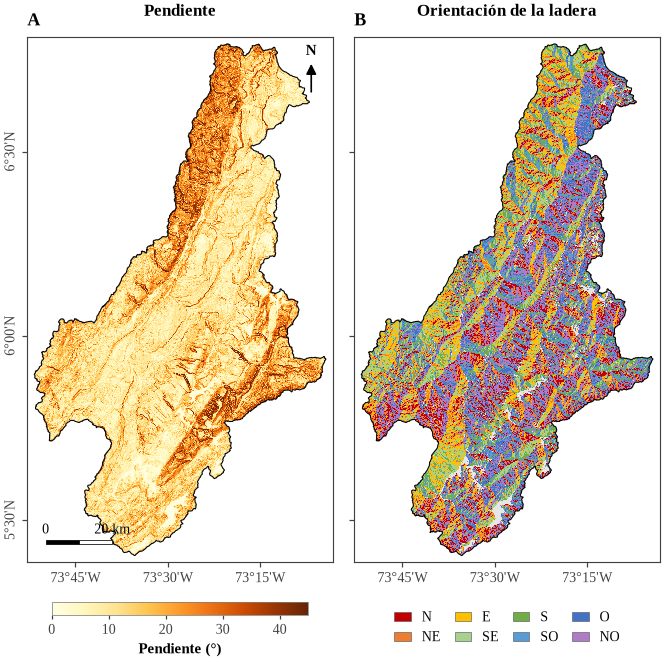

{'N': 13.0, 'NE': 11.1, 'E': 13.2, 'SE': 12.7, 'S': 9.7, 'SO': 9.7, 'O': 13.7, 'NO': 16.8}


In [ ]:
dem = leer_tif(f'{Z}/dem_80m.tif')
gy, gx = np.gradient(dem, 80.0) # gy: hacia el sur (filas), gx: hacia el este
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))
aspecto = (np.degrees(np.arctan2(-gx, gy)) + 360) % 360
aspecto[pendiente < 2] = np.nan # terreno casi plano sin dirección
guardar_tif(pendiente, 'pendiente_grados'); guardar_tif(aspecto, 'aspecto_grados')

col8 = ['#C00000', '#ED7D31', '#FFC000', '#A9D18E', '#70AD47', '#5B9BD5', '#4472C4', '#B07CC6']
dirs = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
asp8 = np.floor(((aspecto + 22.5) % 360) / 45)
fig, (a1, a2) = figura_mapas(2, abajo_cm=2.4)
im = a1.imshow(recorte(pendiente), extent=EXT, cmap='YlOrBr', vmin=0, vmax=45, interpolation='nearest', zorder=1)
marco_mapa(a1, 'A', 'Pendiente', norte=True)
barra_color(fig, a1, im, 'Pendiente (°)')
a2.imshow(recorte(asp8), extent=EXT, cmap=ListedColormap(col8), vmin=-0.5, vmax=7.5, interpolation='nearest', zorder=1)
marco_mapa(a2, 'B', 'Orientación de la ladera', rotulos_y=False)
leyenda(a2, list(zip(dirs, col8)), ncol=4)
titulo_figura('Pendiente y orientación de las laderas de la cuenca')
plt.show()
m = DENTRO & np.isfinite(asp8)
CIFRAS['aspecto_pct'] = {d: round(100 * float(np.mean(asp8[m] == i)), 1) for i, d in enumerate(dirs)}
print(CIFRAS['aspecto_pct'])

## 3. Distorsiones geométricas de cada geometría

Clasifica cada píxel según cómo lo ve el satélite, con la pendiente de la ladera medida en la dirección del rango (β) y el ángulo de incidencia (θ) de cada stack. Inversión por relieve (*layover*) si la ladera mira al satélite con β ≥ θ, escorzo (*foreshortening*) si mira al satélite con β < θ, sombra si da la espalda con |β| ≥ 90° − θ, y geometría favorable en el resto (Notti et al., 2014). Rumbo de vuelo de 192° en descendente y 348° en ascendente, con vista a la derecha. Exporta las dos capas.

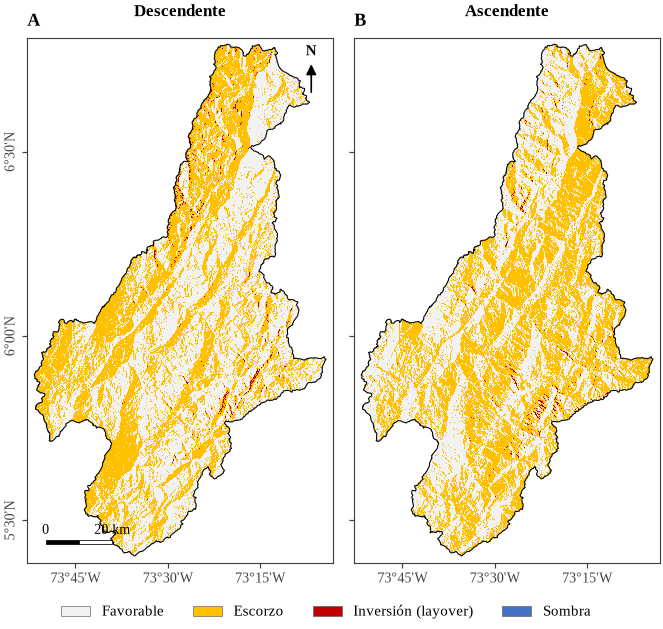

{'Favorable': 54.0, 'Escorzo': 45.2, 'Inversión (layover)': 0.8, 'Sombra': 0.0} {'Favorable': 50.6, 'Escorzo': 48.8, 'Inversión (layover)': 0.6, 'Sombra': 0.0}


In [ ]:
CLASES_D = [('Favorable', '#F2F2F2'), ('Escorzo', '#FFC000'), ('Inversión (layover)', '#C00000'), ('Sombra', '#4472C4')]
def distorsion(rumbo, incidencia):
    hacia_sat = np.radians((rumbo + 90 + 180) % 360) # azimut desde el suelo hacia el satélite
    beta = np.degrees(np.arctan(np.tan(np.radians(pendiente)) * np.cos(np.radians(np.nan_to_num(aspecto)) - hacia_sat)))
    k = np.zeros(S, 'float32')
    k[(beta > 0) & (beta < incidencia)] = 1
    k[beta >= incidencia] = 2
    k[beta <= -(90 - incidencia)] = 3
    k[~np.isfinite(dem) | ~np.isfinite(incidencia)] = np.nan
    return k
inc_d = leer_tif(f'{GT}/suarez_2024_2026_v1_DESCENDING_R69_F572/incidencia_grados.tif')
inc_a = leer_tif(f'{GT}/suarez_2024_2026_v1_ASCENDING_R77_F1199/incidencia_grados.tif')
fig, ejes_d = figura_mapas(2, abajo_cm=1.6)
for k_, (ax, nombre, rumbo, inc) in enumerate(zip(ejes_d, ('descendente', 'ascendente'), (192, 348), (inc_d, inc_a))):
    inc = np.where(np.isfinite(inc), inc, np.nanmedian(inc))
    k = distorsion(rumbo, inc); guardar_tif(k, f'distorsion_{nombre}')
    ax.imshow(recorte(k), extent=EXT, cmap=ListedColormap([c for _, c in CLASES_D]), vmin=-0.5, vmax=3.5, interpolation='nearest', zorder=1)
    marco_mapa(ax, 'AB'[k_], nombre.capitalize(), rotulos_y=k_ == 0, norte=k_ == 0)
    m = DENTRO & np.isfinite(k)
    CIFRAS[f'distorsion_{nombre}'] = {t: round(100 * float(np.mean(k[m] == i)), 1) for i, (t, _) in enumerate(CLASES_D)}
fig.legend(handles=[Patch(fc=c, ec='#595959', lw=0.4, label=t) for t, c in CLASES_D], loc='lower center', ncol=4,
           bbox_to_anchor=(0.5, 0.0), fontsize=9.5)
titulo_figura('Distorsiones geométricas por relieve en las geometrías descendente y ascendente')
plt.show()
print(CIFRAS['distorsion_descendente'], CIFRAS['distorsion_ascendente'])

## 4. Calidad de la señal: coherencia y sensibilidad al movimiento ladera abajo

Dibuja la coherencia espacial media y la coherencia temporal del stack descendente (frames F572 y F567 unidos) y la sensibilidad de cada geometría con el índice C de Notti et al. (2014). Baja si |C| < 0,3, media entre 0,3 y 0,6 y alta si |C| ≥ 0,6. Exporta la coherencia para el SIG.

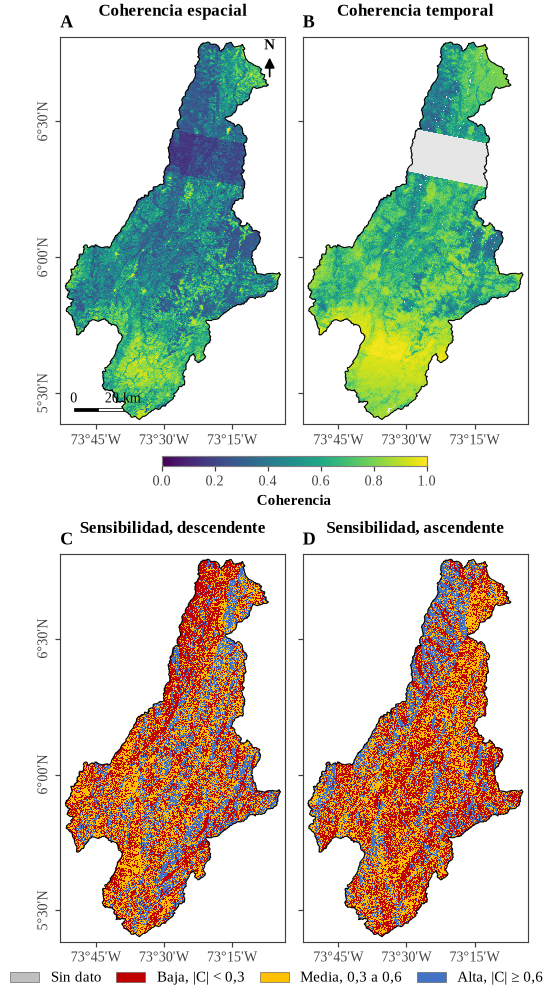

{'coh_s_media': 0.49, 'coh_t_media': 0.71, 'coh_t_ge07': 54.9, 'sensibilidad_descendente': {'Sin dato': 0.0, 'Baja, |C| < 0,3': 38.1, 'Media, 0,3 a 0,6': 36.5, 'Alta, |C| ≥ 0,6': 25.4}, 'sensibilidad_ascendente': {'Sin dato': 0.0, 'Baja, |C| < 0,3': 41.1, 'Media, 0,3 a 0,6': 36.6, 'Alta, |C| ≥ 0,6': 22.3}}


In [ ]:
coh_s = leer_h5('avgSpatialCoh.h5', 'coherence')
coh_t = leer_h5('temporalCoherence.h5', 'temporalCoherence')
guardar_tif(coh_s, 'coherencia_espacial_desc'); guardar_tif(coh_t, 'coherencia_temporal_desc')

CLASES_C = [('Sin dato', '#BFBFBF'), ('Baja, |C| < 0,3', '#C00000'), ('Media, 0,3 a 0,6', '#FFC000'), ('Alta, |C| ≥ 0,6', '#4472C4')]
def clases_C(C):
    k = np.full(S, np.nan); a = np.abs(C)
    k[np.isfinite(a)] = 1; k[a >= 0.3] = 2; k[a >= 0.6] = 3; k[DENTRO & ~np.isfinite(a)] = 0
    return k
PW = 5.2; PH = PW * ASPECTO                        # ancho y alto de cada mapa, cm
ANCHO_C, ALTO_C = 1.1 + 2 * PW + 0.4 + 0.3, 0.8 + PH + 3.0 + PH + 1.3
fig = plt.figure(figsize=(ANCHO_C * CM, ALTO_C * CM))
caja_cm = lambda x, y, w, h: fig.add_axes([x / ANCHO_C, y / ALTO_C, w / ANCHO_C, h / ALTO_C])
ejes_c = [caja_cm(1.1 + (PW + 0.4) * j, ALTO_C - 0.8 - PH - (PH + 3.0) * i, PW, PH) for i in range(2) for j in range(2)]
for k_, (ax, nombre, a) in enumerate(zip(ejes_c[:2], ('espacial', 'temporal'), (coh_s, coh_t))):
    im = ax.imshow(recorte(a), extent=EXT, cmap='viridis', vmin=0, vmax=1, interpolation='nearest', zorder=1)
    marco_mapa(ax, 'AB'[k_], f'Coherencia {nombre}', rotulos_y=k_ == 0, norte=k_ == 0)
cax = caja_cm(1.1 + PW * 0.45, ALTO_C - 0.8 - PH - 0.95, PW * 1.1 + 0.4, 0.22)
cb = fig.colorbar(im, cax=cax, orientation='horizontal'); cb.set_label('Coherencia', fontsize=10); cb.ax.tick_params(labelsize=9)
for k_, (ax, nombre) in enumerate(zip(ejes_c[2:], ('descendente', 'ascendente'))):
    k = clases_C(leer_tif(f'{Z}/indice_C_{nombre}.tif'))
    ax.imshow(recorte(k), extent=EXT, cmap=ListedColormap([c for _, c in CLASES_C]), vmin=-0.5, vmax=3.5, interpolation='nearest', zorder=1)
    marco_mapa(ax, 'CD'[k_], f'Sensibilidad, {nombre}', rotulos_y=k_ == 0)
    m = DENTRO & np.isfinite(k)
    CIFRAS[f'sensibilidad_{nombre}'] = {t: round(100 * float(np.mean(k[m] == i)), 1) for i, (t, _) in enumerate(CLASES_C)}
fig.legend(handles=[Patch(fc=c, ec='#595959', lw=0.4, label=t) for t, c in CLASES_C], loc='lower center', ncol=4,
           bbox_to_anchor=(0.5, 0.0), fontsize=9.5, columnspacing=1.0)
titulo_figura('Coherencia y sensibilidad de las geometrías al movimiento ladera abajo')
plt.show()
t = DENTRO & np.isfinite(coh_t)
CIFRAS['coh_t_media'] = round(float(np.nanmean(coh_t[t])), 2); CIFRAS['coh_t_ge07'] = round(100 * float(np.mean(coh_t[t] >= 0.7)), 1)
CIFRAS['coh_s_media'] = round(float(np.nanmean(coh_s[DENTRO & np.isfinite(coh_s)])), 2)
print({k: CIFRAS[k] for k in ('coh_s_media', 'coh_t_media', 'coh_t_ge07', 'sensibilidad_descendente', 'sensibilidad_ascendente')})

## 5. Medición según la pendiente, la cobertura y la geometría

Resume qué tan medible es el terreno: coherencia temporal y fracción de píxeles con velocidad por clase de pendiente y por cobertura de la tierra (ESA WorldCover 2021, llevada a 80 m por moda. Zanaga et al., 2022), y la frecuencia acumulada de la coherencia temporal en cada geometría. Exporta la cobertura para el SIG.

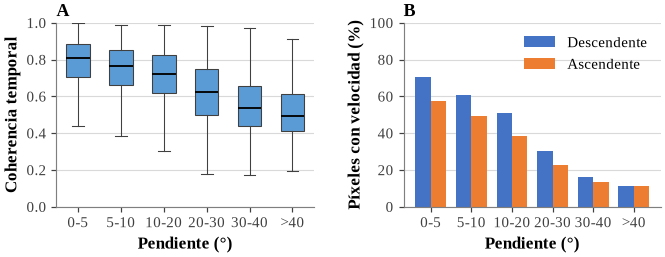

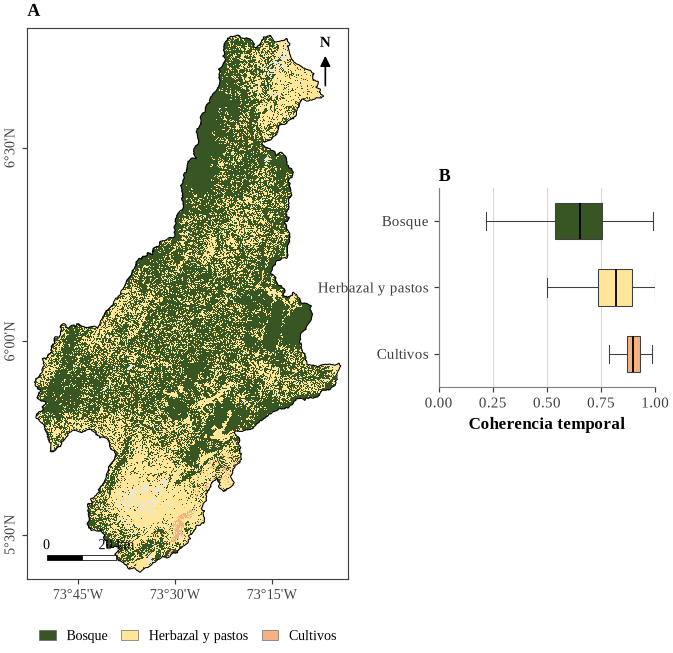

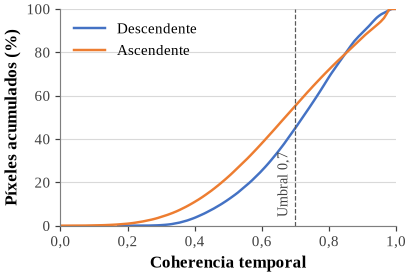

{'Bosque': {'area_pct': np.float64(62.8), 'coh_mediana': 0.65, 'medido_pct': 33.3}, 'Herbazal y pastos': {'area_pct': np.float64(35.2), 'coh_mediana': 0.82, 'medido_pct': 77.4}, 'Cultivos': {'area_pct': np.float64(0.7), 'coh_mediana': 0.9, 'medido_pct': 99.0}} 54.9 44.6


In [ ]:
vd = leer_tif(f'{GT}/mosaicos/velocidad_local_mm_anio_DESCENDING_R69_area.tif')
va = leer_tif(f'{GT}/mosaicos/velocidad_local_mm_anio_ASCENDING_R77_area.tif')
pend = leer_tif(f'{Z}/pendiente_grados.tif')
LIM = [0, 5, 10, 20, 30, 40, 90]; ETQ = ['0-5', '5-10', '10-20', '20-30', '30-40', '>40']
cajas, med_d, med_a = [], [], []
for a, b in zip(LIM[:-1], LIM[1:]):
    m = DENTRO & (pend >= a) & (pend < b)
    x = coh_t[m]; cajas.append(x[np.isfinite(x)])
    med_d.append(100 * np.mean(np.isfinite(vd[m]))); med_a.append(100 * np.mean(np.isfinite(va[m])))
CAJA = dict(showfliers=False, widths=0.55, patch_artist=True, medianprops=dict(color='black', lw=1.2),
            boxprops=dict(fc=AZUL_CLARO, ec='#404040', lw=0.7), whiskerprops=dict(color='#404040', lw=0.7), capprops=dict(color='#404040', lw=0.7))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(FIG_ANCHO, 6.6 * CM))
a1.boxplot(cajas, tick_labels=ETQ, **CAJA); a1.set_ylim(0, 1)
a1.set_xlabel('Pendiente (°)'); a1.set_ylabel('Coherencia temporal'); ejes(a1); letra_panel(a1, 'A')
x = np.arange(len(ETQ)); w = 0.38
a2.bar(x - w / 2, med_d, w, color=AZUL, label='Descendente'); a2.bar(x + w / 2, med_a, w, color=NARANJA, label='Ascendente')
a2.set_xticks(x); a2.set_xticklabels(ETQ); a2.set_ylim(0, 100)
a2.set_xlabel('Pendiente (°)'); a2.set_ylabel('Píxeles con velocidad (%)'); a2.legend(loc='upper right'); ejes(a2); letra_panel(a2, 'B')
fig.tight_layout(w_pad=2)
titulo_figura('Coherencia temporal y píxeles con velocidad según la pendiente')
plt.show()
CIFRAS['pct_medido_desc'] = [round(v, 1) for v in med_d]; CIFRAS['pct_medido_asc'] = [round(v, 1) for v in med_a]

# cobertura de la tierra
NOM = {10: 'Bosque', 20: 'Arbustal', 30: 'Herbazal y pastos', 40: 'Cultivos', 50: 'Zona urbana', 60: 'Suelo desnudo', 80: 'Agua', 90: 'Humedal'}
COLC = {10: '#375623', 20: '#A9D18E', 30: '#FFE699', 40: '#F4B183', 50: '#C00000', 60: '#BFBFBF', 80: '#4472C4', 90: '#8FAADC'}
b4326 = cuenca.to_crs(4326).total_bounds
cob = np.zeros(S, 'float32')
for tile in ('N03W075', 'N06W075'):
    with rasterio.open(f'/vsicurl/https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_{tile}_Map.tif') as r:
        w_ = rasterio.windows.from_bounds(b4326[0] - .05, b4326[1] - .05, b4326[2] + .05, b4326[3] + .05, r.transform)
        w_ = w_.intersection(rasterio.windows.Window(0, 0, r.width, r.height))
        o = np.zeros(S, 'float32')
        reproject(r.read(1, window=w_).astype('float32'), o, src_transform=r.window_transform(w_), src_crs=r.crs,
                  dst_transform=T, dst_crs=CRS, src_nodata=0, dst_nodata=0, resampling=Resampling.mode)
        cob = np.where(cob == 0, o, cob)
guardar_tif(cob, 'cobertura_worldcover_2021', nodata=0, tipo='uint8')
tot = DENTRO.sum()
cods = [c for c in NOM if np.sum(DENTRO & (cob == c)) / tot >= 0.005]
cods.sort(key=lambda c: -np.sum(DENTRO & (cob == c)))
lut = np.full(S, np.nan)
for i, c in enumerate(cods): lut[(cob == c) & DENTRO] = i
fig = plt.figure(figsize=(FIG_ANCHO, 7.4 * ASPECTO * CM + 2.6 * CM))
a1 = fig.add_axes([1.1 / 16, 2.0 / (fig.get_figheight() / CM), 7.4 / 16, 7.4 * ASPECTO / (fig.get_figheight() / CM)])
a1.imshow(lut[r0:r1, c0:c1], extent=EXT, cmap=ListedColormap([COLC[c] for c in cods]), vmin=-0.5, vmax=len(cods) - 0.5, interpolation='nearest', zorder=1)
marco_mapa(a1, 'A', norte=True)
leyenda(a1, [(NOM[c], COLC[c]) for c in cods], ncol=3)
a2 = fig.add_axes([10.6 / 16, 0.42, 5.0 / 16, 0.3])
a2.boxplot([coh_t[DENTRO & (cob == c) & np.isfinite(coh_t)] for c in cods], tick_labels=[NOM[c] for c in cods], orientation='horizontal', **CAJA)
for p, c in zip([q for q in a2.patches], cods): p.set_facecolor(COLC[c])
a2.invert_yaxis(); a2.set_xlim(0, 1); a2.set_xlabel('Coherencia temporal'); ejes(a2, 'x'); letra_panel(a2, 'B')
a2.tick_params(axis='y', labelsize=9.5)
titulo_figura('Cobertura de la tierra y coherencia temporal por cobertura')
plt.show()
CIFRAS['cobertura'] = {NOM[c]: dict(area_pct=round(100 * np.sum(DENTRO & (cob == c)) / tot, 1),
                                    coh_mediana=round(float(np.nanmedian(coh_t[DENTRO & (cob == c)])), 2),
                                    medido_pct=round(100 * float(np.mean(np.isfinite(vd[DENTRO & (cob == c)]))), 1)) for c in cods}

# frecuencia acumulada de la coherencia temporal por geometría
coh_ta = leer_h5('temporalCoherence.h5', 'temporalCoherence', frames=('F1199',), orbita='ASCENDING_R77_')
fig, ax = plt.subplots(figsize=(10 * CM, 6.5 * CM))
for a, nombre, c in ((coh_t, 'Descendente', AZUL), (coh_ta, 'Ascendente', NARANJA)):
    x = np.sort(a[DENTRO & np.isfinite(a)]); ax.plot(x, 100 * np.arange(1, x.size + 1) / x.size, color=c, lw=1.6, label=nombre)
ax.axvline(0.7, color='#595959', lw=0.8, ls='--'); ax.text(0.685, 4, 'Umbral 0,7', rotation=90, fontsize=9, ha='right', va='bottom', color='#404040')
ax.set_xlim(0, 1); ax.set_ylim(0, 100); ax.set_xlabel('Coherencia temporal'); ax.set_ylabel('Píxeles acumulados (%)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt(v)))
ax.legend(loc='upper left'); ejes(ax)
titulo_figura('Frecuencia acumulada de la coherencia temporal por geometría')
plt.show()
CIFRAS['coh_t_ge07_asc'] = round(100 * float(np.mean(coh_ta[DENTRO & np.isfinite(coh_ta)] >= 0.7)), 1)
print(CIFRAS['cobertura'], CIFRAS['coh_t_ge07'], CIFRAS['coh_t_ge07_asc'])

## 6. Velocidad local con y sin máscara de confiabilidad

Compara la distribución de la velocidad local antes y después de quitar los píxeles con baja coherencia, para mostrar que la máscara recorta las colas negativas que aparecen en zonas poco coherentes y no los movimientos reales.

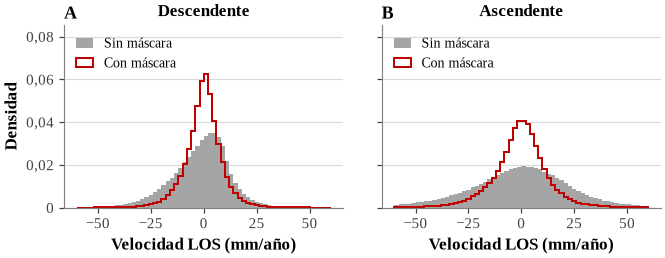

{'pct_v_menor_-20_descendente': {'sin': 9.5, 'con': 2.3}, 'pct_v_menor_-20_ascendente': {'sin': 20.3, 'con': 7.0}}


In [ ]:
fig, ejes_h = plt.subplots(1, 2, figsize=(FIG_ANCHO, 6.6 * CM), sharey=True)
for k_, (ax, nombre, orb, frs) in enumerate(zip(ejes_h, ('descendente', 'ascendente'), ('DESCENDING_R69', 'ASCENDING_R77'), (('F572',), ('F1199',)))):
    with h5py.File(f'{MP}{orb}_{frs[0]}/velocity.h5') as f:
        v = f['velocity'][()].astype('float32') * 1000; at = dict(f.attrs)
    o = np.full(S, np.nan, 'float32')
    reproject(v, o, src_transform=from_origin(float(at['X_FIRST']), float(at['Y_FIRST']), 80, 80), src_crs='EPSG:32618',
              dst_transform=T, dst_crs=CRS, src_nodata=np.nan, dst_nodata=np.nan)
    o[o == 0] = np.nan
    vl = vd if nombre == 'descendente' else va
    sin = o[DENTRO & np.isfinite(o)]; sin = sin - np.nanmedian(sin)
    con = vl[DENTRO & np.isfinite(vl)]
    bins = np.arange(-60, 61, 2)
    ax.hist(sin, bins=bins, color=GRIS, label='Sin máscara', density=True)
    ax.hist(con, bins=bins, histtype='step', color=COLOR_ROJO, lw=1.3, label='Con máscara', density=True)
    ax.set_xlabel('Velocidad LOS (mm/año)'); ax.set_title(nombre.capitalize(), pad=6); ax.legend(loc='upper left', fontsize=9, handlelength=1.2); ejes(ax)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.3f}'.rstrip('0').rstrip('.').replace('.', ',')))
    letra_panel(ax, 'AB'[k_])
    CIFRAS[f'pct_v_menor_-20_{nombre}'] = dict(sin=round(100 * float(np.mean(sin < -20)), 1), con=round(100 * float(np.mean(con < -20)), 1))
ejes_h[0].set_ylabel('Densidad'); ejes_h[0].set_ylim(0, ejes_h[0].get_ylim()[1] * 1.3)
fig.tight_layout(w_pad=2)
titulo_figura('Distribución de la velocidad en la línea de vista con y sin máscara de confiabilidad')
plt.show()
print({k: v for k, v in CIFRAS.items() if k.startswith('pct_v')})

## 7. Cruce del inventario SIMMA con la velocidad local

Se descargan del servicio del SGC los puntos del inventario y del catálogo de movimientos en masa dentro de la cuenca y se les asigna la media de la velocidad local en una ventana de 3 x 3 píxeles. Un punto se considera detectado cuando esa velocidad supera el umbral de estabilidad de la geometría descendente (13,8 mm/año).

In [ ]:
from rasterio.windows import Window
B_SIMMA = 'https://srvags.sgc.gov.co/arcgis/rest/services/SIMMA/Capas_Principales/MapServer/{}/query'
UMBRAL_V = 13.8  # 2 σ de la velocidad local descendente (notebook 1), mm/año
c4 = cuenca.to_crs(4326)
caja_c = ','.join(f'{v:.5f}' for v in c4.total_bounds)
partes = []
for capa, fuente in ((1, 'Inventario'), (5, 'Catálogo')):
    r = requests.get(B_SIMMA.format(capa), timeout=180, params=dict(where='1=1', geometry=caja_c, geometryType='esriGeometryEnvelope',
                     inSR=4326, outSR=4326, outFields='ID,TIPO,SUBTIPO', f='geojson'))
    g = gpd.read_file(io.StringIO(r.text))
    g['fuente'] = fuente
    partes.append(g[g.within(c4.geometry.iloc[0])])
simma = pd.concat(partes, ignore_index=True).to_crs(32618)


# Media de la velocidad en una ventana de 3 x 3 píxeles alrededor de cada punto
def velocidad_3x3(ruta, puntos):
    with rasterio.open(ruta) as ds:
        xy = puntos.to_crs(ds.crs).geometry
        salida = []
        for x, y in zip(xy.x, xy.y):
            f, c = ds.index(x, y)
            v = ds.read(1, window=Window(c - 1, f - 1, 3, 3), boundless=True, fill_value=np.nan).astype(float)
            if ds.nodata is not None:
                v[v == ds.nodata] = np.nan
            salida.append(np.nanmean(v) if np.isfinite(v).any() else np.nan)
    return np.array(salida)


simma['v_desc'] = velocidad_3x3(f'{GT}/mosaicos/velocidad_local_mm_anio_DESCENDING_R69_area.tif', simma)
simma['v_asc'] = velocidad_3x3(f'{GT}/mosaicos/velocidad_local_mm_anio_ASCENDING_R77_area.tif', simma)
simma['estado'] = np.select([simma.v_desc.isna(), simma.v_desc.abs() > UMBRAL_V], ['Sin dato InSAR', 'Detectado'], 'No detectado')
simma.to_file(f'{SIG}/simma_cruce_insar.gpkg', driver='GPKG')
tabla_simma = (simma.groupby(['fuente', 'TIPO', 'estado']).size().unstack(fill_value=0)
               .reindex(columns=['Detectado', 'No detectado', 'Sin dato InSAR'], fill_value=0))
tabla_simma['Total'] = tabla_simma.sum(axis=1)
tabla_simma.to_csv(f'{R}/03_resultados/tablas/simma_cruce_insar.csv')
CIFRAS['simma'] = dict(umbral=UMBRAL_V, total=len(simma), por_fuente=simma.fuente.value_counts().to_dict(),
                       por_estado=simma.estado.value_counts().to_dict())
print(CIFRAS['simma'])
print(tabla_simma.to_string())
print(simma[simma.estado == 'Detectado'].sort_values('v_desc')[['fuente', 'ID', 'TIPO', 'SUBTIPO', 'v_desc', 'v_asc']].round(1).to_string())
print(simma[simma.ID.isin([28014, 1270, 67322, 67570])][['fuente', 'ID', 'TIPO', 'v_desc', 'v_asc', 'estado']].round(1).to_string())

{'umbral': 13.8, 'total': 316, 'por_fuente': {'Catálogo': 240, 'Inventario': 76}, 'por_estado': {'No detectado': 183, 'Sin dato InSAR': 92, 'Detectado': 41}}
estado                                    Detectado  No detectado  Sin dato InSAR  Total
fuente     TIPO                                                                         
Catálogo   Caida                                  7            25              13     45
           Deformaciones gravitacionales          0             1               1      2
           Deslizamiento                         19           101              47    167
           Flujo                                  1             2               1      4
           Propagación lateral                    0             1               0      1
           Reptación                              5            12               4     21
Inventario Caida                                  0             5               4      9
           Deslizamiento                 

## 8. Delimitación de las zonas de deformación activa

Se sigue a Barra et al. (2017). Un píxel es activo cuando el valor absoluto de su velocidad local supera dos veces la desviación estándar del mapa, y los píxeles activos del mismo sentido, conectados en ocho direcciones, forman una zona si reúnen al menos cinco (3,2 ha con el píxel de 80 m). Antes se quitan los píxeles de cobertura construida y de agua permanente de WorldCover. Como prueba de sensibilidad se repite la delimitación con el umbral de estabilidad de 13,8 mm/año.

In [ ]:
# Delimitación de las ZDA (Barra et al., 2017)
from scipy import ndimage
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union

vloc = leer_tif(f'{GT}/mosaicos/velocidad_local_mm_anio_DESCENDING_R69_area.tif', Resampling.nearest)
vasc = leer_tif(f'{GT}/mosaicos/velocidad_local_mm_anio_ASCENDING_R77_area.tif', Resampling.nearest)
C_d = leer_tif(f'{Z}/indice_C_descendente.tif')
C_a = leer_tif(f'{Z}/indice_C_ascendente.tif')
pend_z = leer_tif(f'{Z}/pendiente_grados.tif')
dem_z = leer_tif(f'{Z}/dem_80m.tif')
cob_z = leer_tif(f'{SIG}/cobertura_worldcover_2021.tif', Resampling.nearest)
uni_z = list(geo.SimboloUC.unique())
geo_z = rasterize(((g, uni_z.index(s) + 1) for g, s in zip(geo.geometry, geo.SimboloUC)), out_shape=S, transform=T, fill=0)

VALIDA = DENTRO & np.isfinite(vloc)
SIGMA_MAPA = float(np.std(vloc[VALIDA]))       # desviación estándar del mapa de velocidad local
UMBRAL_ZDA = round(2 * SIGMA_MAPA, 1)           # Barra et al. (2017): |v| > 2 σ del mapa
UMBRAL_ESTABILIDAD = 13.8                       # 2 σ robusta (Actividad 2.1), prueba de sensibilidad
MIN_PX = 5                                      # Barra et al. (2017): al menos cinco puntos vecinos
EXCLUIR = (50, 80)                              # construido y agua permanente de WorldCover (Zanaga et al., 2022)
OCHO = np.ones((3, 3), int)
PX_HA = 80 * 80 / 1e4


def delimitar(umbral):
    """Etiqueta las zonas: píxeles activos del mismo sentido, conectados en ocho direcciones y con al menos MIN_PX."""
    activo = VALIDA & (np.abs(vloc) > umbral) & ~np.isin(cob_z, EXCLUIR)
    etiquetas, n = np.zeros(S, 'int32'), 0
    for signo in (-1, 1):
        lab, k = ndimage.label(activo & (np.sign(vloc) == signo), structure=OCHO)
        tam = np.bincount(lab.ravel())
        ok = np.nonzero(tam >= MIN_PX)[0]
        ok = ok[ok > 0]
        nuevo = np.zeros(k + 1, 'int32')
        nuevo[ok] = np.arange(n + 1, n + 1 + len(ok))
        etiquetas = np.where(lab > 0, nuevo[lab], etiquetas)
        n += len(ok)
    return etiquetas, n


def media_finita(a, etq, ids):
    ok = np.isfinite(a) & (etq > 0)
    s = ndimage.sum(np.where(ok, a, 0), etq, ids)
    c = ndimage.sum(ok, etq, ids)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)


def poligonos(etq, n):
    geoms = {}
    for g, v in shapes(etq, mask=etq > 0, transform=T, connectivity=8):
        geoms.setdefault(int(v), []).append(shape(g))
    ids = np.arange(1, n + 1)
    return ids, [unary_union(geoms[i]) for i in ids]


def tabla_zonas(etq, n):
    ids, geoms = poligonos(etq, n)
    n_px = ndimage.sum(etq > 0, etq, ids)
    v_med = media_finita(vloc, etq, ids)
    v_min, v_max = ndimage.minimum(vloc, etq, ids), ndimage.maximum(vloc, etq, ids)
    c_med = media_finita(C_d, etq, ids)
    v_pend = np.where(np.abs(c_med) >= 0.3, v_med / np.where(c_med == 0, np.nan, c_med), np.nan)
    unidad = [uni_z[int(np.bincount(geo_z[etq == i][geo_z[etq == i] > 0]).argmax()) - 1].replace('¿', '') if (geo_z[etq == i] > 0).any() else ''
              for i in ids]
    z = gpd.GeoDataFrame(dict(
        n_px=n_px.astype(int), area_ha=np.round(n_px * PX_HA, 1),
        v_media=np.round(v_med, 1), v_extrema=np.round(np.where(np.abs(v_min) > np.abs(v_max), v_min, v_max), 1),
        std_media=np.round(np.sqrt(np.maximum(media_finita(vloc ** 2, etq, ids) - v_med ** 2, 0)), 2),
        v_asc_media=np.round(media_finita(vasc, etq, ids), 1),
        sentido=np.where(v_med < 0, 'alejamiento', 'acercamiento'),
        pend_media=np.round(media_finita(pend_z, etq, ids), 1), alt_media=np.round(media_finita(dem_z, etq, ids), 0),
        C_desc=np.round(c_med, 2), C_asc=np.round(media_finita(C_a, etq, ids), 2),
        v_pendiente=np.round(v_pend, 1), unidad_geologica=unidad), geometry=geoms, crs=32618)
    z = z.sort_values('area_ha', ascending=False).reset_index(drop=True)
    z.insert(0, 'ZDA', [f'ZDA-{i:03d}' for i in range(1, len(z) + 1)])
    c4 = z.geometry.centroid.to_crs(4326)
    z['lon'], z['lat'] = c4.x.round(5), c4.y.round(5)
    return z


etq_zda, n_zda = delimitar(UMBRAL_ZDA)
zda = tabla_zonas(etq_zda, n_zda)
etq_sens, n_sens = delimitar(UMBRAL_ESTABILIDAD)
zda_sens = tabla_zonas(etq_sens, n_sens)

# capas de las zonas
zda.to_file(f'{Z}/zda.gpkg', driver='GPKG')
zda.drop(columns='geometry').to_csv(f'{Z}/zda.csv', index=False)
zda_sens.to_file(f'{Z}/zda_sensibilidad_umbral_13_8.gpkg', driver='GPKG')

# comparación entre los dos umbrales
dentro_sens = zda.geometry.apply(lambda g: zda_sens.intersects(g).any())
CIFRAS['zda_delimitacion'] = dict(
    sigma_mapa=round(SIGMA_MAPA, 2), umbral_zda=UMBRAL_ZDA, umbral_estabilidad=UMBRAL_ESTABILIDAD, min_px=MIN_PX, area_min_ha=MIN_PX * PX_HA,
    pixeles_validos=int(VALIDA.sum()), pct_activos=round(100 * float(np.mean(np.abs(vloc[VALIDA]) > UMBRAL_ZDA)), 1),
    n_zda=len(zda), area_zda_ha=round(float(zda.area_ha.sum()), 1), n_alejamiento=int((zda.v_media < 0).sum()), n_acercamiento=int((zda.v_media > 0).sum()),
    n_zda_13_8=len(zda_sens), area_zda_13_8_ha=round(float(zda_sens.area_ha.sum()), 1), zda_tambien_con_13_8=int(dentro_sens.sum()))
json.dump(CIFRAS['zda_delimitacion'], open(f'{Z}/zda_resumen.json', 'w'), ensure_ascii=False, indent=1)
print(CIFRAS['zda_delimitacion'])
print(zda.drop(columns='geometry').head(10).to_string(index=False))

{'sigma_mapa': 10.02, 'umbral_zda': 20.0, 'umbral_estabilidad': 13.8, 'min_px': 5, 'area_min_ha': 3.2, 'pixeles_validos': 475028, 'pct_activos': 4.1, 'n_zda': 514, 'area_zda_ha': 5595.9, 'n_alejamiento': 269, 'n_acercamiento': 245, 'n_zda_13_8': 1612, 'area_zda_13_8_ha': 17901.4, 'zda_tambien_con_13_8': 514}
    ZDA  n_px  area_ha  v_media   v_extrema  std_media  v_asc_media      sentido  pend_media  alt_media  C_desc  C_asc  v_pendiente unidad_geologica       lon     lat
ZDA-001   477    305.3    -28.8 -101.300003       7.23        -26.6  alejamiento         2.4     2065.0   -0.24   0.22          NaN          b2b6-Sm -73.41185 5.85108
ZDA-002   309    197.8    -36.9  -92.500000      16.92          6.8  alejamiento         7.2     2452.0   -0.43   0.03         85.3          b2b6-Sm -73.65040 5.78827
ZDA-003   243    155.5    -34.4  -71.000000       9.79          NaN  alejamiento         9.9     2218.0   -0.52   0.04         66.1          b2b6-Sm -73.81452 5.78524
ZDA-004   224    143.4

## 9. Medición y clasificación de las zonas

Para cada zona se leen las series de sus píxeles hasta diciembre de 2025 y se calcula el índice de calidad de Barra et al. (2017): el ruido temporal (TNI) con la mediana de la autocorrelación de primer orden y el ruido espacial (SNI) con la mediana de la correlación entre las series. La clase final es la menos favorable de las dos. La serie media se clasifica como no correlacionada, lineal o no lineal (Berti et al., 2013). La velocidad ladera abajo se clasifica con la escala de Cruden y Varnes (1996) y el proceso con los criterios de Navarro et al. (2020) y Notti et al. (2014).

In [ ]:
# Medición y clasificación de las ZDA
from scipy import stats

FIN_SERIE = pd.Timestamp('2025-12-31')        # mismo intervalo del ajuste de la velocidad descendente


def series_zona(g):
    """Series (mm) de los píxeles de una zona en el frame descendente que la cubre, hasta FIN_SERIE."""
    for fr in ('F572', 'F567'):
        with h5py.File(f'{MP}DESCENDING_R69_{fr}/timeseries_SET_ERA5_ramp_demErr.h5') as f:
            at = dict(f.attrs); fechas = pd.to_datetime([d.decode() for d in f['date'][()]])
            tr = from_origin(float(at['X_FIRST']), float(at['Y_FIRST']), 80, 80); L, Wd = f['timeseries'].shape[1:]
            gb = g.bounds; a0, b0 = rowcol(tr, gb[0], gb[3]); a1, b1 = rowcol(tr, gb[2], gb[1])
            if a0 < 0 or b0 < 0 or a1 >= L or b1 >= Wd:
                continue
            k = fechas <= FIN_SERIE
            sub = f['timeseries'][:, a0:a1 + 1, b0:b1 + 1][k]
        m = geometry_mask([g], out_shape=sub.shape[1:], transform=from_origin(tr.c + b0 * 80, tr.f - a0 * 80, 80, 80), invert=True, all_touched=False)
        px = sub[:, m] * 1000
        ok = np.all(np.isfinite(px), axis=0) & (np.abs(px).sum(axis=0) > 0)
        if ok.sum() >= 3:
            px = px[:, ok]
            return fechas[k], px - px[0]
    return None


def autocorr1(y):
    y = y - y.mean()
    return float(np.sum(y[1:] * y[:-1]) / np.sum(y * y)) if np.sum(y * y) > 0 else np.nan


def tendencia_berti(t, y):
    """Clase de la serie media: no correlacionada, lineal o no lineal (pruebas F de la recta y de la parábola)."""
    n = len(y)
    r1 = stats.linregress(t, y)
    if r1.pvalue >= 0.05:
        return 'no correlacionada'
    sse1 = np.sum((y - (r1.intercept + r1.slope * t)) ** 2)
    sse2 = np.sum((y - np.polyval(np.polyfit(t, y, 2), t)) ** 2)
    f = (sse1 - sse2) / (sse2 / (n - 3))
    return 'no lineal' if stats.f.sf(f, 1, n - 3) < 0.05 and (sse1 - sse2) / sse1 > 0.1 else 'lineal'


filas = []
for _, z in zda.iterrows():
    r_ = series_zona(z.geometry)
    if r_ is None:
        filas.append(dict(rho_med=np.nan, corr_med=np.nan, tendencia='sin serie', v_serie=np.nan, n_serie=0)); continue
    fechas, px = r_
    t = ((fechas - fechas[0]).days / 365.25).to_numpy()
    rho = np.nanmedian([autocorr1(px[:, j]) for j in range(px.shape[1])])
    cc = np.corrcoef(px.T)
    corr = float(np.nanmedian(cc[np.triu_indices_from(cc, 1)]))
    mu = px.mean(axis=1)
    filas.append(dict(rho_med=round(float(rho), 3), corr_med=round(corr, 3), tendencia=tendencia_berti(t, mu),
                      v_serie=round(float(np.polyfit(t, mu, 1)[0]), 1), n_serie=int(px.shape[1])))
zda = pd.concat([zda.reset_index(drop=True), pd.DataFrame(filas)], axis=1)

# índice de calidad (Barra et al., 2017): ruido temporal (TNI) y espacial (SNI); la clase final es la menos favorable
zda['TNI'] = np.select([zda.rho_med > 0.84, zda.rho_med > 0.70, zda.rho_med > 0.53], [1, 2, 3], 4)
q = zda.corr_med.quantile([0.02, 0.25, 0.75])
zda['SNI'] = np.select([zda.corr_med > q[0.75], zda.corr_med > q[0.25], zda.corr_med > q[0.02]], [1, 2, 3], 4)
zda['calidad'] = np.where(zda.n_serie > 0, np.maximum(zda.TNI, zda.SNI), 4)

# clase de velocidad (Barra et al., 2017) y escala de Cruden y Varnes (1996) para la velocidad ladera abajo
zda['clase_velocidad'] = np.where(zda.v_extrema.abs() > 10, 1, 0)
zda['velocidad_cv'] = np.select([zda.v_pendiente.abs() < 16, zda.v_pendiente.abs() < 1600], ['Extremadamente lenta', 'Muy lenta'], 'Sin proyección')
zda.loc[zda.v_pendiente.isna(), 'velocidad_cv'] = 'Sin proyección'

# proceso probable (Navarro et al., 2020; Notti et al., 2014)
cuaternario = zda.unidad_geologica.str.startswith('Q')
ladera = (zda.C_desc.abs() >= 0.3) & (zda.v_pendiente > 0)
asc_contra = (zda.C_asc.abs() >= 0.3) & (zda.v_asc_media.abs() > 20.7) & (np.sign(zda.v_asc_media) != np.sign(zda.C_asc))
clase = np.select(
    [zda.calidad >= 3, asc_contra, (zda.pend_media > 5) & ladera, (zda.pend_media < 10) & cuaternario, zda.pend_media > 5],
    ['Por verificar', 'Por verificar', 'Movimiento en masa probable', 'Subsidencia o asentamiento probable', 'Movimiento en masa posible'],
    'Por verificar')
motivo = np.select(
    [zda.calidad >= 3, asc_contra, (zda.pend_media > 5) & ladera, (zda.pend_media < 10) & cuaternario, zda.pend_media > 5],
    ['calidad 3 o 4', 'la geometría ascendente contradice', 'pendiente > 5°, |C| ≥ 0,3 y sentido ladera abajo',
     'pendiente < 10° sobre depósitos cuaternarios', 'pendiente > 5° sin sensibilidad o sentido compatible'],
    'pendiente ≤ 5° fuera de depósitos cuaternarios')
zda['clase'], zda['motivo'] = clase, motivo
zda['clase_final'] = zda.clase
zda.to_file(f'{Z}/zda.gpkg', driver='GPKG')
zda.drop(columns='geometry').to_csv(f'{Z}/zda.csv', index=False)

CIFRAS['zda_clasificacion'] = dict(
    calidad=zda.calidad.value_counts().sort_index().to_dict(), tendencia=zda.tendencia.value_counts().to_dict(),
    clase=zda.clase.value_counts().to_dict(), motivo=zda.motivo.value_counts().to_dict(),
    velocidad_cv=zda.velocidad_cv.value_counts().to_dict(), clase_velocidad=zda.clase_velocidad.value_counts().to_dict(),
    area_por_clase_ha=zda.groupby('clase').area_ha.sum().round(1).to_dict(), cuartiles_sni=[round(float(v), 3) for v in q])
print(json.dumps(CIFRAS['zda_clasificacion'], ensure_ascii=False, indent=1, default=int))
print(zda[zda.clase == 'Movimiento en masa probable'].sort_values('v_pendiente', ascending=False)
      [['ZDA', 'area_ha', 'v_media', 'v_pendiente', 'velocidad_cv', 'calidad', 'tendencia', 'pend_media', 'unidad_geologica']].head(15).to_string(index=False))

{
 "calidad": {
  "1": 125,
  "2": 244,
  "3": 117,
  "4": 28
 },
 "tendencia": {
  "no lineal": 326,
  "lineal": 188
 },
 "clase": {
  "Por verificar": 197,
  "Movimiento en masa probable": 180,
  "Movimiento en masa posible": 123,
  "Subsidencia o asentamiento probable": 14
 },
 "motivo": {
  "pendiente > 5°, |C| ≥ 0,3 y sentido ladera abajo": 180,
  "calidad 3 o 4": 145,
  "pendiente > 5° sin sensibilidad o sentido compatible": 123,
  "pendiente ≤ 5° fuera de depósitos cuaternarios": 45,
  "pendiente < 10° sobre depósitos cuaternarios": 14,
  "la geometría ascendente contradice": 7
 },
 "velocidad_cv": {
  "Muy lenta": 324,
  "Sin proyección": 190
 },
 "clase_velocidad": {
  "1": 514
 },
 "area_por_clase_ha": {
  "Movimiento en masa posible": 1103.4,
  "Movimiento en masa probable": 2280.1,
  "Por verificar": 1933.9,
  "Subsidencia o asentamiento probable": 278.5
 },
 "cuartiles_sni": [
  0.826,
  0.943,
  0.987
 ]
}
    ZDA  area_ha  v_media  v_pendiente velocidad_cv  calidad tende

## 10. Cruces con el SIMMA y la amenaza, y zonas críticas

Una zona coincide con el SIMMA cuando contiene un punto del inventario o del catálogo, o lo tiene a menos de 80 m (un píxel). La significancia se evalúa con una prueba binomial frente a la fracción del área medida que ocupan las zonas. Se revisa además cuántos puntos detectados que se acercan al satélite están junto a cobertura construida. La amenaza 1:100 000 (SGC, 2017) se toma de los mapas departamentales de Boyacá y Santander que publica el SGC. Zona crítica: movimiento en masa probable, velocidad clase 1, calidad 1 o 2, serie lineal y amenaza alta o muy alta o coincidencia con el SIMMA.

In [ ]:
# Cruces con el SIMMA y la amenaza, y zonas críticas
from scipy.stats import binomtest

# puntos del inventario y del catálogo del SIMMA con su estado frente al InSAR (sección del cruce puntual)
B_SIMMA = 'https://srvags.sgc.gov.co/arcgis/rest/services/SIMMA/Capas_Principales/MapServer/{}/query'
c4 = cuenca.to_crs(4326)
partes = []
for capa, fuente in ((1, 'Inventario'), (5, 'Catálogo')):
    r = requests.get(B_SIMMA.format(capa), timeout=180, params=dict(where='1=1', geometry=','.join(f'{v:.5f}' for v in c4.total_bounds),
                     geometryType='esriGeometryEnvelope', inSR=4326, outSR=4326, outFields='ID,TIPO,SUBTIPO', f='geojson'))
    g = gpd.read_file(io.StringIO(r.text)); g['fuente'] = fuente
    partes.append(g[g.within(c4.geometry.iloc[0])])
pts = pd.concat(partes, ignore_index=True).to_crs(32618)

# coincidencia: el punto cae dentro de la zona o a menos de un píxel (80 m)
buf = zda[['ZDA', 'geometry']].copy(); buf['geometry'] = buf.buffer(80)
cruce = gpd.sjoin(pts, buf, predicate='within', how='inner')
por_zona = cruce.groupby('ZDA').agg(simma_n=('ID', 'size'), simma_tipos=('TIPO', lambda s: ', '.join(sorted(set(s.dropna())))))
zda = zda.drop(columns=[c for c in ('simma_n', 'simma_tipos') if c in zda]).merge(por_zona, on='ZDA', how='left')
zda['simma_n'] = zda.simma_n.fillna(0).astype(int); zda['simma_tipos'] = zda.simma_tipos.fillna('')

# prueba binomial: puntos con dato InSAR que caen en las zonas frente a la fracción del área medida que ocupan
con_dato = np.isfinite(np.array([vloc[rowcol(T, x, y)] if 0 <= rowcol(T, x, y)[0] < S[0] and 0 <= rowcol(T, x, y)[1] < S[1] else np.nan
                                  for x, y in zip(pts.geometry.x, pts.geometry.y)]))
zona_r = rasterize(((g, 1) for g in buf.geometry), out_shape=S, transform=T, fill=0).astype(bool)
p0 = float((zona_r & VALIDA).sum() / VALIDA.sum())
k_in = int(pts[con_dato].geometry.apply(lambda p: buf.contains(p).any()).sum())
n_dato = int(con_dato.sum())
prueba = binomtest(k_in, n_dato, p0, alternative='greater')

# puntos detectados que se acercan al satélite: ¿están en cobertura construida o junto a ella?
cruce_pts = gpd.read_file(f'{SIG}/simma_cruce_insar.gpkg').to_crs(32618)
det_acerca = cruce_pts[(cruce_pts.estado == 'Detectado') & (cruce_pts.v_desc > 0)]
def construido_cerca(p, r_px=1):
    f_, c_ = rowcol(T, p.x, p.y)
    return bool((cob_z[max(f_ - r_px, 0):f_ + r_px + 1, max(c_ - r_px, 0):c_ + r_px + 1] == 50).any())
n_urbano = int(det_acerca.geometry.apply(construido_cerca).sum())

# amenaza por movimientos en masa 1:100 000 (SGC, 2017): mapas departamentales en formato raster del SGC
import zipfile, subprocess, re
AM_DIR = f'{R}/01_datos/amenaza_mm_100k'
os.makedirs(AM_DIR, exist_ok=True)
NOMBRE_AM = {2: 'Baja', 3: 'Media', 4: 'Alta', 5: 'Muy alta'}
amen = np.zeros(S, 'uint8')
for dep in ('Boyaca', 'Santander'):
    zp = f'{AM_DIR}/{dep}.zip'
    if not os.path.exists(zp):
        u = f'https://www2.sgc.gov.co/sgc/mapas/Documents/Descargables%20Mapa%20de%20Amenaza/{dep}.zip'
        open(zp, 'wb').write(requests.get(u, timeout=900).content)
    zipfile.ZipFile(zp).extractall(AM_DIR)
    ruta = f'{AM_DIR}/{dep.lower()}/{dep.lower()}'
    info = subprocess.run(['gdalinfo', ruta], capture_output=True).stdout.decode('latin-1')
    tabla = {}
    for fila in re.findall(r'<Row index="[0-9]+">(.*?)</Row>', info, flags=re.S):
        campos = [a or '' for a in re.findall(r'<F>(.*?)</F>|<F */>', fila)]
        tabla[int(campos[0])] = int(campos[14][0])          # VALUE y CATAME ("5. Muy Alta")
    with rasterio.open(ruta) as r:
        a = r.read(1)
        lut = np.zeros(max(tabla) + 1, 'uint8')
        lut[list(tabla)] = list(tabla.values())
        cat = np.where((a > 0) & (a <= max(tabla)), lut[np.clip(a, 0, max(tabla))], 0).astype('uint8')
        o = np.zeros(S, 'uint8')
        reproject(cat, o, src_transform=r.transform, src_crs=r.crs, dst_transform=T, dst_crs=CRS, src_nodata=0, dst_nodata=0, resampling=Resampling.nearest)
    amen = np.where(amen == 0, o, amen)
guardar_tif(amen, 'amenaza_mm_100k', nodata=0, tipo='uint8')
ids_z = rasterize(((g, i + 1) for i, g in enumerate(zda.geometry)), out_shape=S, transform=T, fill=0)
moda = []
for i in range(1, len(zda) + 1):
    v = amen[(ids_z == i) & (amen > 0)]
    moda.append(NOMBRE_AM.get(int(np.bincount(v).argmax()), 'Sin dato') if v.size else 'Sin dato')
zda['amenaza'] = moda
amenaza_alta = zda.amenaza.isin(['Alta', 'Muy alta'])
area_am = {NOMBRE_AM[k]: round(100 * float(np.sum(DENTRO & (amen == k)) / np.sum(DENTRO & (amen > 0))), 1) for k in NOMBRE_AM}
zona_am = {NOMBRE_AM[k]: round(100 * float(np.sum((ids_z > 0) & (amen == k)) / np.sum((ids_z > 0) & (amen > 0))), 1) for k in NOMBRE_AM}
CIFRAS['amenaza'] = dict(area_cuenca_pct=area_am, area_zonas_pct=zona_am, zonas_por_amenaza=zda.amenaza.value_counts().to_dict())
print(CIFRAS['amenaza'])

# zonas críticas
zda['critica'] = ((zda.clase == 'Movimiento en masa probable') & (zda.clase_velocidad == 1) & (zda.calidad <= 2)
                  & (zda.tendencia == 'lineal') & (amenaza_alta | (zda.simma_n > 0)))
zda.to_file(f'{Z}/zda.gpkg', driver='GPKG')
zda.drop(columns='geometry').to_csv(f'{Z}/zda.csv', index=False)

CIFRAS['zda_cruces'] = dict(
    simma_puntos=len(pts), simma_con_dato=n_dato, simma_en_zonas=k_in, fraccion_area_zonas=round(p0, 4),
    esperados=round(n_dato * p0, 1), p_binomial=float(f'{prueba.pvalue:.2g}'), zonas_con_simma=int((zda.simma_n > 0).sum()),
    zonas_con_simma_por_clase=zda[zda.simma_n > 0].clase.value_counts().to_dict(),
    detectados_acercamiento=len(det_acerca), detectados_acercamiento_junto_a_construido=n_urbano,
    criticas=int(zda.critica.sum()))
print(json.dumps(CIFRAS['zda_cruces'], ensure_ascii=False, indent=1))
print(zda[zda.critica].sort_values('v_pendiente', ascending=False)
      [['ZDA', 'area_ha', 'v_media', 'v_pendiente', 'calidad', 'simma_n', 'simma_tipos', 'amenaza', 'unidad_geologica', 'lat', 'lon']].to_string(index=False))

# cruce puntual sin el residuo urbano: se quitan los puntos en cobertura construida o junto a ella
junto = cruce_pts.geometry.apply(construido_cerca)
con_d = cruce_pts.estado != 'Sin dato InSAR'
k_det = int(((cruce_pts.estado == 'Detectado') & con_d & ~junto).sum())
n_d = int((con_d & ~junto).sum())
urbano = ndimage.binary_dilation(cob_z == 50, structure=OCHO)
fondo = float(np.mean(np.abs(vloc[VALIDA & ~urbano]) > UMBRAL_ESTABILIDAD))
pb = binomtest(k_det, n_d, fondo, alternative='greater')
CIFRAS['simma_sin_urbano'] = dict(puntos_con_dato=n_d, detectados=k_det, pct=round(100 * k_det / n_d, 1), fondo_pct=round(100 * fondo, 1),
                                  razon=round(k_det / n_d / fondo, 2), p_binomial=float(f'{pb.pvalue:.2g}'), quitados_junto_construido=int((con_d & junto).sum()),
                                  acercamiento=int(((cruce_pts.estado == 'Detectado') & ~junto & (cruce_pts.v_desc > 0)).sum()))
tipo_su = cruce_pts[con_d & ~junto].groupby('TIPO').estado.apply(lambda s: f"{(s == 'Detectado').sum()} de {len(s)}")
print(CIFRAS['simma_sin_urbano']); print(tipo_su.to_string())

{'area_cuenca_pct': {'Baja': 0.4, 'Media': 32.8, 'Alta': 59.9, 'Muy alta': 6.9}, 'area_zonas_pct': {'Baja': 0.8, 'Media': 46.7, 'Alta': 46.3, 'Muy alta': 6.2}, 'zonas_por_amenaza': {'Alta': 279, 'Media': 216, 'Muy alta': 14, 'Baja': 5}}
{
 "simma_puntos": 316,
 "simma_con_dato": 192,
 "simma_en_zonas": 12,
 "fraccion_area_zonas": 0.0449,
 "esperados": 8.6,
 "p_binomial": 0.16,
 "zonas_con_simma": 9,
 "zonas_con_simma_por_clase": {
  "Movimiento en masa posible": 4,
  "Movimiento en masa probable": 3,
  "Por verificar": 2
 },
 "detectados_acercamiento": 35,
 "detectados_acercamiento_junto_a_construido": 22,
 "criticas": 38
}
    ZDA  area_ha  v_media  v_pendiente  calidad  simma_n   simma_tipos  amenaza unidad_geologica     lat       lon
ZDA-006     90.2    -40.4        115.5        1        0               Muy alta          b2b6-Sm 5.79818 -73.78747
ZDA-122      9.0    -40.7         94.0        2        0                   Alta          b2b6-Sm 5.82310 -73.64842
ZDA-082     11.5    -36

## 11. Zonas críticas: municipio, mapa, series y capas para el SIG

Las zonas críticas se ordenan por su velocidad ladera abajo y se les asigna el municipio con la capa municipal del Mapa Nacional de Amenaza del SGC. Se presentan en un mapa sobre la amenaza alta y muy alta, con las series de las seis más rápidas, y se empaquetan las capas para el SIG en zda_para_SIG.zip.

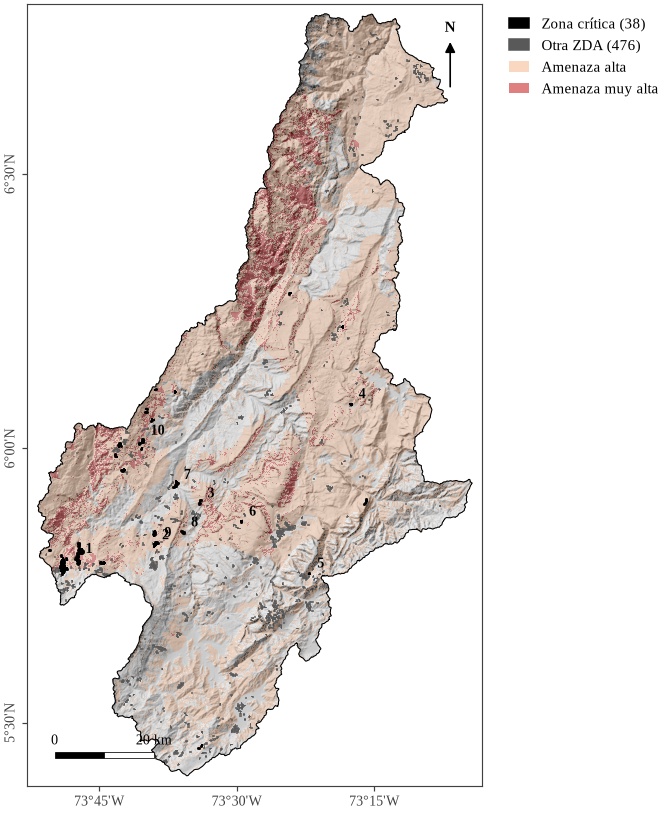

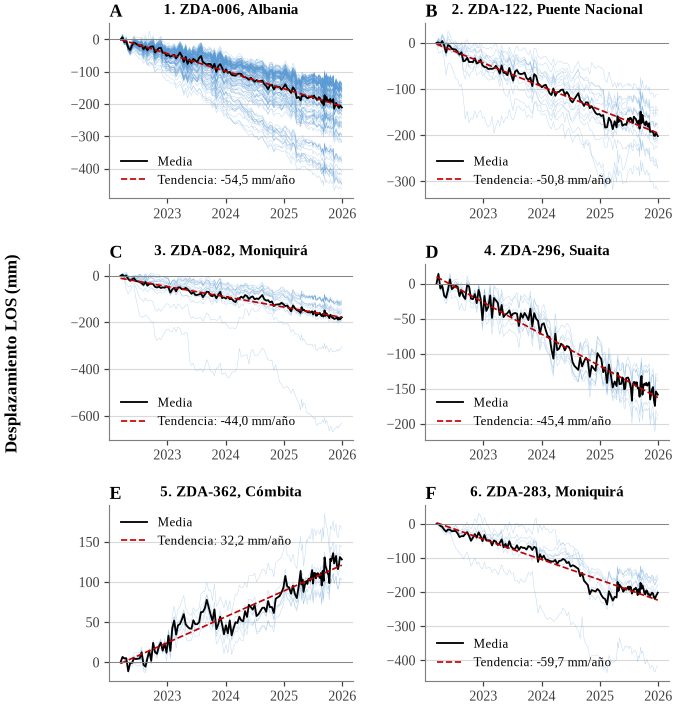

{'n': 38, 'area_ha': 674.4, 'municipios': {'Albania': 8, 'Puente Nacional': 5, 'Vélez': 5, 'Chipatá': 5, 'Moniquirá': 4, 'Samacá': 2, 'Gámbita': 2, 'Suaita': 1, 'Cómbita': 1, 'Barbosa': 1, 'Guavatá': 1, 'Jesús Maria': 1, 'Guadalupe': 1, 'Oiba': 1}, 'alejamiento': 25, 'acercamiento': 13}
 n     ZDA                   municipio  area_ha  v_media  v_pendiente  calidad tendencia  amenaza  simma_n unidad_geologica  pend_media     lat       lon
 1 ZDA-006         Albania (Santander)     90.2    -40.4        115.5        1    lineal Muy alta        0          b2b6-Sm         7.7 5.79818 -73.78747
 2 ZDA-122 Puente Nacional (Santander)      9.0    -40.7         94.0        2    lineal     Alta        0          b2b6-Sm         9.4 5.82310 -73.64842
 3 ZDA-082          Moniquirá (Boyacá)     11.5    -36.3         91.0        2    lineal     Alta        0          b2b6-Sm         8.6 5.89888 -73.56567
 4 ZDA-296          Suaita (Santander)      4.5    -27.4         86.2        2    lineal     Alt

In [ ]:
# Zonas críticas: municipio, mapa, series y capas para el SIG
import zipfile
from matplotlib.colors import LightSource

crit = zda[zda.critica].sort_values('v_pendiente', ascending=False).reset_index(drop=True)
url_m = 'https://srvags.sgc.gov.co/arcgis/rest/services/Mapa_Nacional_Amenaza_Mov_Masa_100K/Mapa_Nacional_Amenaza_Movimientos_Masa_100K/FeatureServer/1/query'
jm = requests.get(url_m, timeout=180, params=dict(where='1=1', geometry=','.join(f'{v:.4f}' for v in c4.total_bounds), geometryType='esriGeometryEnvelope',
                                                 inSR=4326, outSR=4326, outFields='MUNICIPIO,DEPARTAMEN', f='geojson')).json()
mun = gpd.GeoDataFrame.from_features(jm['features'], crs=4326).to_crs(32618)
dentro_m = [mun[mun.contains(g.centroid)] for g in crit.geometry]
crit['municipio'] = [f'{m.MUNICIPIO.iloc[0].title()} ({m.DEPARTAMEN.iloc[0].title()})' if len(m) else '' for m in dentro_m]
crit.insert(1, 'n', range(1, len(crit) + 1))
crit.to_file(f'{SIG}/zonas_criticas.gpkg', driver='GPKG')
crit.drop(columns='geometry').to_csv(f'{Z}/zonas_criticas.csv', index=False)

# mapa: zonas por clase, zonas críticas numeradas y amenaza alta y muy alta del SGC
sombra_c = LightSource(azdeg=315, altdeg=45).hillshade(np.nan_to_num(dem_z, nan=np.nanmean(dem_z)), vert_exag=2, dx=80, dy=80)
ANCHO_C = 10.5 * CM
fig = plt.figure(figsize=(FIG_ANCHO, ANCHO_C * ASPECTO + 1.0 * CM))
ax = fig.add_axes([1.1 * CM / FIG_ANCHO, 0.5 * CM / fig.get_figheight(), ANCHO_C / FIG_ANCHO, ANCHO_C * ASPECTO / fig.get_figheight()])
ax.imshow(np.where(DENTRO, sombra_c, np.nan)[r0:r1, c0:c1], extent=EXT, cmap='Greys_r', vmin=0.1, vmax=1.15, interpolation='bilinear', zorder=1)
am_r = np.where(DENTRO & (amen >= 4), amen, np.nan)[r0:r1, c0:c1]
ax.imshow(am_r, extent=EXT, cmap=ListedColormap(['#F4B183', '#C00000']), vmin=3.5, vmax=5.5, alpha=0.35, interpolation='nearest', zorder=2)
marco_mapa(ax, norte=True)
zda[~zda.critica].plot(ax=ax, color='#595959', ec='#595959', lw=0.4, zorder=4)
crit.plot(ax=ax, color='black', ec='black', lw=1.2, zorder=5)
for _, z in crit.head(10).iterrows():
    c_ = z.geometry.centroid
    ax.annotate(str(z.n), (c_.x, c_.y), xytext=(5, 4), textcoords='offset points', fontsize=9, fontweight='bold', zorder=6)
ax.set_xlabel(''); ax.set_ylabel('')
ax.legend(handles=[Patch(fc='black', ec='black', label=f'Zona crítica ({len(crit)})'), Patch(fc='#595959', ec='#595959', label=f'Otra ZDA ({(~zda.critica).sum()})'),
                   Patch(fc='#F4B183', alpha=0.5, label='Amenaza alta'), Patch(fc='#C00000', alpha=0.5, label='Amenaza muy alta')],
          loc='upper left', bbox_to_anchor=(1.03, 1.0), fontsize=10, alignment='left', handlelength=1.3)
titulo_figura('Zonas críticas de deformación activa y amenaza por movimientos en masa en la cuenca media y baja del río Suárez')
plt.show()

# series de las seis zonas críticas con mayor velocidad ladera abajo
fig, ejes_c = plt.subplots(3, 2, figsize=(FIG_ANCHO, 17 * CM))
for k_, (ax, (_, z)) in enumerate(zip(ejes_c.ravel(), crit.head(6).iterrows())):
    r_ = series_zona(z.geometry)
    fechas, px = r_
    t = ((fechas - fechas[0]).days / 365.25).to_numpy()
    mu = px.mean(axis=1); p = np.polyfit(t, mu, 1)
    ax.plot(fechas, mu, color='black', lw=1.2, label='Media')
    ax.plot(fechas, np.polyval(p, t), '--', color=COLOR_ROJO, lw=1.1, label=f'Tendencia: {fmt(p[0])} mm/año')
    ax.axhline(0, color='#7F7F7F', lw=0.6); ejes(ax); eje_anios(ax); ax.tick_params(labelsize=9)
    ax.set_title(f'{z.n}. {z.ZDA}, {z.municipio.split(" (")[0]}', pad=6, fontsize=10)
    ax.legend(loc='lower left' if p[0] < 0 else 'upper left', fontsize=8.5)
    letra_panel(ax, 'ABCDEF'[k_])
fig.supylabel('Desplazamiento LOS (mm)', fontsize=11, fontweight='bold', x=0.01)
fig.tight_layout(rect=(0.03, 0, 1, 1), h_pad=1.4, w_pad=1.8)
titulo_figura('Series de desplazamiento de las seis zonas críticas con mayor velocidad ladera abajo')
plt.show()

# capas para el SIG
with zipfile.ZipFile(f'{R}/03_resultados/zda_para_SIG.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for ruta in (f'{Z}/zda.gpkg', f'{Z}/zda_sensibilidad_umbral_13_8.gpkg', f'{SIG}/zonas_criticas.gpkg', f'{SIG}/fallas_sgc2023.gpkg',
                 f'{SIG}/simma_cruce_insar.gpkg', f'{SIG}/amenaza_mm_100k.tif', f'{SIG}/cobertura_worldcover_2021.tif',
                 f'{GT}/mosaicos/velocidad_local_mm_anio_DESCENDING_R69_area.tif'):
        if os.path.exists(ruta):
            zf.write(ruta, os.path.basename(ruta))

CIFRAS['zonas_criticas'] = dict(n=len(crit), area_ha=round(float(crit.area_ha.sum()), 1), municipios=crit.municipio.str.split(' \\(').str[0].value_counts().to_dict(),
                                alejamiento=int((crit.v_media < 0).sum()), acercamiento=int((crit.v_media > 0).sum()))
print(CIFRAS['zonas_criticas'])
print(crit[['n', 'ZDA', 'municipio', 'area_ha', 'v_media', 'v_pendiente', 'calidad', 'tendencia', 'amenaza', 'simma_n', 'unidad_geologica', 'pend_media', 'lat', 'lon']].to_string(index=False))

## 12. Fichas de las zonas de deformación activa

Una página por zona con la vista en perspectiva del relieve (imagen satelital y velocidad local de los píxeles de las ZDA), la localización con el rumbo del satélite y la línea de vista, los mapas de velocidad, pendiente, unidad geológica y amenaza, la serie media con su tendencia y una tabla con los datos de la clasificación. El archivo resultante, `03_resultados/fichas_zonas_deformacion_activa.pdf`, es el Apéndice C del documento. Cada página se guarda aparte y al final se unen; si la corrida se detiene por memoria, basta con repetir la celda, que sigue desde la última página guardada.

In [ ]:
# Fichas de las zonas de deformación activa (Apéndice C): una por página
import math, io
from PIL import Image
from shapely.geometry import box as caja_geo
from matplotlib.colors import ListedColormap, BoundaryNorm, LightSource
from scipy.ndimage import zoom as ampliar
from pyproj import Transformer

NOM_COB = {10: 'Bosque', 20: 'Arbustal', 30: 'Herbazal y pastos', 40: 'Cultivos', 50: 'Construido', 60: 'Suelo desnudo', 80: 'Agua', 90: 'Humedal'}
ids_f = rasterize(((g, i + 1) for i, g in enumerate(zda.geometry)), out_shape=S, transform=T, fill=0)
en_mun = gpd.sjoin(gpd.GeoDataFrame(zda[['ZDA']], geometry=zda.geometry.centroid, crs=32618), mun[['MUNICIPIO', 'DEPARTAMEN', 'geometry']], predicate='within', how='left').drop_duplicates('ZDA').set_index('ZDA')
zda['municipio'] = [f'{en_mun.MUNICIPIO[z].title()} ({en_mun.DEPARTAMEN[z].title()})' if isinstance(en_mun.MUNICIPIO[z], str) else '' for z in zda.ZDA]
zda['cobertura'] = [NOM_COB.get(int(np.bincount(cob_z[(ids_f == i + 1) & (cob_z > 0)].astype(int)).argmax()), '') if ((ids_f == i + 1) & (cob_z > 0)).any() else '' for i in range(len(zda))]
orden_crit = {z: n for z, n in zip(crit.ZDA, crit.n)}
a_3857 = Transformer.from_crs(32618, 3857, always_xy=True)
a_32618 = Transformer.from_crs(3857, 32618, always_xy=True)
COL_AM = ListedColormap(['#70AD47', '#FFE699', '#ED7D31', '#C00000']); NORM_AM = BoundaryNorm([1.5, 2.5, 3.5, 4.5, 5.5], 4)
with h5py.File(f'{MP}DESCENDING_R69_F572/timeseries_SET_ERA5_ramp_demErr.h5') as f_:
    RUMBO = float(f_.attrs['HEADING']) % 360
inc_r = leer_tif(f'{GT}/suarez_2024_2026_v1_DESCENDING_R69_F572/incidencia_grados.tif')
def INC_Z(g):
    m_ = geometry_mask([g], out_shape=S, transform=T, invert=True)
    v_ = inc_r[m_ & np.isfinite(inc_r)]
    return float(np.nanmean(v_)) if v_.size else float(np.nanmean(inc_r))
PAL_GEO = ['#A6CEE3', '#B2DF8A', '#FDBF6F', '#CAB2D6', '#FFFF99', '#FB9A99', '#8DD3C7', '#BEBADA', '#D9D9D9', '#CCEBC5']


def satelite(x0, y0, x1, y1, z=15):
    """Mosaico de Esri World Imagery para una caja en EPSG:32618; devuelve la imagen y su extensión en 3857."""
    xs, ys = a_3857.transform([x0, x1, x0, x1], [y0, y0, y1, y1])
    n = 2 ** z; R0 = 6378137 * math.pi
    tile = lambda xm, ym: (int((xm + R0) / (2 * R0) * n), int((R0 - ym) / (2 * R0) * n))
    tx0, ty0 = tile(min(xs), max(ys)); tx1, ty1 = tile(max(xs), min(ys))
    im = Image.new('RGB', ((tx1 - tx0 + 1) * 256, (ty1 - ty0 + 1) * 256))
    for tx in range(tx0, tx1 + 1):
        for ty in range(ty0, ty1 + 1):
            for _ in range(3):
                try:
                    r = requests.get(f'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{ty}/{tx}', timeout=30)
                    im.paste(Image.open(io.BytesIO(r.content)).convert('RGB'), ((tx - tx0) * 256, (ty - ty0) * 256)); break
                except Exception:
                    pass
    t = 2 * R0 / n
    return np.asarray(im) / 255, (-R0 + tx0 * t, -R0 + (tx1 + 1) * t, R0 - (ty1 + 1) * t, R0 - ty0 * t)


def muestrear(img, ext3857, X, Y):
    """Color de la imagen satelital en las coordenadas UTM X, Y."""
    xm, ym = a_3857.transform(X.ravel(), Y.ravel())
    h, w = img.shape[:2]
    cc = np.clip(((np.array(xm) - ext3857[0]) / (ext3857[1] - ext3857[0]) * w).astype(int), 0, w - 1)
    ff = np.clip(((ext3857[3] - np.array(ym)) / (ext3857[3] - ext3857[2]) * h).astype(int), 0, h - 1)
    return img[ff, cc].reshape(X.shape + (3,))


EDAD_COL = {'Q': ['#E0E0E0', '#C8C8C8'], 'N': ['#FFE84D', '#F5D000'], 'E': ['#F7A35C', '#E8853A'], 'k': ['#B8E186', '#9ACD5A'],
            'b': ['#7FBF4D', '#5FA03A'], 'J': ['#8FC7E8', '#6AAFD8'], 'T': ['#5B8FD0', '#3A6FB0']}
_cuenta = {}
COLGEO = {}
for u_, sim_ in enumerate(uni_z, start=1):
    k_ = sim_[0] if sim_[0] in EDAD_COL else 'otro'
    pal_ = EDAD_COL.get(k_, ['#C9A6D9', '#A68AC4', '#B07A5A'])
    COLGEO[u_] = pal_[_cuenta.get(k_, 0) % len(pal_)]; _cuenta[k_] = _cuenta.get(k_, 0) + 1


def caja_cm(fig, x, y_top, w, h, **kw):
    W_, H_ = fig.get_size_inches() / CM
    return fig.add_axes([x / W_, 1 - (y_top + h) / H_, w / W_, h / H_], **kw)


def texto_cm(fig, x, y_top, s, **kw):
    W_, H_ = fig.get_size_inches() / CM
    return fig.text(x / W_, 1 - y_top / H_, s, **kw)


def ficha(z):
    numero = int(z.ZDA.split('-')[1])
    fig = plt.figure(figsize=(21.59 * CM, 27.94 * CM))
    ML = 2.0
    texto_cm(fig, ML, 1.6, f'Ficha C{numero}', fontsize=11, fontweight='bold', va='top')
    sub = f'{z.clase}' + (f', zona crítica n.º {orden_crit[z.ZDA]}' if z.ZDA in orden_crit else '')
    texto_cm(fig, ML, 2.2, f'Zona de deformación activa {z.ZDA}, {z.municipio}: {sub[0].lower() + sub[1:]}', fontsize=11, style='italic', va='top')

    # ventana de 4 km (o más si la zona es grande) centrada en la zona
    c = z.geometry.centroid; b = z.geometry.bounds
    h = max(2000, 0.8 * max(b[2] - b[0], b[3] - b[1]))
    f0, k0 = rowcol(T, c.x - h, c.y + h); f1, k1 = rowcol(T, c.x + h, c.y - h)
    f0, k0 = max(f0, 0), max(k0, 0)
    ext = (T.c + k0 * 80, T.c + k1 * 80, T.f - f1 * 80, T.f - f0 * 80)
    vec = zda[zda.intersects(caja_geo(ext[0], ext[2], ext[1], ext[3]))]

    # A. relieve en perspectiva: imagen satelital sobre el DEM, con los píxeles de las ZDA coloreados por velocidad
    from mpl_toolkits.mplot3d import proj3d
    h3 = max(3000, 0.9 * max(b[2] - b[0], b[3] - b[1]))          # ventana de unos 6 km
    g0, j0 = rowcol(T, c.x - h3, c.y + h3); g1, j1 = rowcol(T, c.x + h3, c.y - h3)
    g0, j0, g1, j1 = max(g0, 0), max(j0, 0), min(g1, S[0]), min(j1, S[1])
    e3 = (T.c + j0 * 80, T.c + j1 * 80, T.f - g1 * 80, T.f - g0 * 80)
    r3 = e3[1] - e3[0]; rng = ext[1] - ext[0]
    dem_w = dem_z[g0:g1, j0:j1].copy(); dem_w[~np.isfinite(dem_w)] = np.nanmean(dem_w)
    F = 3
    dem_f = ampliar(dem_w, F, order=1); ny, nx = dem_f.shape
    X, Y = np.meshgrid(e3[0] + (np.arange(nx) + 0.5) * 80 / F, e3[3] - (np.arange(ny) + 0.5) * 80 / F)
    img, e3857 = satelite(e3[0], e3[2], e3[1], e3[3], z=14)
    col = muestrear(img, e3857, X, Y)
    col = 0.85 * col + 0.15 * LightSource(315, 45).shade(dem_f, plt.cm.gray, vert_exag=1.5, dx=80 / F, dy=80 / F)[..., :3]
    zon = np.repeat(np.repeat(ids_f[g0:g1, j0:j1] > 0, F, 0), F, 1)
    vel = np.repeat(np.repeat(vloc[g0:g1, j0:j1], F, 0), F, 1)
    vc = VEL['cmap'](plt.Normalize(VEL['vmin'], VEL['vmax'])(vel))[..., :3]
    m = zon & np.isfinite(vel)
    col[m] = 0.25 * col[m] + 0.75 * vc[m]
    gy, gx = np.gradient(dem_z, 80.0)
    msk = ids_f == (zda.index[zda.ZDA == z.ZDA][0] + 1)
    asp = (np.degrees(np.arctan2(-np.nanmean(gx[msk]), np.nanmean(gy[msk]))) + 360) % 360   # hacia dónde mira la ladera
    cam = asp                                                     # el observador queda de frente a la ladera
    ax = caja_cm(fig, ML - 0.6, 3.5, 12.6, 8.9, projection='3d')
    ax.plot_surface(X, Y, dem_f, facecolors=col, rcount=ny, ccount=nx, linewidth=0, antialiased=False, shade=False)
    xb_, yb_ = z.geometry.exterior.xy
    fb, kb = rowcol(T, np.array(xb_), np.array(yb_))
    ax.plot(xb_, yb_, dem_z[np.clip(fb, 0, S[0] - 1), np.clip(kb, 0, S[1] - 1)] + 15, color='white', lw=1.2, zorder=10)
    ax.set_xlim(e3[0], e3[1]); ax.set_ylim(e3[2], e3[3]); ax.set_zlim(float(dem_f.min()), float(dem_f.max()))
    ax.view_init(elev=30, azim=90 - cam)
    ax.set_box_aspect((1, (e3[3] - e3[2]) / r3, 1.5 * float(dem_f.max() - dem_f.min()) / r3), zoom=1.25)
    ax.set_axis_off(); ax.set_rasterized(True)
    # norte con la cámara del 3D, arriba a la izquierda
    M_ = ax.get_proj(); z0_ = float(np.nanmean(dem_f))
    p0 = np.array(proj3d.proj_transform(c.x, c.y, z0_, M_)[:2])
    p1 = np.array(proj3d.proj_transform(c.x, c.y + 500, z0_, M_)[:2]) - p0; d_ = p1 / (np.hypot(*p1) + 1e-12)
    rn = caja_cm(fig, ML + 0.1, 4.0, 1.6, 1.6); rn.set_xlim(-1.5, 1.5); rn.set_ylim(-1.5, 1.5); rn.axis('off')
    rn.annotate('', xy=d_, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>,head_width=0.22,head_length=0.45', color='black', lw=1.2))
    rn.text(1.3 * d_[0], 1.3 * d_[1], 'N', fontsize=8, fontweight='bold', ha='center', va='center')
    # escala al lado: largo en pantalla de 1 km en el centro de la zona, perpendicular a la visual
    bv = np.radians(cam)
    qa = proj3d.proj_transform(c.x - 500 * np.cos(bv), c.y + 500 * np.sin(bv), z0_, M_)[:2]
    qb = proj3d.proj_transform(c.x + 500 * np.cos(bv), c.y - 500 * np.sin(bv), z0_, M_)[:2]
    fig.canvas.draw()
    da, db = ax.transData.transform(qa), ax.transData.transform(qb)
    largo_cm = float(np.hypot(*(db - da))) / fig.dpi * 2.54
    x_fin = 11.4; y_esc = 12.0
    W_, H_ = fig.get_size_inches() / CM
    fig.add_artist(plt.Line2D([(x_fin - largo_cm) / W_, x_fin / W_], [1 - y_esc / H_] * 2, color='black', lw=2.4))
    fig.add_artist(plt.Line2D([(x_fin - largo_cm) / W_, x_fin / W_], [1 - y_esc / H_] * 2, color='white', lw=0.8, dashes=(4, 4)))
    texto_cm(fig, x_fin - largo_cm / 2, y_esc + 0.15, '1 km (en la zona)', fontsize=7.5, ha='center', va='top')
    texto_cm(fig, ML, 3.3, 'A', fontsize=11, fontweight='bold', va='top')
    texto_cm(fig, ML + 0.5, 3.3, f'Vista desde el {["N", "NE", "E", "SE", "S", "SO", "O", "NO"][int(((cam + 22.5) % 360) // 45)]}, exageración vertical 1,5', fontsize=8, va='top')

    # B. localización en la cuenca
    HB = 7.2; XB = 19.6 - HB / ASPECTO
    bx = caja_cm(fig, XB, 3.5, HB / ASPECTO, HB)
    cuenca.boundary.plot(ax=bx, color='black', lw=0.6)
    zda.centroid.plot(ax=bx, color='#A5A5A5', markersize=0.6)
    bx.plot(c.x, c.y, marker='s', ms=7, mfc='none', mec=COLOR_ROJO, mew=1.6)
    # rumbo de la órbita descendente (Az) y dirección horizontal de la línea de vista hacia el satélite (LOS)
    wb_, hb_ = HB / ASPECTO, HB
    ox_, oy_ = 0.13, 0.9                                          # Az y LOS en cruz, desde el mismo origen
    for et_, ang_, colr_ in (('Az', np.radians(RUMBO), '#404040'), ('LOS', np.radians(RUMBO) - np.pi / 2, COLOR_ROJO)):
        dx_b, dy_b = 0.6 * np.sin(ang_) / wb_, 0.6 * np.cos(ang_) / hb_
        bx.annotate('', xy=(ox_ + dx_b, oy_ + dy_b), xytext=(ox_, oy_), xycoords='axes fraction',
                    arrowprops=dict(arrowstyle='-|>,head_width=0.2,head_length=0.4', color=colr_, lw=1.1))
        bx.text(ox_ + 1.45 * dx_b, oy_ + 1.3 * dy_b, et_, transform=bx.transAxes, color=colr_, fontsize=7, fontweight='bold', ha='center', va='center')
    bx.set_xticks([]); bx.set_yticks([]); bx.set_xlabel(''); bx.set_ylabel('')
    for s_ in bx.spines.values(): s_.set_linewidth(0.6)
    texto_cm(fig, XB, 3.3, 'B', fontsize=11, fontweight='bold', va='bottom')
    texto_cm(fig, XB + 0.5, 3.3, 'Localización en la cuenca', fontsize=8, va='bottom')

    # escala de velocidad para A y C
    cax = caja_cm(fig, 14.2, 11.2, 5.4, 0.22)
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(VEL['vmin'], VEL['vmax']), VEL['cmap']), cax=cax, orientation='horizontal')
    cb.ax.tick_params(labelsize=7); cb.set_label('Velocidad local LOS (mm/año)', fontsize=7.5)

    # C a F. mapas de variables en la misma ventana
    paneles = [('C', 'Velocidad local LOS', vloc, dict(**VEL)),
               ('D', 'Pendiente (°)', pend_z, dict(cmap='YlOrBr', vmin=0, vmax=45)),
               ('E', 'Unidad geológica', None, None),
               ('F', 'Amenaza', np.where(amen > 0, amen, np.nan), dict(cmap=COL_AM, norm=NORM_AM))]
    W4, G4, Y4 = 3.95, 0.6, 12.9
    for j, (letra, tit, arr, kw) in enumerate(paneles):
        x = ML + j * (W4 + G4 / 1.0) - (0.15 if j else 0)
        a = caja_cm(fig, ML + j * (W4 + 0.6), Y4, W4, W4)
        som = sombra_c[f0:f1, k0:k1]
        a.imshow(som, extent=ext, cmap='Greys_r', vmin=0, vmax=1.1, alpha=0.4, interpolation='bilinear')
        if letra == 'E':
            sub_g = geo_z[f0:f1, k0:k1]; us = [u for u in np.unique(sub_g) if u > 0]
            lut = {u: COLGEO[u] for u in us}
            rgb = np.ones(sub_g.shape + (4,)); rgb[..., 3] = 0
            for u, cc in lut.items():
                rgb[sub_g == u] = matplotlib.colors.to_rgba(cc)
            a.imshow(rgb, extent=ext, alpha=0.75, interpolation='nearest')
            a.legend(handles=[Patch(fc=lut[u], ec='#595959', lw=0.4, label=uni_z[u - 1]) for u in us], loc='upper left', bbox_to_anchor=(0, -0.03), fontsize=6.5, frameon=False, handlelength=1, ncol=1 if len(us) <= 3 else 2)
        else:
            im = a.imshow(arr[f0:f1, k0:k1], extent=ext, alpha=0.8, interpolation='nearest', **kw)
            if letra == 'D':
                cbd = fig.colorbar(im, cax=caja_cm(fig, ML + j * (W4 + 0.6), Y4 + W4 + 0.25, W4, 0.18), orientation='horizontal'); cbd.ax.tick_params(labelsize=6.5)
            if letra == 'F':
                a.legend(handles=[Patch(fc=cc, ec='#595959', lw=0.4, label=n_) for cc, n_ in zip(['#70AD47', '#FFE699', '#ED7D31', '#C00000'], ['Baja', 'Media', 'Alta', 'Muy alta'])],
                         loc='upper left', bbox_to_anchor=(0, -0.03), fontsize=6.5, frameon=False, handlelength=1, ncol=2)
        vec[vec.ZDA != z.ZDA].boundary.plot(ax=a, color='#404040', lw=0.5)
        gpd.GeoSeries([z.geometry]).boundary.plot(ax=a, color='black', lw=1.3)
        a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3]); a.set_xticks([]); a.set_yticks([]); a.set_xlabel(''); a.set_ylabel('')
        for s_ in a.spines.values(): s_.set_linewidth(0.6)
        texto_cm(fig, ML + j * (W4 + 0.6), Y4 - 0.15, letra, fontsize=11, fontweight='bold', va='bottom')
        texto_cm(fig, ML + j * (W4 + 0.6) + 0.45, Y4 - 0.15, tit, fontsize=7.5, va='bottom')
        if j == 0:
            a.add_patch(plt.Rectangle((ext[0] + 0.07 * rng, ext[2] + 0.06 * rng), 1000, 0.018 * rng, fc='black'))
            a.text(ext[0] + 0.07 * rng + 500, ext[2] + 0.10 * rng, '1 km', ha='center', fontsize=7)
            a.annotate('N', xy=(0.9, 0.96), xycoords='axes fraction', ha='center', va='top', fontsize=8, fontweight='bold')

    # G. serie de desplazamiento
    gx_ = caja_cm(fig, ML + 1.0, 19.3, 17.6 - 1.0, 3.3)
    r_ = series_zona(z.geometry)
    if r_ is not None:
        fechas, px = r_; t = ((fechas - fechas[0]).days / 365.25).to_numpy(); mu = px.mean(axis=1); p = np.polyfit(t, mu, 1)
        gx_.plot(fechas, mu, color='black', lw=1.1, label='Media de la zona')
        gx_.plot(fechas, np.polyval(p, t), '--', color=COLOR_ROJO, lw=1, label=f'Tendencia: {fmt(p[0])} mm/año')
        gx_.legend(fontsize=7.5, loc='lower left' if p[0] < 0 else 'upper left', frameon=False)
    gx_.axhline(0, color='#7F7F7F', lw=0.5); ejes(gx_); eje_anios(gx_); gx_.tick_params(labelsize=7.5)
    gx_.set_ylabel('Desplazamiento\nLOS (mm)', fontsize=8)
    texto_cm(fig, ML, 19.15, 'G', fontsize=11, fontweight='bold', va='bottom')

    # tabla de datos (solo líneas horizontales)
    vp = f'{fmt(z.v_pendiente)} mm/año ({z.velocidad_cv.lower()})' if np.isfinite(z.v_pendiente) else 'sin proyección (|C| < 0,3)'
    izq = [('Municipio', z.municipio), ('Centro', f'{fmt(z.lat, 5)}° N, {fmt(abs(z.lon), 5)}° O'), ('Área', f'{fmt(z.area_ha)} ha ({z.n_px} píxeles)'),
           ('Velocidad local LOS', f'{fmt(z.v_media)} mm/año (extrema {fmt(z.v_extrema)})'), ('Velocidad ladera abajo', vp),
           ('Velocidad ascendente', f'{fmt(z.v_asc_media)} mm/año' if np.isfinite(z.v_asc_media) else 'sin dato')]
    der = [('Calidad', f'{int(z.calidad)} (TNI {int(z.TNI)}, SNI {int(z.SNI)})'), ('Tendencia de la serie', z.tendencia.capitalize()),
           ('Pendiente e índice C', f'{fmt(z.pend_media)}°; C = {fmt(z.C_desc, 2)}'), ('Unidad y cobertura', f'{z.unidad_geologica}; {z.cobertura.lower()}'),
           ('Amenaza y SIMMA', f'{z.amenaza}; ' + (f'{z.simma_n} punto(s)' if z.simma_n else 'sin puntos')), ('Criterio de la clase', z.motivo[0].upper() + z.motivo[1:])]
    Y0 = 23.55; DY = 0.42
    for yy in (Y0 - 0.12, Y0 + 6 * DY + 0.02):
        fig.add_artist(plt.Line2D([ML / 21.59, 19.6 / 21.59], [1 - yy / 27.94] * 2, color='black', lw=0.8))
    for k_, ((e1, v1), (e2, v2)) in enumerate(zip(izq, der)):
        y = Y0 + k_ * DY
        texto_cm(fig, ML, y, e1, fontsize=8, fontweight='bold', va='top'); texto_cm(fig, ML + 3.3, y, v1, fontsize=8, va='top')
        texto_cm(fig, 11.0, y, e2, fontsize=8, fontweight='bold', va='top'); texto_cm(fig, 11.0 + 3.0, y, v2, fontsize=8, va='top')

    nota = ('A, vista en perspectiva, en una ventana de unos 6 km, de la imagen satelital de Esri World Imagery sobre el modelo Copernicus GLO-30 remuestreado a 80 m, con los píxeles de las ZDA coloreados por la velocidad local '
            'descendente y el contorno de la zona en blanco. B, la zona (cuadro rojo), las demás ZDA (gris), el rumbo de la órbita descendente (Az) y la dirección horizontal de la línea de vista hacia el satélite (LOS). C a F, ventana de la zona (contorno negro) y ZDA vecinas (gris): '
            'C, velocidad local descendente; D, pendiente; E, Mapa Geológico de Colombia 2023 (Servicio Geológico Colombiano, 2023); F, amenaza 1:100 000 (Servicio Geológico '
            'Colombiano, 2017). G, serie media de los píxeles de la zona entre marzo de 2022 y diciembre de 2025 y su tendencia. Valores positivos de velocidad: acercamiento al satélite.')
    import textwrap
    texto_cm(fig, ML, 26.25, 'Nota.', fontsize=7.2, style='italic', va='top')
    texto_cm(fig, ML, 26.25, '\n'.join(textwrap.wrap(nota, 150, initial_indent=' ' * 11)), fontsize=7.2, va='top', linespacing=1.35)
    return fig



# una página por zona; cada página se guarda aparte y se une al final (si la corrida se detiene, se repite la celda y sigue)
import gc
from pypdf import PdfWriter
orden = zda.sort_values('ZDA').reset_index(drop=True)
RUTA_FICHAS = f'{R}/03_resultados/fichas_zonas_deformacion_activa.pdf'
PAG = f'{R}/03_resultados/fichas_paginas'
os.makedirs(PAG, exist_ok=True)
LIMITE = 130          # páginas por corrida, para no agotar la memoria del servidor
hechas = 0
for _, z in orden.iterrows():
    ruta_p = f'{PAG}/{z.ZDA}.pdf'
    if os.path.exists(ruta_p):
        continue
    if hechas >= LIMITE:
        break
    fig = ficha(z)
    fig.savefig(ruta_p + '.tmp', format='pdf', dpi=170); plt.close(fig)
    w_ = PdfWriter(clone_from=ruta_p + '.tmp')
    for im_ in w_.pages[0].images:
        if im_.image.mode == 'RGB':
            im_.replace(im_.image, quality=78)
    w_.write(ruta_p); w_.close(); os.remove(ruta_p + '.tmp')
    hechas += 1
    if hechas % 20 == 0:
        gc.collect()
paginas = sorted(f for f in os.listdir(PAG) if f.endswith('.pdf'))
if len(paginas) == len(zda):
    w = PdfWriter()
    for f in paginas:
        w.append(f'{PAG}/{f}')
    w.write(RUTA_FICHAS); w.close()
    import shutil; shutil.rmtree(PAG)
    CIFRAS['fichas_zda'] = dict(fichas=len(paginas), mb=round(os.path.getsize(RUTA_FICHAS) / 1e6, 1))
    print(CIFRAS['fichas_zda'])
else:
    print(f'{len(paginas)} de {len(zda)} fichas listas; repita la celda para continuar')

{'fichas': 514, 'mb': 122.1}


## 13. Fichas de las estaciones GNSS

Una ficha por estación para el Apéndice A: vista en perspectiva del sitio sobre el modelo Copernicus de 30 m, localización en la red, la serie de posición del cuaderno 2 y la tabla de datos. Las imágenes quedan en `03_resultados/figuras_documento` como `Ficha_A#_estacion_XXXX.png`.

In [ ]:
# Fichas de las estaciones GNSS (Apéndice A)
# vista 3D sobre el DEM Copernicus de 30 m, localización en la red, serie y datos
import rasterio
from rasterio.merge import merge as unir
from rasterio.warp import reproject as reproyectar
FILAS_GNSS = {"AGTU": [["Ubicación", "Latitud 5,5199°, longitud -73,3737°"], ["Registro", "Ene 2024-jun 2025; vacíos mar-may 2024 y nov 2024-may 2025; cerca de 205 días con datos y cerca de 1,5 años"], ["Días con datos", "205 (1,45 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Sin saltos. Paratebueno (118 km): la serie termina días después y no hay datos para estimar desplazamiento"], ["Velocidad MIDAS (mm/año)", "Este 2,81 ± 0,47; norte 10,44 ± 0,48; vertical -4,54 ± 1,92. Interpretable: no"], ["Respecto a la placa Suramericana", "8,5 mm/año hacia N089° (este 8,5; norte 0,1 mm/año)"], ["Índice espectral (E / N / V)", "-0,05 / -0,65 / -0,05"], ["Señal estacional vertical", "Residuos de 3,1 mm; descenso de cerca de 11 mm (may-jun 2024) y ascenso de cerca de 13 mm hasta oct"], ["Uso en el trabajo", "Velocidades de referencia; no se usaron en el movimiento regional (registro < 2,5 años)"]], "CHRL": [["Ubicación", "Latitud 6,2875°, longitud -73,1565°"], ["Registro", "Jul 2024-dic 2025; vacío oct-nov 2025; cerca de 1,45 años"], ["Días con datos", "452 (1,43 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Sin saltos. Paratebueno (200 km) sin salto distinguible; Cepitá (dic 2025) queda fuera del radio por su distancia hipocentral"], ["Velocidad MIDAS (mm/año)", "Este 3,35 ± 0,53; norte 10,52 ± 0,38; vertical -2,49 ± 1,60. Interpretable: no"], ["Respecto a la placa Suramericana", "8,9 mm/año hacia N089° (este 8,9; norte 0,2 mm/año)"], ["Índice espectral (E / N / V)", "-0,05 / -0,05 / -0,26"], ["Señal estacional vertical", "Oscilación de cerca de 14 mm; máximo en ene-feb y mínimo en jun de 2025"], ["Uso en el trabajo", "Velocidades reportadas, no interpretadas como movimiento de largo plazo"]], "FLRN": [["Ubicación", "Latitud 5,8078°, longitud -73,9720°"], ["Registro", "Dic 2024-dic 2025; vacío oct-mediados de nov 2025; cerca de 1 año"], ["Días con datos", "312 (1,01 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Salto de 2,7 mm en norte conservado en el modelo (Paratebueno, 174 km); no se atribuye al sismo"], ["Velocidad MIDAS (mm/año)", "No calculada (registro insuficiente)"], ["Respecto a la placa Suramericana", "97,8 mm/año hacia N167° (este 22,7; norte -95,2 mm/año)"], ["Índice espectral (E / N / V)", "No reportado (residuos de 1,6 / 1,7 / 3,9 mm)"], ["Señal estacional vertical", "Descenso de cerca de 12 a -5 mm entre la temporada seca y jun 2025, y ascenso hacia dic"], ["Uso en el trabajo", "No usadas en la interpretación; MIDAS no calculable"]], "FQNE": [["Ubicación", "Latitud 5,4673°, longitud -73,7348°"], ["Registro", "2017-2018 y 2024-2025; vacío de cerca de 5 años; lapso de 8,16 años y 849 días con datos"], ["Días con datos", "849 (8,16 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Sin saltos en el vacío (desplazamientos esperados de cerca de 2 mm o menos)"], ["Velocidad MIDAS (mm/año)", "Este 3,03 ± 0,31; norte 11,77 ± 0,29; vertical -6,77 ± 1,30. Interpretable: sí"], ["Respecto a la placa Suramericana", "7,6 mm/año hacia N063° (este 6,8; norte 3,4 mm/año)"], ["Índice espectral (E / N / V)", "-1,19 a -1,34"], ["Señal estacional vertical", "Mínimos en jun-jul de 2018, 2024 y 2025, con descensos de 10 a 18 mm"], ["Uso en el trabajo", "Movimiento regional: 7,6 a 8,6 mm/año respecto a la placa Suramericana"]], "OAMU": [["Ubicación", "Latitud 5,6472°, longitud -73,5580°"], ["Registro", "Ene 2024-jun 2025; mismos vacíos que AGTU (a cerca de 25 km)"], ["Días con datos", "172 (1,45 años de lapso); datos en el periodo de las imágenes: no"], ["Saltos y sismos", "Sin saltos. Paratebueno (138 km) sin desplazamiento distinguible"], ["Velocidad MIDAS (mm/año)", "Este 3,30 ± 0,83; norte 8,46 ± 0,57; vertical -6,73 ± 2,17. Interpretable: no"], ["Respecto a la placa Suramericana", "9,4 mm/año hacia N101° (este 9,2; norte -1,7 mm/año)"], ["Índice espectral (E / N / V)", "No reportado"], ["Señal estacional vertical", "Altos en ene-mar, mínimo en jun-jul y máximo en oct"], ["Uso en el trabajo", "Estimación de un solo año (may-jun de 2024 y 2025), no de largo plazo"]], "PAT4": [["Ubicación", "Latitud 5,7465°, longitud -73,1257°"], ["Registro", "Mediados de 2016-mediados de 2019; cerca de 3 años; sin datos en el periodo de las imágenes"], ["Días con datos", "878 (2,95 años de lapso); datos en el periodo de las imágenes: no"], ["Saltos y sismos", "Sin saltos. Sismo del norte de Perú (2019): no hay datos suficientes"], ["Velocidad MIDAS (mm/año)", "Este 23,73 ± 0,16; norte 18,33 ± 0,17; vertical 0,65 ± 0,60. Interpretable: sí"], ["Respecto a la placa Suramericana", "30,3 mm/año hacia N075° (este 29,2; norte 8,0 mm/año)"], ["Índice espectral (E / N / V)", "No reportado (residuos horizontales de 1,0 y 1,1 mm)"], ["Señal estacional vertical", "Ciclo anual de cerca de 15 mm, con fase opuesta a la del resto de la red"], ["Uso en el trabajo", "No se usó en la validación InSAR; sugiere un desplazamiento local (cerca de 30 mm/año hacia N075°)"]], "SUAM": [["Ubicación", "Latitud 5,7099°, longitud -72,9247°"], ["Registro", "Ene 2024-dic 2025; tres vacíos de 1 a 3 meses; cerca de 2 años"], ["Días con datos", "413 (2,00 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Sin salto en Paratebueno (138 km); desplazamiento esperado de cerca de 0,5 mm"], ["Velocidad MIDAS (mm/año)", "Este 2,71 ± 0,52; norte 10,52 ± 0,31; vertical -5,23 ± 1,88. Interpretable: no"], ["Respecto a la placa Suramericana", "7,8 mm/año hacia N087° (este 7,7; norte 0,4 mm/año)"], ["Índice espectral (E / N / V)", "No reportado"], ["Señal estacional vertical", "Residuos de 5,8 mm (mayor dispersión de la red); mínimo de 2025 más profundo que el de 2024"], ["Uso en el trabajo", "Velocidad vertical no interpretada como hundimiento del terreno"]], "TEAT": [["Ubicación", "Latitud 5,4218°, longitud -73,5393°"], ["Registro", "cerca de 112 días en seis bloques; ene 2024-dic 2025"], ["Días con datos", "112 (2,00 años de lapso); datos en el periodo de las imágenes: no"], ["Saltos y sismos", "No reportado"], ["Velocidad MIDAS (mm/año)", "No calculada (registro insuficiente)"], ["Respecto a la placa Suramericana", "7,3 mm/año hacia N077° (este 7,1; norte 1,6 mm/año)"], ["Índice espectral (E / N / V)", "-0,60 (N) / -0,78 (V), poco confiables"], ["Señal estacional vertical", "Descenso de hasta 14 mm en may-jun 2025, mayor que el de 2024"], ["Uso en el trabajo", "MIDAS no calculable; cerca de 7 mm/año hacia N077°, del orden del Bloque Norte de los Andes"]], "TUNA": [["Ubicación", "Latitud 5,5313°, longitud -73,3639°"], ["Registro", "2016-2018, mediados de 2022-feb 2023 y 2024-2025; lapso de 10 años y cerca de 1545 días"], ["Días con datos", "1546 (10,00 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Pedernales (2016) no significativo; El Calvario (2023) y Paratebueno (2025) sin saltos"], ["Velocidad MIDAS (mm/año)", "Este 1,55 ± 0,16; norte 11,75 ± 0,25; vertical -3,10 ± 0,59. Interpretable: sí"], ["Respecto a la placa Suramericana", "7,3 mm/año hacia N066° (este 6,6; norte 3,0 mm/año)"], ["Índice espectral (E / N / V)", "-0,99 / -1,73 / -1,30"], ["Señal estacional vertical", "Mínimos en jun-jul en todos los años; segundo máximo hacia oct"], ["Uso en el trabajo", "Valor de referencia del movimiento regional en el sector sur de la cuenca"]], "VBUV": [["Ubicación", "Latitud 5,5332°, longitud -73,8589°"], ["Registro", "cerca de 190 días; ene 2024-dic 2025"], ["Días con datos", "192 (2,00 años de lapso); datos en el periodo de las imágenes: no"], ["Saltos y sismos", "Sin saltos"], ["Velocidad MIDAS (mm/año)", "Este 4,59 ± 0,44; norte 6,45 ± 0,97; vertical 14,03 ± 2,07. Interpretable: no"], ["Respecto a la placa Suramericana", "9,8 mm/año hacia N106° (este 9,5; norte -2,7 mm/año)"], ["Índice espectral (E / N / V)", "Norte: -2,00 (caminata aleatoria)"], ["Señal estacional vertical", "Ascenso de cerca de 25 mm entre ago y oct de 2024; proceso local"], ["Uso en el trabajo", "Velocidades de referencia; el origen debe evaluarse con InSAR del entorno"]], "VELZ": [["Ubicación", "Latitud 5,9571°, longitud -73,6466°"], ["Registro", "May 2024-oct 2025 y dic 2025; cerca de 500 días"], ["Días con datos", "497 (1,65 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Salto de 2,0 mm en norte conservado en el modelo (Paratebueno, 174 km); no se atribuye al sismo"], ["Velocidad MIDAS (mm/año)", "Este 5,67 ± 0,31; norte 12,34 ± 0,74; vertical -6,88 ± 1,02. Interpretable: no"], ["Respecto a la placa Suramericana", "11,0 mm/año hacia N081° (este 10,9; norte 1,7 mm/año)"], ["Índice espectral (E / N / V)", "-0,43 a -0,81"], ["Señal estacional vertical", "Mínimo de jun-jul 2025 de cerca de -10 mm, cerca de 8 mm más profundo que el de 2024"], ["Uso en el trabajo", "Estación con más peso en la comparación con InSAR; cerca de 11 mm/año hacia N079° a N081°"]], "VMES": [["Ubicación", "Latitud 6,8833°, longitud -73,0917°"], ["Registro", "Ene 2024-dic 2025; 314 días con datos; continuo en 2025"], ["Días con datos", "314 (2,00 años de lapso); datos en el periodo de las imágenes: sí"], ["Saltos y sismos", "Sin saltos. Cepitá (2024 y 2025) queda fuera del radio por su distancia hipocentral"], ["Velocidad MIDAS (mm/año)", "Este 3,26 ± 0,79; norte 11,72 ± 0,67; vertical -6,05 ± 3,01. Interpretable: no"], ["Respecto a la placa Suramericana", "9,0 mm/año hacia N075° (este 8,7; norte 2,3 mm/año)"], ["Índice espectral (E / N / V)", "No reportado"], ["Señal estacional vertical", "Mínimo de jun 2025 de cerca de -8 mm"], ["Uso en el trabajo", "Movimiento de cerca de 9 mm/año hacia N075° a N081°, cercano al del Bloque Norte de los Andes"]]}
def dem_cop30(x0, y0, x1, y1, paso=30):
    """Copernicus GLO-30 (European Space Agency, 2024) leído del repositorio público y llevado a UTM 18N."""
    lo, la = Transformer.from_crs(32618, 4326, always_xy=True).transform([x0, x1, x0, x1], [y0, y0, y1, y1])
    fuentes = []
    for lat in range(int(np.floor(min(la))), int(np.floor(max(la))) + 1):
        for lon in range(int(np.floor(min(lo))), int(np.floor(max(lo))) + 1):
            nom = f'Copernicus_DSM_COG_10_{"N" if lat >= 0 else "S"}{abs(lat):02d}_00_{"W" if lon < 0 else "E"}{abs(lon):03d}_00_DEM'
            fuentes.append(rasterio.open(f'/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com/{nom}/{nom}.tif'))
    a, tr = unir(fuentes, bounds=(min(lo) - .01, min(la) - .01, max(lo) + .01, max(la) + .01))
    nx, ny = int((x1 - x0) / paso), int((y1 - y0) / paso)
    o = np.zeros((ny, nx), 'float32')
    reproyectar(a[0], o, src_transform=tr, src_crs=4326, dst_transform=from_origin(x0, y1, paso, paso), dst_crs=32618, resampling=Resampling.bilinear)
    return o

a_utm = Transformer.from_crs(4326, 32618, always_xy=True)
EST = {}
for e_, f_ in FILAS_GNSS.items():
    la_, lo_ = [float(v.replace(',', '.').replace('°', '')) for v in re.findall(r'-?[0-9]+,[0-9]+°', f_[0][1])]
    EST[e_] = (la_, lo_) + a_utm.transform(lo_, la_)

def ficha_gnss(est, numero):
    la_, lo_, xe, ye = EST[est]
    fig = plt.figure(figsize=(17.5 * CM, 22.0 * CM))
    ML = 0.6
    # A. vista 3D, ventana de 3 km
    h = 2000
    x0, y0, x1, y1 = xe - h, ye - h, xe + h, ye + h
    dem3 = dem_cop30(x0, y0, x1, y1)
    F = 2
    dem_f = ampliar(dem3, F, order=1); ny, nx = dem_f.shape
    X, Y = np.meshgrid(x0 + (np.arange(nx) + 0.5) * 30 / F, y1 - (np.arange(ny) + 0.5) * 30 / F)
    img, e3857 = satelite(x0, y0, x1, y1)
    col = muestrear(img, e3857, X, Y)
    col = 0.85 * col + 0.15 * LightSource(315, 45).shade(dem_f, plt.cm.gray, vert_exag=1.5, dx=15, dy=15)[..., :3]
    ax = caja_cm(fig, ML - 0.4, 0.6, 13.8, 7.0, projection='3d')
    ax.plot_surface(X, Y, dem_f, facecolors=col, rcount=ny, ccount=nx, linewidth=0, antialiased=False, shade=False)
    ze = float(dem3[dem3.shape[0] // 2, dem3.shape[1] // 2])
    rz = float(dem_f.max() - dem_f.min()) + 50
    ax.plot([xe, xe], [ye, ye], [ze, ze + 0.35 * rz], color=COLOR_ROJO, lw=1.6, zorder=20)
    ax.scatter([xe], [ye], [ze + 0.35 * rz], marker='v', s=60, color=COLOR_ROJO, edgecolor='white', lw=0.6, zorder=21, depthshade=False)
    ax.text(xe, ye, ze + 0.48 * rz, est, color='white', fontsize=8.5, fontweight='bold', ha='center', zorder=22,
            bbox=dict(boxstyle='round,pad=0.15', fc=COLOR_ROJO, ec='none'))
    gy3, gx3 = np.gradient(dem3, 30.0)
    asp3 = (np.degrees(np.arctan2(-np.nanmean(gx3), np.nanmean(gy3))) + 360) % 360
    ax.view_init(elev=32, azim=90 - asp3)
    ax.set_box_aspect((1, 1, 1.5 * (dem_f.max() - dem_f.min()) / (x1 - x0)), zoom=1.2)
    ax.set_axis_off(); ax.set_rasterized(True)
    from mpl_toolkits.mplot3d import proj3d
    M_ = ax.get_proj(); z0_ = float(np.nanmean(dem_f)); Lh = 300
    p0 = np.array(proj3d.proj_transform(xe, ye, z0_, M_)[:2])
    rosa = caja_cm(fig, ML, 1.1, 2.0, 2.0); rosa.set_xlim(-1.4, 1.4); rosa.set_ylim(-1.4, 1.4); rosa.axis('off')
    p1 = np.array(proj3d.proj_transform(xe, ye + Lh, z0_, M_)[:2]) - p0; d_ = p1 / (np.hypot(*p1) + 1e-12)
    rosa.annotate('', xy=d_, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>,head_width=0.22,head_length=0.45', color='black', lw=1.2))
    rosa.text(1.28 * d_[0], 1.28 * d_[1], 'N', fontsize=8, fontweight='bold', ha='center', va='center')
    bv = np.radians(asp3)
    qa = proj3d.proj_transform(xe - 500 * np.cos(bv), ye + 500 * np.sin(bv), z0_, M_)[:2]
    qb = proj3d.proj_transform(xe + 500 * np.cos(bv), ye - 500 * np.sin(bv), z0_, M_)[:2]
    fig.canvas.draw()
    da, db = ax.transData.transform(qa), ax.transData.transform(qb)
    largo_cm = float(np.hypot(*(db - da))) / fig.dpi * 2.54
    W_, H_ = fig.get_size_inches() / CM; x_fin, y_esc = 13.4, 6.6
    fig.add_artist(plt.Line2D([(x_fin - largo_cm) / W_, x_fin / W_], [1 - y_esc / H_] * 2, color='black', lw=2.4))
    fig.add_artist(plt.Line2D([(x_fin - largo_cm) / W_, x_fin / W_], [1 - y_esc / H_] * 2, color='white', lw=0.8, dashes=(4, 4)))
    texto_cm(fig, x_fin - largo_cm / 2, y_esc + 0.12, '1 km (en la estación)', fontsize=7, ha='center', va='top')
    texto_cm(fig, ML, 0.25, 'A', fontsize=11, fontweight='bold', va='top')
    texto_cm(fig, ML + 0.5, 0.25, f'Vista desde el {["N", "NE", "E", "SE", "S", "SO", "O", "NO"][int(((asp3 + 22.5) % 360) // 45)]}, exageración vertical 1,5', fontsize=8, va='top')

    # C. localización de la red
    cxa = caja_cm(fig, 14.9, 0.7, 2.4, 6.2)
    cuenca.boundary.plot(ax=cxa, color='black', lw=0.6)
    for e2, v2 in EST.items():
        cxa.plot(v2[2], v2[3], marker='^', ms=4.5 if e2 != est else 7, mfc=COLOR_ROJO if e2 == est else '#A5A5A5', mec='black' if e2 == est else 'none', mew=0.5)
    xs_e = [v[2] for v in EST.values()] + list(cuenca.total_bounds[[0, 2]]); ys_e = [v[3] for v in EST.values()] + list(cuenca.total_bounds[[1, 3]])
    cxa.set_xlim(min(xs_e) - 8000, max(xs_e) + 8000); cxa.set_ylim(min(ys_e) - 8000, max(ys_e) + 8000); cxa.set_aspect('equal', adjustable='datalim')
    cxa.set_xticks([]); cxa.set_yticks([]); cxa.set_xlabel(''); cxa.set_ylabel('')
    for s_ in cxa.spines.values(): s_.set_linewidth(0.6)
    texto_cm(fig, 14.9, 0.5, 'B', fontsize=11, fontweight='bold', va='bottom')
    texto_cm(fig, 15.4, 0.5, 'Red GNSS', fontsize=8, va='bottom')

    # D. serie de posición (figura del cuaderno 2)
    ruta_s = FIG_DOC / (nombre_archivo(f'Serie de posición diaria de la estación {est}, modelo ajustado y residuos por componente').replace('.png', '') + '.png')
    im_s = plt.imread(str(ruta_s))
    alto_s = 9.0; ancho_s = min(16.5, alto_s * im_s.shape[1] / im_s.shape[0])
    dx = caja_cm(fig, (17.5 - ancho_s) / 2, 7.4, ancho_s, alto_s)
    dx.imshow(im_s); dx.axis('off')
    texto_cm(fig, ML, 7.25, 'C', fontsize=11, fontweight='bold', va='bottom')
    texto_cm(fig, ML + 0.5, 7.25, 'Serie de posición diaria, modelo y residuos', fontsize=8, va='bottom')

    # tabla de datos
    import textwrap
    y = 16.75
    fig.add_artist(plt.Line2D([ML / 17.5, 17.1 / 17.5], [1 - (y - 0.1) / 22.0] * 2, color='black', lw=0.8))
    for et, va in FILAS_GNSS[est]:
        lineas = textwrap.wrap(va, 95)
        texto_cm(fig, ML, y, et, fontsize=7.5, fontweight='bold', va='top')
        texto_cm(fig, ML + 4.2, y, '\n'.join(lineas), fontsize=7.5, va='top', linespacing=1.2)
        y += 0.34 * max(len(lineas), 1) + 0.08
    fig.add_artist(plt.Line2D([ML / 17.5, 17.1 / 17.5], [1 - (y + 0.02) / 22.0] * 2, color='black', lw=0.8))
    return fig, dict(alto_cm=round(y + 0.2, 1))

FICHAS_GNSS = {}
for n_, est in enumerate(sorted(EST), start=1):
    fig, info = ficha_gnss(est, n_)
    ruta = FIG_DOC / f'Ficha_A{n_}_estacion_{est}.png'
    fig.savefig(ruta, dpi=300); plt.close(fig)
    FICHAS_GNSS[est] = info
print(FICHAS_GNSS)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


... (3 outputs left out)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


{'AGTU': {'alto_cm': 21.8}, 'CHRL': {'alto_cm': 21.1}, 'FLRN': {'alto_cm': 20.7}, 'FQNE': {'alto_cm': 20.7}, 'OAMU': {'alto_cm': 20.7}, 'PAT4': {'alto_cm': 21.1}, 'SUAM': {'alto_cm': 20.7}, 'TEAT': {'alto_cm': 20.7}, 'TUNA': {'alto_cm': 20.7}, 'VBUV': {'alto_cm': 20.7}, 'VELZ': {'alto_cm': 20.7}, 'VMES': {'alto_cm': 20.7}}


## 14. Capa para Google Earth

Exporta las zonas por clase (con sus datos y el número de ficha en la ventana de cada una), las zonas críticas, la velocidad local como imagen sobre el terreno, los puntos del SIMMA y el límite de la cuenca a `03_resultados/sig/zonas_deformacion_activa_google_earth.kmz`, para revisar las zonas sobre las imágenes de Google Earth.

In [ ]:
# Capa para Google Earth con las zonas de deformación activa
import zipfile, io as _io
from xml.sax.saxutils import escape
from PIL import Image as _Img
KMZ_RUTA = f'{SIG}/zonas_deformacion_activa_google_earth.kmz'
COL_CLASE = {'Movimiento en masa probable': '#C00000', 'Movimiento en masa posible': '#ED7D31',
             'Subsidencia o asentamiento probable': '#7030A0', 'Por verificar': '#0070C0'}
def kml_col(hexc, alfa):
    return f'{alfa}{hexc[5:7]}{hexc[3:5]}{hexc[1:3]}'.lower()
z4 = zda.to_crs(4326)
crit_set = set(crit.ZDA)
# velocidad local como imagen sobre el terreno (en grados, con transparencia fuera de los píxeles confiables)
b4 = cuenca.to_crs(4326).total_bounds
paso = 80 / 111320
anc, alt = int((b4[2] - b4[0]) / paso), int((b4[3] - b4[1]) / paso)
v4 = np.full((alt, anc), np.nan, 'float32')
reproject(np.where(VALIDA, vloc, np.nan).astype('float32'), v4, src_transform=T, src_crs=CRS, dst_transform=from_origin(b4[0], b4[3], paso, paso),
          dst_crs=4326, src_nodata=np.nan, dst_nodata=np.nan, resampling=Resampling.nearest)
rgba = (VEL['cmap'](plt.Normalize(VEL['vmin'], VEL['vmax'])(v4)) * 255).astype('uint8')
rgba[..., 3] = np.where(np.isfinite(v4), 200, 0)
png = _io.BytesIO(); _Img.fromarray(rgba).save(png, format='PNG')
ley = _io.BytesIO()
fig, axl = plt.subplots(figsize=(6 * CM, 1.6 * CM))
cbl = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(VEL['vmin'], VEL['vmax']), VEL['cmap']), cax=axl, orientation='horizontal')
cbl.set_label('Velocidad local LOS (mm/año), descendente', fontsize=8); cbl.ax.tick_params(labelsize=7)
fig.savefig(ley, format='png', dpi=150, bbox_inches='tight', facecolor='white'); plt.close(fig)

partes = ['<?xml version="1.0" encoding="UTF-8"?>', '<kml xmlns="http://www.opengis.net/kml/2.2"><Document>',
          '<name>Zonas de deformación activa, cuenca media y baja del río Suárez</name>']
for k_, hx in COL_CLASE.items():
    partes.append(f'<Style id="{abs(hash(k_))}"><LineStyle><color>{kml_col(hx, "ff")}</color><width>2</width></LineStyle>'
                  f'<PolyStyle><color>{kml_col(hx, "55")}</color></PolyStyle></Style>')
partes.append('<Style id="critica"><LineStyle><color>ff000000</color><width>3.5</width></LineStyle><PolyStyle><fill>0</fill></PolyStyle></Style>')
partes.append('<Style id="simma"><IconStyle><scale>0.7</scale><Icon><href>http://maps.google.com/mapfiles/kml/shapes/triangle.png</href></Icon></IconStyle></Style>')
partes.append('<ScreenOverlay><name>Escala de velocidad</name><Icon><href>leyenda.png</href></Icon><overlayXY x="0" y="0" xunits="fraction" yunits="fraction"/>'
              '<screenXY x="0.02" y="0.05" xunits="fraction" yunits="fraction"/><size x="0" y="0" xunits="pixels" yunits="pixels"/></ScreenOverlay>')
partes.append(f'<GroundOverlay><name>Velocidad local LOS (píxeles confiables)</name><visibility>0</visibility><Icon><href>velocidad_local.png</href></Icon>'
              f'<LatLonBox><north>{b4[3]}</north><south>{b4[3] - alt * paso}</south><east>{b4[0] + anc * paso}</east><west>{b4[0]}</west></LatLonBox></GroundOverlay>')
def anillos(g):
    polis = [g] if g.geom_type == 'Polygon' else list(g.geoms)
    out = []
    for p_ in polis:
        cs = ' '.join(f'{x:.6f},{y:.6f},0' for x, y in p_.exterior.coords)
        out.append(f'<Polygon><tessellate>1</tessellate><outerBoundaryIs><LinearRing><coordinates>{cs}</coordinates></LinearRing></outerBoundaryIs></Polygon>')
    return '<MultiGeometry>' + ''.join(out) + '</MultiGeometry>'
for k_ in COL_CLASE:
    partes.append(f'<Folder><name>{escape(k_)} ({int((z4.clase == k_).sum())})</name>')
    for _, z in z4[z4.clase == k_].sort_values('ZDA').iterrows():
        vp = f'{fmt(z.v_pendiente)} mm/año' if np.isfinite(z.v_pendiente) else 'sin proyección'
        desc = (f'<b>{z.ZDA}</b> (Ficha C{int(z.ZDA.split("-")[1])}{", zona crítica" if z.ZDA in crit_set else ""})<br/>{escape(z.municipio)}<br/>'
                f'Área: {fmt(z.area_ha)} ha<br/>Velocidad local LOS: {fmt(z.v_media)} mm/año<br/>Velocidad ladera abajo: {vp}<br/>'
                f'Calidad: {int(z.calidad)}; tendencia {z.tendencia}<br/>Pendiente: {fmt(z.pend_media)}°<br/>Unidad: {escape(str(z.unidad_geologica))}<br/>'
                f'Amenaza: {z.amenaza}; SIMMA: {int(z.simma_n)} punto(s)')
        partes.append(f'<Placemark><name>{z.ZDA}</name><description><![CDATA[{desc}]]></description><styleUrl>#{abs(hash(k_))}</styleUrl>{anillos(z.geometry)}</Placemark>')
    partes.append('</Folder>')
partes.append(f'<Folder><name>Zonas críticas ({len(crit)})</name>')
for _, z in z4[z4.ZDA.isin(crit_set)].iterrows():
    partes.append(f'<Placemark><name>{z.ZDA}</name><styleUrl>#critica</styleUrl>{anillos(z.geometry)}</Placemark>')
partes.append('</Folder>')
p4 = pts.to_crs(4326)
partes.append(f'<Folder><name>Inventario SIMMA ({len(p4)})</name><visibility>0</visibility>')
for _, q in p4.iterrows():
    partes.append(f'<Placemark><name>{escape(str(q.TIPO))}</name><visibility>0</visibility><styleUrl>#simma</styleUrl><Point><coordinates>{q.geometry.x:.6f},{q.geometry.y:.6f},0</coordinates></Point></Placemark>')
partes.append('</Folder>')
cu4 = cuenca.to_crs(4326).geometry.iloc[0]
partes.append('<Placemark><name>Cuenca media y baja del río Suárez</name><Style><LineStyle><color>ffffffff</color><width>2</width></LineStyle><PolyStyle><fill>0</fill></PolyStyle></Style>'
              + anillos(cu4) + '</Placemark>')
partes.append('</Document></kml>')
with zipfile.ZipFile(KMZ_RUTA, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.writestr('doc.kml', '\n'.join(partes))
    zf.writestr('velocidad_local.png', png.getvalue())
    zf.writestr('leyenda.png', ley.getvalue())
CIFRAS['kmz'] = dict(zonas=len(z4), mb=round(os.path.getsize(KMZ_RUTA) / 1e6, 1))
print(CIFRAS['kmz'])

{'zonas': 514, 'mb': 1.6}


## 15. Razón de frecuencia de las zonas de deformación activa

Razón de frecuencia (Lee y Pradhan, 2007) de todas las zonas y de las de movimiento en masa por unidad geológica, pendiente, cobertura y distancia a las fallas del Mapa Geológico de Colombia 2023.

{'Por verificar': 197, 'Movimiento en masa probable': 180, 'Movimiento en masa posible': 123, 'Subsidencia o asentamiento probable': 14}


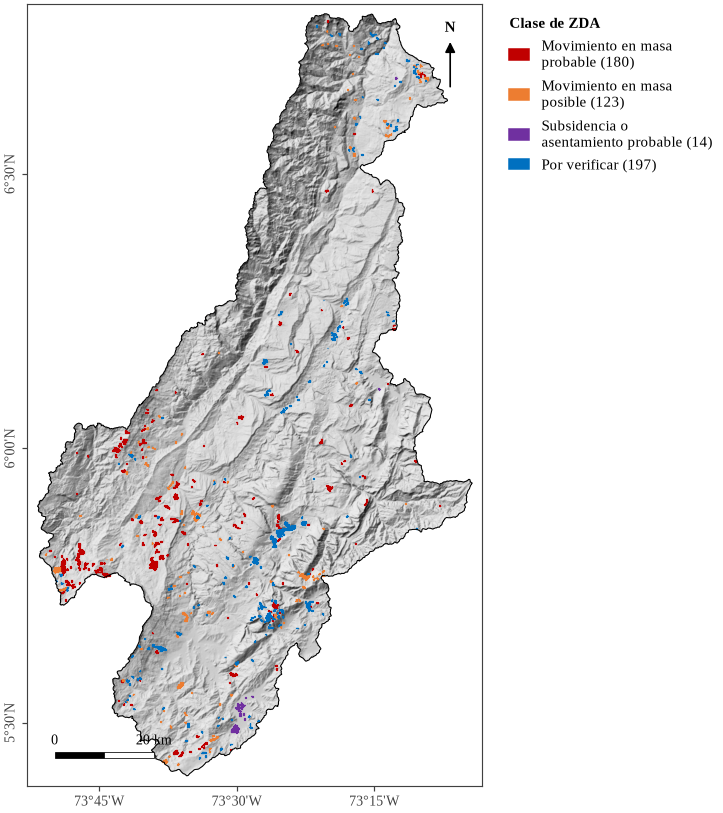

geologia
    clase  area_pct  rf_zda  rf_mm
  b2b6-Sm      62.1    1.13   1.19
   b1-Sct      15.4    0.85   0.74
    J3-Sc       9.1    0.08   0.07
 k1k6-Stm       4.7    0.98   1.18
J1J2-VCct       3.3    0.12   0.19
     Q-ca       2.4    0.42   0.36
  b6k1-Sm       1.3    0.91   0.65
pendiente
clase  area_pct  rf_zda  rf_mm
  0-5      11.2    2.30   0.93
 5-10      28.4    1.39   1.81
10-20      36.6    0.65   0.82
20-30      15.9    0.48   0.42
30-40       6.3    0.45   0.25
  >40       1.7    0.19   0.12
cobertura
            clase  area_pct  rf_zda  rf_mm
           Bosque      62.8    0.55   0.55
Herbazal y pastos      35.2    1.76   1.83
         Cultivos       0.7    5.06   0.47
fallas
   clase  area_pct  rf_zda  rf_mm
 0 a 0,5       3.6    0.62   0.13
 0,5 a 1       3.5    0.75   0.78
   1 a 2       7.1    0.77   1.09
   2 a 5      21.6    0.62   0.71
Más de 5      64.1    1.19   1.15


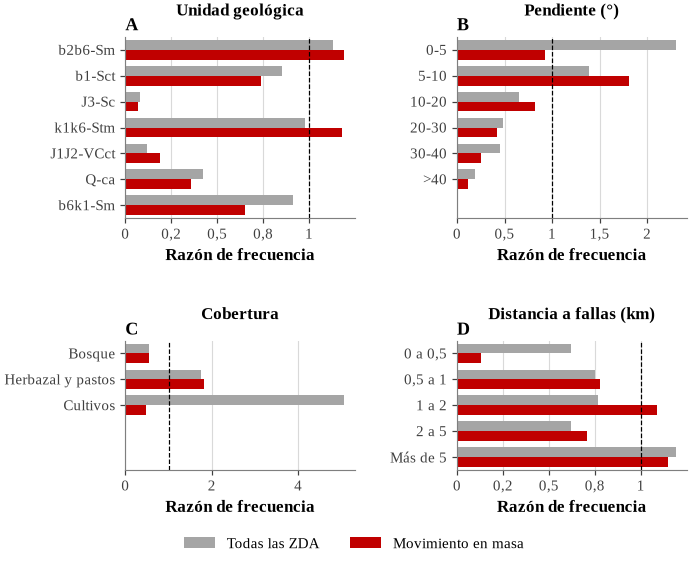

In [ ]:
zda['clase_final'] = zda.clase  # la clasificación se hace en la sección 8
zda.to_file(f'{SIG}/zda_clase_final.gpkg', driver='GPKG')
print(zda.clase_final.value_counts().to_dict())

# mapa de las ZDA por clase sobre el relieve sombreado
from matplotlib.colors import LightSource
COLZ = {'Movimiento en masa probable': '#C00000', 'Movimiento en masa posible': '#ED7D31',
        'Subsidencia o asentamiento probable': '#7030A0', 'Por verificar': '#0070C0'}
sombra = LightSource(azdeg=315, altdeg=45).hillshade(np.nan_to_num(dem, nan=np.nanmean(dem)), vert_exag=2, dx=80, dy=80)
ANCHO_Z = 10.5 * CM
fig = plt.figure(figsize=(FIG_ANCHO, ANCHO_Z * ASPECTO + 1.0 * CM))
ax = fig.add_axes([1.1 * CM / FIG_ANCHO, 0.5 * CM / fig.get_figheight(), ANCHO_Z / FIG_ANCHO, ANCHO_Z * ASPECTO / fig.get_figheight()])
som = np.where(DENTRO, sombra, np.nan)[r0:r1, c0:c1]
ax.imshow(som, extent=EXT, cmap='Greys_r', vmin=0.1, vmax=1.15, alpha=0.45, interpolation='bilinear', zorder=1)   # relieve suave
marco_mapa(ax, norte=True)
for clase, color in COLZ.items():
    sub = zda[zda.clase_final == clase]
    sub.plot(ax=ax, color=color, ec=color, lw=0.8, zorder=4)
ax.set_xlabel(''); ax.set_ylabel('')
conteo = zda.clase_final.value_counts()
CORTA_Z = {'Movimiento en masa probable': 'Movimiento en masa\nprobable', 'Movimiento en masa posible': 'Movimiento en masa\nposible',
           'Subsidencia o asentamiento probable': 'Subsidencia o\nasentamiento probable', 'Por verificar': 'Por verificar'}
ax.legend(handles=[Patch(fc=c, ec=c, label=f'{CORTA_Z[k]} ({conteo.get(k, 0)})') for k, c in COLZ.items()], loc='upper left',
          bbox_to_anchor=(1.03, 1.0), fontsize=10, title='Clase de ZDA', title_fontproperties={'weight': 'bold', 'size': 10},
          alignment='left', handlelength=1.3)
titulo_figura('Zonas de deformación activa por clase en la cuenca media y baja del río Suárez')
plt.show()

ZR = rasterize(((g, 1) for g in zda.geometry), out_shape=S, transform=T, fill=0).astype(bool) & DENTRO
MM = rasterize(((g, 1) for g, k in zip(zda.geometry, zda.clase_final) if k.startswith('Movimiento')),
               out_shape=S, transform=T, fill=0).astype(bool) & DENTRO
uni = list(geo.SimboloUC.unique())
geo_r = rasterize(((g, uni.index(s) + 1) for g, s in zip(geo.geometry, geo.SimboloUC)), out_shape=S, transform=T, fill=0)
# fallas del Mapa Geológico de Colombia 2023 (SGC, 2023) y distancia de cada píxel a la más cercana
from scipy.ndimage import distance_transform_edt
url_f = 'https://srvags.sgc.gov.co/arcgis/rest/services/Mapa_Geologico_Colombia/Mapa_Geologico_Colombia_V2023/FeatureServer/704/query'
caja_f = ','.join(str(round(v, 4)) for v in (b4326[0] - .2, b4326[1] - .2, b4326[2] + .2, b4326[3] + .2))
jf = requests.get(url_f, timeout=180, params=dict(where='1=1', geometry=caja_f, geometryType='esriGeometryEnvelope', inSR=4326,
                                                  outSR=4326, outFields='*', f='geojson')).json()
fallas = gpd.GeoDataFrame.from_features(jf['features'], crs=4326).to_crs(32618)
fallas.to_file(f'{SIG}/fallas_sgc2023.gpkg', driver='GPKG')
dist_f = distance_transform_edt(~rasterize(((g, 1) for g in fallas.geometry), out_shape=S, transform=T, fill=0, all_touched=True).astype(bool)) * 80
LIM_F = [0, 500, 1000, 2000, 5000, 1e9]; ETQ_F = ['0 a 0,5', '0,5 a 1', '1 a 2', '2 a 5', 'Más de 5']
CIFRAS['fallas'] = dict(n=len(fallas), km=round(float(fallas.clip(cuenca).length.sum() / 1000), 1))
def rf(clases, minimo=0.01):
    filas = []
    for etq, m in clases:
        m = m & DENTRO; pa = m.sum() / DENTRO.sum()
        if pa < minimo: continue
        filas.append(dict(clase=etq, area_pct=round(100 * pa, 1), rf_zda=round((ZR & m).sum() / ZR.sum() / pa, 2), rf_mm=round((MM & m).sum() / MM.sum() / pa, 2)))
    return pd.DataFrame(filas)
tablas_rf = {
    'geologia': rf([(u.replace('?', ''), geo_r == i + 1) for i, u in enumerate(uni)]).sort_values('area_pct', ascending=False),
    'pendiente': rf([(e, (pend >= a) & (pend < b)) for e, a, b in zip(ETQ, LIM[:-1], LIM[1:])]),
    'cobertura': rf([(NOM[c], cob == c) for c in cods], minimo=0.005),
    'fallas': rf([(e, (dist_f >= a) & (dist_f < b)) for e, a, b in zip(ETQ_F, LIM_F[:-1], LIM_F[1:])])}
TITULO_RF = {'geologia': 'Unidad geológica', 'pendiente': 'Pendiente (°)', 'cobertura': 'Cobertura', 'fallas': 'Distancia a fallas (km)'}
n_arriba, n_abajo = max(len(tablas_rf['geologia']), len(tablas_rf['pendiente'])), max(len(tablas_rf['cobertura']), len(tablas_rf['fallas']))
alto_rf = 0.55 * (n_arriba + n_abajo) + 6.4
fig = plt.figure(figsize=(FIG_ANCHO, alto_rf * CM))
cuadro = fig.add_gridspec(2, 4, height_ratios=[n_arriba, n_abajo], left=0.17, right=0.98, top=1 - 0.8 / alto_rf,
                          bottom=2.2 / alto_rf, hspace=2.6 / (0.55 * (n_arriba + n_abajo) / 2), wspace=1.6)
ejes_rf = [fig.add_subplot(cuadro[0, :2]), fig.add_subplot(cuadro[0, 2:]), fig.add_subplot(cuadro[1, :2]), fig.add_subplot(cuadro[1, 2:])]
for k_, (ax, (nombre, t)) in enumerate(zip(ejes_rf, tablas_rf.items())):
    t = t.reset_index(drop=True); y = np.arange(len(t)); h = 0.38
    ax.barh(y - h / 2, t.rf_zda, h, color=GRIS, label='Todas las ZDA'); ax.barh(y + h / 2, t.rf_mm, h, color=COLOR_ROJO, label='Movimiento en masa')
    ax.axvline(1, color='black', lw=0.8, ls='--'); ax.set_yticks(y); ax.set_yticklabels(t.clase, fontsize=9.5); ax.invert_yaxis()
    ax.set_ylim((n_arriba if k_ < 2 else n_abajo) - 0.5, -0.5)
    ax.set_xlabel('Razón de frecuencia'); ax.set_title(TITULO_RF[nombre], pad=14); ejes(ax, 'x'); letra_panel(ax, 'ABCD'[k_])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt(v, 1) if v % 1 else f'{v:.0f}'))
    t.to_csv(f'{PAN}/razon_frecuencia_{nombre}.csv', index=False)
    print(nombre); print(t.to_string(index=False))
fig.legend(*ejes_rf[0].get_legend_handles_labels(), loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.0))
titulo_figura('Razón de frecuencia de las zonas de deformación activa por unidad geológica, pendiente, cobertura y distancia a fallas')
plt.show()
json.dump(CIFRAS, open(f'{PAN}/cifras_paneles.json', 'w'), ensure_ascii=False, indent=1, default=float)

## 16. Movimiento regional: serie del percentil 50 en cada geometría y sismos

Resume el desplazamiento de toda la cuenca con los percentiles 25, 50 y 75 de los píxeles con coherencia temporal ≥ 0,7 en cada fecha (Valencia Ortiz et al., 2024) y marca los sismos a menos de 200 km del catálogo del USGS. Superficiales (< 50 km) de magnitud ≥ 4,5 e intermedios (≥ 50 km, como los del nido de Bucaramanga) de magnitud ≥ 5,0. Si la serie no cambia de pendiente en las fechas de los sismos, el movimiento local no se explica por ellos. Exporta los sismos para el SIG.

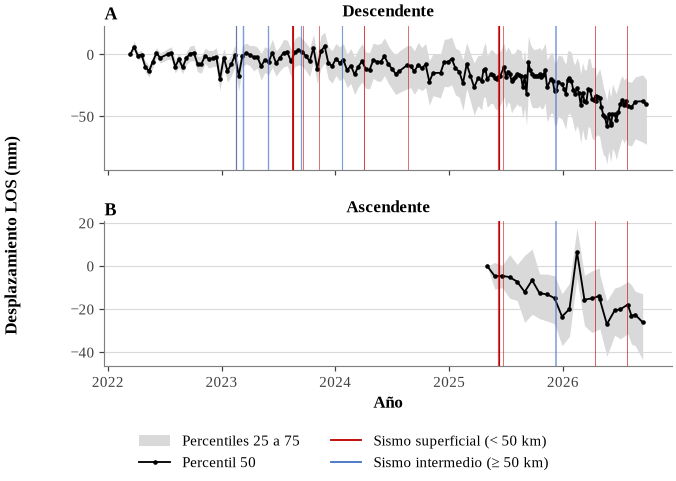

{'pixeles': 47579, 'p50_final_mm': -40.2} {'pixeles': 43187, 'p50_final_mm': -26.1} {'Superficial (< 50 km)': 17, 'Intermedio (≥ 50 km)': 6}


In [ ]:
def serie_cuenca(orbita, frame, paso=3):
    with h5py.File(f'{MP}{orbita}_{frame}/timeseries_SET_ERA5_ramp_demErr.h5') as f:
        at = dict(f.attrs); fechas = pd.to_datetime([d.decode() for d in f['date'][()]])
        ts = np.stack([f['timeseries'][i][::paso, ::paso] for i in range(len(fechas))]) * 1000
    with h5py.File(f'{MP}{orbita}_{frame}/temporalCoherence.h5') as f:
        ct = f['temporalCoherence'][::paso, ::paso]
    tr = from_origin(float(at['X_FIRST']), float(at['Y_FIRST']), 80 * paso, 80 * paso)
    m = geometry_mask(cuenca.geometry, out_shape=ct.shape, transform=tr, invert=True) & (ct >= 0.7)
    px = ts[:, m]; px = px[:, np.all(np.isfinite(px), axis=0)]; px = px - px[0]
    return fechas, np.percentile(px, [25, 50, 75], axis=1), px.shape[1]

c_ = cuenca.to_crs(4326).geometry.iloc[0].centroid
q = requests.get('https://earthquake.usgs.gov/fdsnws/event/1/query', timeout=120, params=dict(
    format='csv', starttime='2022-03-01', endtime='2026-10-01', latitude=round(c_.y, 3), longitude=round(c_.x, 3),
    maxradiuskm=200, minmagnitude=4.5))
sismos = pd.read_csv(io.StringIO(q.text), parse_dates=['time'])
sismos['tipo'] = np.where(sismos.depth < 50, 'Superficial (< 50 km)', 'Intermedio (≥ 50 km)')
sismos = sismos[(sismos.depth < 50) | (sismos.mag >= 5.0)].reset_index(drop=True)
gpd.GeoDataFrame(sismos, geometry=gpd.points_from_xy(sismos.longitude, sismos.latitude), crs=4326).to_file(f'{SIG}/sismos_usgs_M45_200km.gpkg', driver='GPKG')
COLS = {'Superficial (< 50 km)': COLOR_ROJO, 'Intermedio (≥ 50 km)': AZUL}
fig, ejes_s = plt.subplots(2, 1, figsize=(FIG_ANCHO, 11.5 * CM), sharex=True)
for k_, (ax, nombre, orb, fr) in enumerate(zip(ejes_s, ('descendente', 'ascendente'), ('DESCENDING_R69', 'ASCENDING_R77'), ('F572', 'F1199'))):
    fechas, p, n = serie_cuenca(orb, fr)
    ax.fill_between(fechas, p[0], p[2], color='#D9D9D9', lw=0, label='Percentiles 25 a 75')
    ax.plot(fechas, p[1], color='black', lw=1.2, marker='o', ms=2, label='Percentil 50')
    for _, s in sismos[(sismos.time >= fechas[0].tz_localize('UTC')) & (sismos.time <= fechas[-1].tz_localize('UTC'))].iterrows():
        ax.axvline(s.time.tz_localize(None), color=COLS[s.tipo], lw=0.5 + 0.5 * (s.mag - 4.5), alpha=0.7)
    ax.set_title(nombre.capitalize(), pad=6); ejes(ax); letra_panel(ax, 'AB'[k_])
    CIFRAS[f'serie_regional_{nombre}'] = dict(pixeles=int(n), p50_final_mm=round(float(p[1][-1]), 1))
eje_anios(ejes_s[1]); ejes_s[1].set_xlabel('Año')
h, l = ejes_s[0].get_legend_handles_labels()
h += [plt.Line2D([], [], color=c, lw=1.2) for c in COLS.values()]; l += [f'Sismo {k.lower()}' for k in COLS]
fig.legend(h, l, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 0.0))
fig.supylabel('Desplazamiento LOS (mm)', fontsize=11, fontweight='bold', x=0.01)
fig.tight_layout(rect=(0.03, 0.11, 1, 1), h_pad=1.5)
titulo_figura('Desplazamiento de la cuenca en cada geometría y sismos de magnitud 4,5 o mayor a menos de 200 km')
plt.show()
CIFRAS['sismos'] = sismos.tipo.value_counts().to_dict()
print(CIFRAS['serie_regional_descendente'], CIFRAS['serie_regional_ascendente'], CIFRAS['sismos'])

## 17. Lluvia en la cuenca y movimiento regional

Promedio mensual de CHIRPS v3.0 dentro de la cuenca, mapa de la lluvia anual media de 2023 a 2025 y correlación rezagada entre la lluvia y la tasa mensual del percentil 50 de la geometría descendente, sin tendencia y hasta marzo de 2026. La serie ascendente, de 16 meses, no alcanza para una correlación.

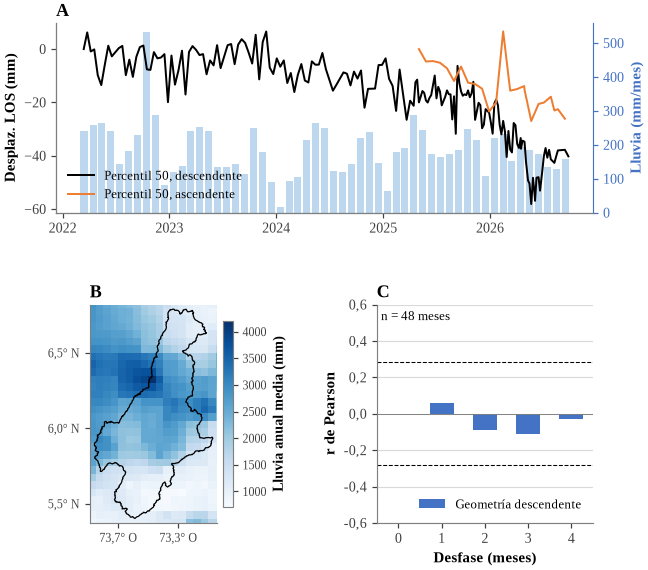

{'anual_media_mm': 2068, 'anual_por_anio': {2023: 2040, 2024: 1936, 2025: 2230}, 'mes_mas_lluvioso': 10, 'mes_mas_seco': 1, 'climatologia': {1: 105, 2: 160, 3: 186, 4: 242, 5: 240, 6: 195, 7: 140, 8: 150, 9: 167, 10: 312, 11: 229, 12: 107}, 'mapa_min_max': [717, 4201], 'correlacion': {'descendente': {0: 0.0, 1: 0.06, 2: -0.09, 3: -0.11, 4: -0.03}}, 'umbral_95': 0.28, 'meses': 48}


In [ ]:
from rasterio.plot import plotting_extent
from rasterio.io import MemoryFile
from rasterio.windows import from_bounds
CHC = f'{R}/03_resultados/tablas/chirps_mensual_cuenca.csv'
MAPA_LLUVIA = f'{GT}/chirps_lluvia_anual_media_2023_2025.tif'
meses = pd.date_range('2022-03-01', '2026-09-01', freq='MS')
c4 = cuenca.to_crs(4326)
if not (os.path.exists(CHC) and os.path.exists(MAPA_LLUVIA)):
    import time  # el servidor limita las peticiones parciales, se baja cada mapa completo (unos 22 MB)
    filas, suma = [], None
    for mes in meses:
        u = f'https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/tifs/chirps-v3.0.{mes:%Y.%m}.tif'
        for intento in range(6):
            r = requests.get(u, timeout=300)
            if r.status_code == 200:
                break
            time.sleep(15 * (intento + 1))
        else:
            raise RuntimeError(f'CHIRPS no respondió para {mes:%Y-%m}')
        with MemoryFile(r.content) as mf, mf.open() as ds:
            x0, y0, x1, y1 = c4.total_bounds
            ventana = from_bounds(x0 - 0.1, y0 - 0.1, x1 + 0.1, y1 + 0.1, ds.transform).round_offsets().round_lengths()
            a = ds.read(1, window=ventana).astype(float)
            a[a < 0] = np.nan
            tr_l = ds.window_transform(ventana)
            dentro = geometry_mask(c4.geometry, out_shape=a.shape, transform=tr_l, invert=True, all_touched=True)
            filas.append(dict(mes=mes, lluvia_mm=float(np.nanmean(a[dentro])), minima_mm=float(np.nanmin(a[dentro])), maxima_mm=float(np.nanmax(a[dentro]))))
            if 2023 <= mes.year <= 2025:
                suma = a if suma is None else suma + a
                perfil = ds.profile.copy()
    pd.DataFrame(filas).to_csv(CHC, index=False)
    perfil.update(height=suma.shape[0], width=suma.shape[1], transform=tr_l, count=1, dtype='float32', nodata=np.nan, compress='deflate')
    with rasterio.open(MAPA_LLUVIA, 'w', **perfil) as ds:
        ds.write((suma / 3).astype('float32'), 1)
ll = pd.read_csv(CHC, parse_dates=['mes']).set_index('mes')

# relación con el movimiento regional de la cuenca (percentil 50 de cada geometría, sección 8)
LAGS_C = range(0, 5)
FIN_C = '2026-03-31'
CORR_C, SER_C = {}, {}
for nombre, orb, fr in (('descendente', 'DESCENDING_R69', 'F572'), ('ascendente', 'ASCENDING_R77', 'F1199')):
    fechas, p, _ = serie_cuenca(orb, fr)
    s = pd.Series(p[1], index=fechas)
    SER_C[nombre] = s
    if nombre == 'ascendente':  # 16 meses de serie, muy pocos para una correlación
        continue
    tasa = s.resample('D').mean().interpolate().resample('MS').mean().diff()
    df = pd.concat([ll.lluvia_mm.rename('p'), tasa.rename('v')], axis=1).loc[:FIN_C].dropna()
    vdt = df.v - np.polyval(np.polyfit(np.arange(len(df)), df.v, 1), np.arange(len(df)))
    CORR_C[nombre] = {L: round(float(np.corrcoef(df.p.values[:len(df) - L], vdt.values[L:])[0, 1]), 2) for L in LAGS_C}
umbral_c = 1.96 / np.sqrt(len(df))

fig = plt.figure(figsize=(FIG_ANCHO, 15 * CM))
cuadro = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], width_ratios=[1, 1.1], hspace=0.45, wspace=0.6)
ax = fig.add_subplot(cuadro[0, :])
ax2 = ax.twinx()
ax2.bar(ll.index + pd.Timedelta(days=14), ll.lluvia_mm, width=24, color='#BDD7EE', zorder=1)
ax2.set_ylabel('Lluvia (mm/mes)', color=AZUL, fontsize=10)
ax2.tick_params(axis='y', colors=AZUL, labelsize=9)
ax2.spines['right'].set_visible(True); ax2.spines['right'].set_color(AZUL); ax2.spines['top'].set_visible(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
for (nombre, s), color in zip(SER_C.items(), ('black', NARANJA)):
    ax.plot(s.index, s.values, color=color, lw=1.3, label=f'Percentil 50, {nombre}')
ax.set_ylabel('Desplaz. LOS (mm)', fontsize=10); ejes(ax, None); eje_anios(ax); ax.tick_params(labelsize=9)
ax.legend(fontsize=8.5, loc='lower left')
letra_panel(ax, 'A')
# lluvia anual media
bx = fig.add_subplot(cuadro[1, 0])
with rasterio.open(MAPA_LLUVIA) as ds:
    m_ll = ds.read(1); ext = plotting_extent(ds)
im = bx.imshow(m_ll, extent=ext, cmap='Blues', interpolation='nearest')
c4.boundary.plot(ax=bx, color='black', lw=0.8)
x0, y0, x1, y1 = c4.total_bounds
bx.set_xlim(x0 - 0.03, x1 + 0.03); bx.set_ylim(y0 - 0.03, y1 + 0.03)
bx.tick_params(labelsize=8)
bx.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{abs(v):.1f}° O'.replace('.', ',')))
bx.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.1f}° N'.replace('.', ',')))
bx.set_xticks([-73.7, -73.3]); bx.set_yticks([5.5, 6.0, 6.5]); bx.set_xlabel(''); bx.set_ylabel('')
barra = fig.colorbar(im, ax=bx, shrink=0.85, pad=0.03)
barra.set_label('Lluvia anual media (mm)', fontsize=9); barra.ax.tick_params(labelsize=8)
letra_panel(bx, 'B')
# correlación rezagada
cx = fig.add_subplot(cuadro[1, 1])
cx.bar(list(LAGS_C), list(CORR_C['descendente'].values()), 0.55, color=AZUL, label='Geometría descendente')
for u_ in (umbral_c, -umbral_c):
    cx.axhline(u_, color='black', lw=0.7, ls='--')
cx.axhline(0, color='#7F7F7F', lw=0.6); cx.set_ylim(-0.6, 0.6); cx.set_xticks(list(LAGS_C))
cx.set_xlabel('Desfase (meses)', fontsize=10); cx.set_ylabel('r de Pearson', fontsize=10); cx.tick_params(labelsize=9)
cx.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt(v)))
cx.legend(fontsize=8.5, loc='lower right'); ejes(cx)
cx.text(0.02, 0.97, f'n = {len(df)} meses', transform=cx.transAxes, fontsize=8.5, va='top')
letra_panel(cx, 'C')
titulo_figura('Lluvia mensual en la cuenca, movimiento regional y correlación rezagada')
plt.show()
clima = ll.lluvia_mm.groupby(ll.index.month).mean()
CIFRAS['lluvia_cuenca'] = dict(
    anual_media_mm=round(float(ll.loc['2023-01-01':'2025-12-31', 'lluvia_mm'].sum() / 3)),
    anual_por_anio={a: round(float(ll.loc[str(a), 'lluvia_mm'].sum())) for a in (2023, 2024, 2025)},
    mes_mas_lluvioso=int(clima.idxmax()), mes_mas_seco=int(clima.idxmin()),
    climatologia={int(k): round(float(v)) for k, v in clima.items()},
    mapa_min_max=[round(float(np.nanmin(m_ll))), round(float(np.nanmax(m_ll)))],
    correlacion=CORR_C, umbral_95=round(float(umbral_c), 2), meses=int(len(df)))
json.dump(CIFRAS, open(f'{PAN}/cifras_paneles.json', 'w'), ensure_ascii=False, indent=1, default=float)
print(CIFRAS['lluvia_cuenca'])

## 18. Barrido de la cuenca por celdas de 20 km y selección de zonas representativas

Divide la cuenca en celdas de 20 km y resume cada una: ZDA por clase, área, velocidad, fracción medida, coherencia, cobertura, unidad geológica y pendiente. En cada celda elige la ZDA principal de movimiento en masa (primero las probables y, entre ellas, la de mayor área × |velocidad|) y extrae la serie de todos sus píxeles, referida a la estación OAMU. Una serie es consistente si tiene el mismo signo del mapa y al menos el 40 % de su magnitud. Las zonas representativas que se analizan en el texto son las cinco celdas con mayor puntaje (suma de área × |velocidad| de sus ZDA de movimiento en masa) cuya serie es consistente y que están a más de 5 km de otra zona ya elegida. Las demás quedan en las fichas del anexo. Exporta la cuadrícula para el SIG.

In [ ]:
from shapely.geometry import box
from pyproj import Transformer
CEL = 20000; b = cuenca.total_bounds
celdas = [box(x, y, x + CEL, y + CEL) for x in np.arange(np.floor(b[0] / CEL) * CEL, b[2], CEL)
          for y in np.arange(np.floor(b[1] / CEL) * CEL, b[3], CEL) if cuenca.intersects(box(x, y, x + CEL, y + CEL)).any()]
OAMU = Transformer.from_crs(4326, 32618, always_xy=True).transform(-73.558029, 5.647209)

def serie_pixeles(g, orbita='DESCENDING_R69', frames=('F572', 'F567'), minimo=5):
    """Series (mm) de los píxeles de un polígono, referidas a OAMU si el frame la cubre."""
    for fr in frames:
        with h5py.File(f'{MP}{orbita}_{fr}/timeseries_SET_ERA5_ramp_demErr.h5') as f:
            at = dict(f.attrs); fechas = pd.to_datetime([d.decode() for d in f['date'][()]])
            tr = from_origin(float(at['X_FIRST']), float(at['Y_FIRST']), 80, 80); L, W = f['timeseries'].shape[1:]
            gb = g.bounds; a0, b0 = rowcol(tr, gb[0], gb[3]); a1, b1 = rowcol(tr, gb[2], gb[1])
            if a0 < 0 or b0 < 0 or a1 >= L or b1 >= W: continue
            ro, co = rowcol(tr, *OAMU)
            ref = np.nanmedian(f['timeseries'][:, ro - 4:ro + 5, co - 4:co + 5].reshape(len(fechas), -1), axis=1) if (0 <= ro < L and 0 <= co < W) else 0
            sub = f['timeseries'][:, a0:a1 + 1, b0:b1 + 1]
        m = geometry_mask([g], out_shape=sub.shape[1:], transform=from_origin(tr.c + b0 * 80, tr.f - a0 * 80, 80, 80), invert=True)
        px = (sub[:, m] - (ref[:, None] if np.ndim(ref) else 0)) * 1000
        ok = np.all(np.isfinite(px), axis=0) & (np.abs(px).sum(axis=0) > 0)
        if ok.sum() < minimo: continue
        filas, cols = np.nonzero(m)
        xy = np.c_[tr.c + (b0 + cols[ok] + 0.5) * 80, tr.f - (a0 + filas[ok] + 0.5) * 80]
        px = px[:, ok]; return fechas, px - px[0], xy, fr
    return None

def tendencia(fechas, y):
    t = (fechas - fechas[0]).days / 365.25
    return np.polyfit(t, y, 1)

cand = zda[zda.clase_final.str.startswith('Movimiento') & (zda.calidad <= 2)].copy()  # zona representativa: mejor calidad y mayor velocidad
cand['score'] = cand.v_media.abs()
filas, SERIES = [], {}
for i, g in enumerate(celdas, start=1):
    m = DENTRO & geometry_mask([g], out_shape=S, transform=T, invert=True)
    en_z = zda[zda.geometry.centroid.within(g)]; en_c = cand[cand.geometry.centroid.within(g)]
    fila = dict(celda=i, area_km2=round(m.sum() * 0.0064, 1), n_zda=len(en_z),
                **{k: int((en_z.clase_final == v).sum()) for k, v in (('n_mm_probable', 'Movimiento en masa probable'),
                   ('n_mm_posible', 'Movimiento en masa posible'), ('n_subsidencia', 'Subsidencia o asentamiento probable'), ('n_por_verificar', 'Por verificar'))},
                medido_pct=round(100 * float(np.mean(np.isfinite(vd[m]))), 1) if m.any() else np.nan,
                coh_mediana=round(float(np.nanmedian(coh_t[m])), 2) if m.any() else np.nan,
                pend_media=round(float(np.nanmean(pend[m])), 1) if m.any() else np.nan,
                cobertura=NOM.get(int(pd.Series(cob[m]).mode().iloc[0]), '') if m.any() else '',
                unidad=uni[int(pd.Series(geo_r[m][geo_r[m] > 0]).mode().iloc[0]) - 1].replace('?', '') if (m & (geo_r > 0)).any() else '',
                puntaje=round(float(en_c.score.sum()), 0))
    if len(en_c):
        s = en_c.assign(prio=(en_c.clase_final != 'Movimiento en masa probable').astype(int)).sort_values(['prio', 'calidad', 'score'], ascending=[True, True, False]).iloc[0]
        r_ = serie_pixeles(s.geometry)
        fila.update(ZDA=s.ZDA, clase=s.clase_final, area_ha=round(s.area_ha, 1), v_mapa=round(s.v_media, 1))
        if r_:
            SERIES[s.ZDA] = r_; v = tendencia(r_[0], r_[1].mean(axis=1))[0]
            fila.update(v_serie=round(v, 1), n_px=r_[1].shape[1], frame=r_[3],
                        consistente=bool(np.sign(v) == np.sign(s.v_media) and abs(v) >= 0.4 * abs(s.v_media)))
    filas.append(fila)
barrido = pd.DataFrame(filas)
barrido['rango'] = barrido.puntaje.rank(ascending=False, method='first').astype(int)
elegidas = []
for _, f_ in barrido[barrido.consistente.fillna(False).astype(bool)].sort_values('puntaje', ascending=False).iterrows():
    c_z = zda[zda.ZDA == f_.ZDA].geometry.iloc[0].centroid
    if all(c_z.distance(zda[zda.ZDA == e].geometry.iloc[0].centroid) > 5000 for e in elegidas): elegidas.append(f_.ZDA)
    if len(elegidas) == 5: break
REPRES = barrido[barrido.ZDA.isin(elegidas)].sort_values('puntaje', ascending=False)
barrido['representativa'] = barrido.celda.isin(REPRES.celda)
barrido.to_csv(f'{PAN}/barrido_celdas.csv', index=False)
gpd.GeoDataFrame(barrido, geometry=celdas, crs=32618).to_file(f'{SIG}/cuadricula_20km.gpkg', driver='GPKG')
print(barrido[['celda', 'rango', 'n_zda', 'ZDA', 'clase', 'v_mapa', 'v_serie', 'consistente', 'puntaje', 'representativa']].to_string(index=False))

 celda  rango  n_zda     ZDA                       clase  v_mapa  v_serie consistente  puntaje  representativa
     1      8     22 ZDA-022 Movimiento en masa probable   -35.0    -48.4        True    501.0           False
     2     10     15 ZDA-006 Movimiento en masa probable   -40.4    -52.8        True    405.0           False
     3     21      2 ZDA-165 Movimiento en masa probable    24.0     20.5        True     48.0           False
     4     24      1 ZDA-437  Movimiento en masa posible   -22.9    -24.5        True     23.0           False
     5      2     46 ZDA-051 Movimiento en masa probable   -29.9    -35.4        True    935.0            True
     6      7     30 ZDA-002 Movimiento en masa probable   -36.9    -43.6        True    503.0           False
     7      1     54 ZDA-237 Movimiento en masa probable   -53.8    -61.2        True   1445.0            True
     8      3     36 ZDA-036 Movimiento en masa probable   -35.3    -44.3        True    857.0            True
 

## 19. Zonas representativas: velocidad local, serie media, punto móvil y punto estable

Para cada zona representativa arma una figura con cuatro paneles: la planta con el relieve sombreado, la velocidad local descendente, las ZDA y dos puntos (P1, el píxel de la zona con mayor tendencia, y P2, el píxel estable más cercano a más de 400 m de toda ZDA, con velocidad local |v| < 2 mm/año y coherencia temporal ≥ 0,8. Como su serie está referida a OAMU, muestra el movimiento de fondo de la zona), la serie de todos los píxeles de la zona con su media, su dispersión y su tendencia, la misma serie en la geometría ascendente cuando hay datos, y la comparación de los puntos P1 y P2 (Sun et al., 2015). Además exporta un KMZ por zona, con cada píxel como un cuadro de 80 m pintado según la velocidad, para verlo inclinado en Google Earth.

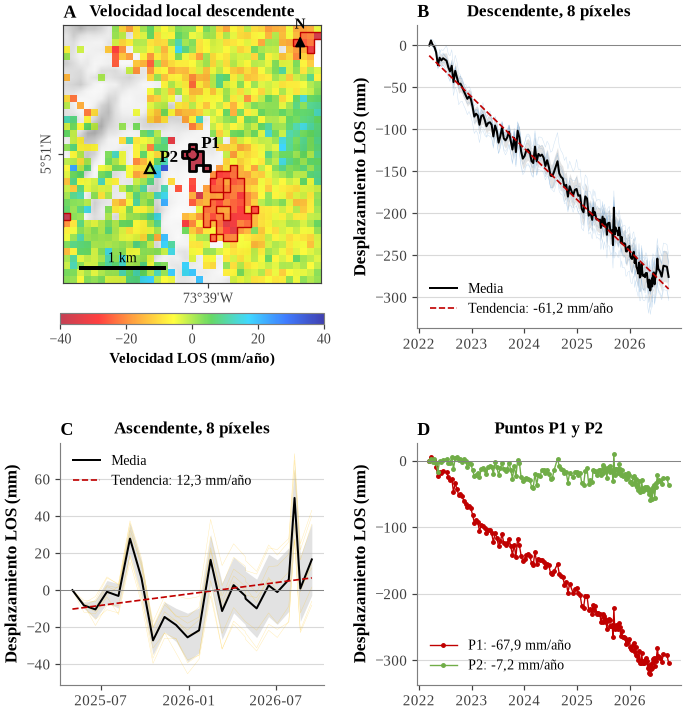

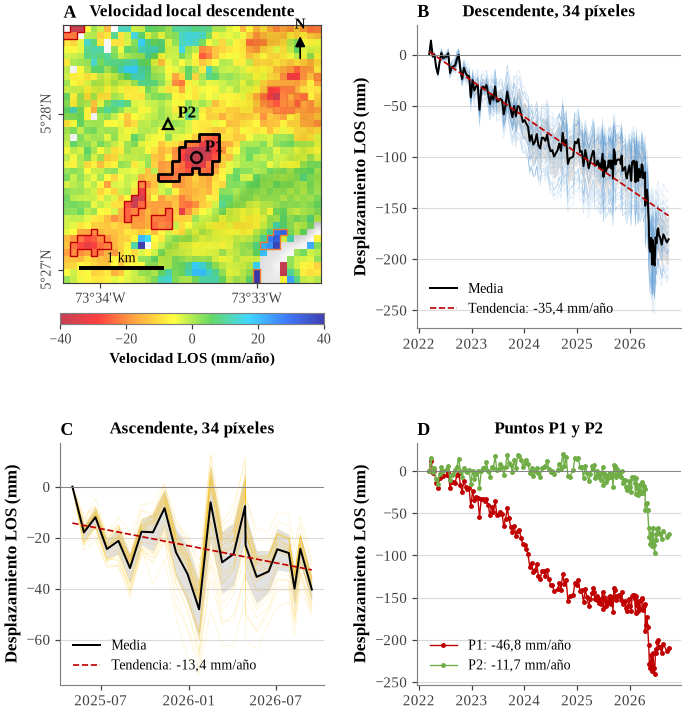

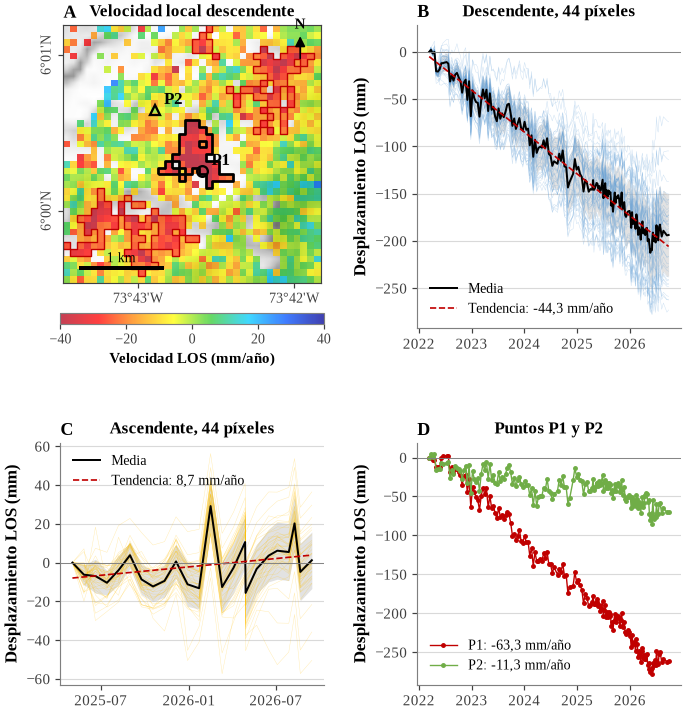

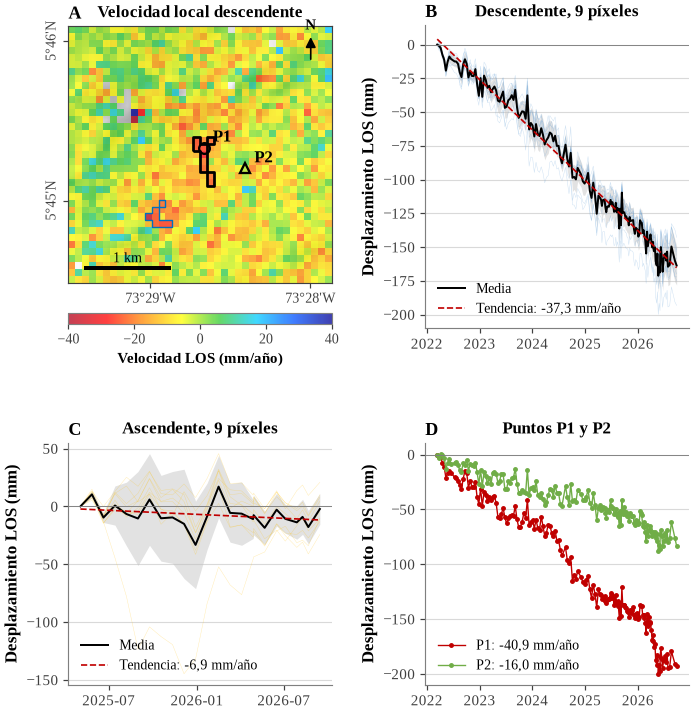

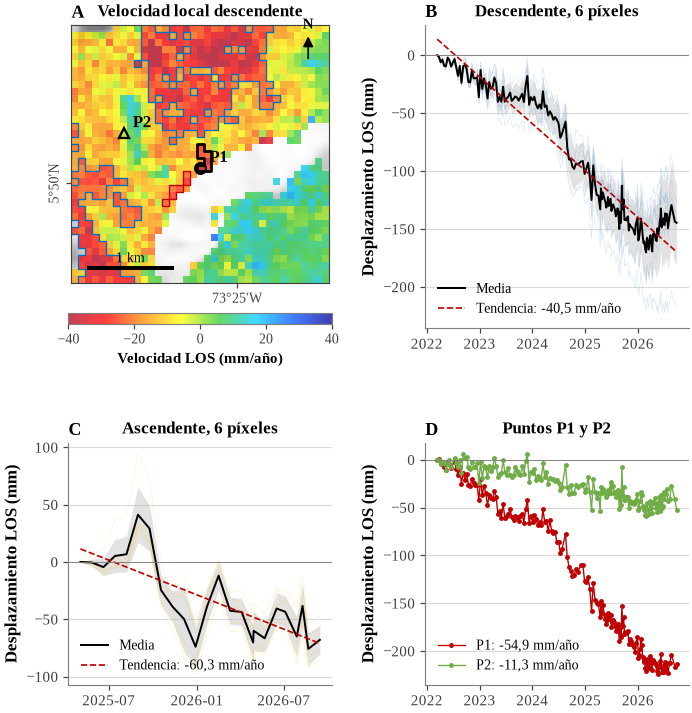

        celda                        clase area_ha v_mapa v_serie n_px v_asc    unidad  pend     lat      lon
ZDA-237     7  Movimiento en masa probable     5.1  -53.8   -61.2    8  12.3   b2b6-Sm   9.5  5.8495 -73.6513
ZDA-051     5  Movimiento en masa probable    21.8  -29.9   -35.4   34 -13.4  k6E1-Stm  10.0   5.462 -73.5565
ZDA-036     8  Movimiento en masa probable    28.2  -35.3   -44.3   44   8.7   b2b6-Sm   8.3  6.0058 -73.7105
ZDA-225    11  Movimiento en masa probable     5.8  -23.4   -37.3    9  -6.9   b2b6-Sm   7.9  5.7544 -73.4777
ZDA-357    12  Movimiento en masa probable     3.8  -29.9   -40.5    6 -60.3   b2b6-Sm  22.2  5.8359 -73.4201


In [ ]:
import zipfile
from matplotlib.colors import Normalize
KMZ = f'{SIG}/kmz'; os.makedirs(KMZ, exist_ok=True)
X0, Y0 = T.c, T.f
from scipy.ndimage import binary_dilation
ZR_buffer = binary_dilation(rasterize(((g, 1) for g in zda.geometry), out_shape=S, transform=T, fill=0).astype(bool), iterations=5)
def ventana(c, h):
    rr0, cc0 = rowcol(T, c.x - h, c.y + h); rr1, cc1 = rowcol(T, c.x + h, c.y - h)
    return slice(max(rr0, 0), rr1), slice(max(cc0, 0), cc1), (X0 + max(cc0, 0) * 80, X0 + cc1 * 80, Y0 - rr1 * 80, Y0 - max(rr0, 0) * 80)

def punto_estable(c, h=2500):
    fs, cs, _ = ventana(c, h)
    ok = (np.abs(vd[fs, cs]) < 2) & (coh_t[fs, cs] >= 0.8) & ~ZR_buffer[fs, cs]
    if not ok.any(): return None
    ff, cc = np.nonzero(ok)
    x = X0 + (cs.start + cc + 0.5) * 80; y = Y0 - (fs.start + ff + 0.5) * 80
    k = np.argmin(np.hypot(x - c.x, y - c.y)); return x[k], y[k]

def serie_punto(x, y, frame):
    from shapely.geometry import Point
    return serie_pixeles(Point(x, y).buffer(30, cap_style=3), frames=(frame,), minimo=1)

def kml_color(hexc, alfa='c8'):
    return alfa + hexc[5:7] + hexc[3:5] + hexc[1:3]

def exportar_kmz(z, c, h, a, b_):
    a_geo = Transformer.from_crs(32618, 4326, always_xy=True)
    fs, cs, _ = ventana(c, h); cmap = plt.get_cmap(VEL['cmap']); nrm = Normalize(VEL['vmin'], VEL['vmax'])
    marcas = []
    for f_ in range(fs.start, fs.stop):
        for c__ in range(cs.start, cs.stop):
            v = vd[f_, c__]
            if not np.isfinite(v): continue
            x0, y1 = X0 + c__ * 80, Y0 - f_ * 80
            esq = [a_geo.transform(x, y) for x, y in ((x0, y1), (x0 + 80, y1), (x0 + 80, y1 - 80), (x0, y1 - 80), (x0, y1))]
            col = matplotlib.colors.to_hex(cmap(nrm(v)))
            marcas.append(f'<Placemark><Style><PolyStyle><color>{kml_color(col)}</color><outline>0</outline></PolyStyle></Style>'
                          f'<Polygon><tessellate>1</tessellate><altitudeMode>clampToGround</altitudeMode><outerBoundaryIs><LinearRing><coordinates>'
                          + ' '.join(f'{lo:.6f},{la:.6f},0' for lo, la in esq) + '</coordinates></LinearRing></outerBoundaryIs></Polygon></Placemark>')
    zonas = []
    for _, r_ in zda[zda.intersects(box(c.x - h, c.y - h, c.x + h, c.y + h))].iterrows():
        gg = r_.geometry; gg = max(gg.geoms, key=lambda q: q.area) if gg.geom_type == 'MultiPolygon' else gg
        co = ' '.join(f'{lo:.6f},{la:.6f},0' for lo, la in (a_geo.transform(x, y) for x, y in gg.exterior.coords))
        zonas.append(f'<Placemark><name>{r_.ZDA}</name><Style><LineStyle><color>{kml_color(COLZ[r_.clase_final], "ff")}</color><width>{4 if r_.ZDA == z else 2}</width></LineStyle>'
                     f'<PolyStyle><fill>0</fill></PolyStyle></Style><Polygon><tessellate>1</tessellate><outerBoundaryIs><LinearRing><coordinates>{co}</coordinates></LinearRing></outerBoundaryIs></Polygon></Placemark>')
    pts = ''.join(f'<Placemark><name>{n}</name><Point><coordinates>{lo:.6f},{la:.6f},0</coordinates></Point></Placemark>'
                  for n, p in (('P1', a), ('P2', b_)) if p for lo, la in [a_geo.transform(*p)])
    lo, la = a_geo.transform(c.x, c.y)
    kml = (f'<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/kml/2.2"><Document><name>{z}</name>'
           f'<LookAt><longitude>{lo:.6f}</longitude><latitude>{la:.6f}</latitude><altitude>0</altitude><heading>0</heading><tilt>60</tilt><range>{h * 2.2:.0f}</range></LookAt>'
           f'<ScreenOverlay><name>Escala</name><Icon><href>escala.png</href></Icon><overlayXY x="1" y="0" xunits="fraction" yunits="fraction"/>'
           f'<screenXY x="0.98" y="0.04" xunits="fraction" yunits="fraction"/><size x="0" y="0" xunits="pixels" yunits="pixels"/></ScreenOverlay>'
           f'<Folder><name>Velocidad LOS (mm/año)</name>{"".join(marcas)}</Folder><Folder><name>ZDA</name>{"".join(zonas)}</Folder>'
           f'<Folder><name>Puntos</name>{pts}</Folder></Document></kml>')
    with zipfile.ZipFile(f'{KMZ}/{z}.kmz', 'w', zipfile.ZIP_DEFLATED) as k:
        k.writestr('doc.kml', kml); k.write(f'{KMZ}/escala.png', 'escala.png')

# barra de colores que acompaña a los KMZ
fig, ax = plt.subplots(figsize=(6 * CM, 1.4 * CM))
cb = fig.colorbar(matplotlib.cm.ScalarMappable(Normalize(VEL['vmin'], VEL['vmax']), VEL['cmap']), cax=ax, orientation='horizontal')
cb.set_label('Velocidad LOS (mm/año)', fontsize=10); fig.savefig(f'{KMZ}/escala.png', transparent=False, facecolor='white'); plt.close(fig)

# serie media de una zona y su tendencia
def panel_series(ax, fechas, px, color, letra, titulo):
    mu, sd = px.mean(axis=1), px.std(axis=1)
    ax.fill_between(fechas, mu - sd, mu + sd, color='#BFBFBF', alpha=0.45, lw=0)
    ax.plot(fechas, mu, color='black', lw=1.3, label='Media')
    p = tendencia(fechas, mu); t = (fechas - fechas[0]).days / 365.25
    ax.plot(fechas, np.polyval(p, t), '--', color=COLOR_ROJO, lw=1.1, label=f'Tendencia: {fmt(p[0])} mm/año')
    ax.axhline(0, color='#7F7F7F', lw=0.6); ax.set_ylabel('Desplazamiento LOS (mm)'); ejes(ax)
    if (fechas[-1] - fechas[0]).days > 900: eje_anios(ax)
    else: ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')); ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.legend(loc='lower left' if p[0] < 0 else 'upper left', fontsize=9)
    ax.set_title(titulo, pad=6); letra_panel(ax, letra)
    return p[0]

ZONAS = {}
for _, fila in REPRES.iterrows():
    z = fila.ZDA; r_ = zda[zda.ZDA == z].iloc[0]; c = r_.geometry.centroid
    h = max(1500, 0.8 * max(r_.geometry.bounds[2] - r_.geometry.bounds[0], r_.geometry.bounds[3] - r_.geometry.bounds[1]))
    fechas, px, xy, fr = SERIES[z]
    t = (fechas - fechas[0]).days / 365.25
    vpx = np.polyfit(t, px, 1)[0]; a = tuple(xy[np.argmax(np.abs(vpx))])
    b_ = punto_estable(c)
    asc = serie_pixeles(r_.geometry, orbita='ASCENDING_R77', frames=('F1199',))
    fig = plt.figure(figsize=(FIG_ANCHO, 17.5 * CM))
    cuadro = fig.add_gridspec(2, 4, height_ratios=[1.25, 1], left=0.09, right=0.985, top=0.95, bottom=0.08, hspace=0.42, wspace=1.1)
    ax = fig.add_subplot(cuadro[0, :2]); bx = fig.add_subplot(cuadro[0, 2:])
    dx = fig.add_subplot(cuadro[1, :2]) if asc else None
    ex = fig.add_subplot(cuadro[1, 2:] if asc else cuadro[1, 1:3])
    # planta
    fs, cs, ext = ventana(c, h)
    ax.imshow(sombra[fs, cs], extent=ext, cmap='Greys_r', vmin=0, vmax=1, alpha=0.45, interpolation='bilinear')   # relieve suave
    im = ax.imshow(vd[fs, cs], extent=ext, **VEL, alpha=0.75, interpolation='nearest')
    vec = zda[zda.intersects(box(ext[0], ext[2], ext[1], ext[3]))]
    for _, q in vec.iterrows():
        gpd.GeoSeries([q.geometry]).boundary.plot(ax=ax, color=COLZ[q.clase_final] if q.ZDA != z else 'black', lw=1.8 if q.ZDA == z else 0.9)
    ax.plot(*a, 'o', ms=7, mfc='none', mec='black', mew=1.5); ax.annotate('P1', a, xytext=(6, 4), textcoords='offset points', fontsize=11, fontweight='bold')
    if b_: ax.plot(*b_, '^', ms=7, mfc='none', mec='black', mew=1.5); ax.annotate('P2', b_, xytext=(6, 4), textcoords='offset points', fontsize=11, fontweight='bold')
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect('equal')
    coordenadas_geograficas(ax, 32618, 1 / 60, 1 / 60); estilo_eje(ax)
    x0, y0 = ext[0] + 0.06 * (ext[1] - ext[0]), ext[2] + 0.05 * (ext[3] - ext[2])
    ax.add_patch(Rectangle((x0, y0), 1000, 0.014 * (ext[3] - ext[2]), fc='black', zorder=6))
    ax.text(x0 + 500, y0 + 0.03 * (ext[3] - ext[2]), '1 km', ha='center', fontsize=9, zorder=6)
    ax.annotate('', xy=(0.92, 0.97), xytext=(0.92, 0.86), xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>,head_width=0.25,head_length=0.5', color='black', lw=1.1))
    ax.text(0.92, 0.975, 'N', transform=ax.transAxes, ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_title('Velocidad local descendente', pad=6); letra_panel(ax, 'A')
    cb = fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.05, pad=0.1, aspect=25, ticks=range(-40, 41, 20))
    cb.set_label('Velocidad LOS (mm/año)', fontsize=10); cb.ax.tick_params(labelsize=9); cb.solids.set_alpha(0.75)
    # serie media de la zona
    v_ = panel_series(bx, fechas, px, AZUL_CLARO, 'B', f'Descendente, {px.shape[1]} píxeles')
    va_ = panel_series(dx, asc[0], asc[1], ORO, 'C', f'Ascendente, {asc[1].shape[1]} píxeles') if asc else None
    # puntos P1 y P2
    for nombre, p_, col in (('P1', a, COLOR_ROJO), ('P2', b_, VERDE)):
        if p_ is None: continue
        s_ = serie_punto(*p_, fr)
        if s_ is None: continue
        y_ = s_[1].mean(axis=1); ex.plot(s_[0], y_, 'o-', ms=2.2, lw=0.9, color=col,
                                         label=f'{nombre}: {fmt(tendencia(s_[0], y_)[0])} mm/año')
    ex.axhline(0, color='#7F7F7F', lw=0.6); ex.set_ylabel('Desplazamiento LOS (mm)'); ex.legend(fontsize=9); ejes(ex); eje_anios(ex)
    ex.set_title('Puntos P1 y P2', pad=6); letra_panel(ex, 'D' if asc else 'C')
    titulo_figura(f'Zona de deformación activa {z}: velocidad local, series de desplazamiento y puntos de control')
    plt.show()
    exportar_kmz(z, c, h * 1.6, a, b_)
    ZONAS[z] = dict(celda=int(fila.celda), clase=r_.clase_final, area_ha=round(r_.area_ha, 1), v_mapa=round(r_.v_media, 1),
                    v_serie=round(float(v_), 1), n_px=int(px.shape[1]), v_asc=round(float(va_), 1) if asc else None,
                    unidad=r_.unidad_geologica, pend=round(r_.pend_media, 1), lat=round(r_.lat, 4), lon=round(r_.lon, 4))
CIFRAS['zonas_representativas'] = ZONAS
print(pd.DataFrame(ZONAS).T.to_string())

## 20. Lluvia mensual y correlación rezagada en las zonas representativas

Toma la lluvia mensual de CHIRPS v3 del Climate Hazards Center en el centroide de cada zona representativa, la compara con su serie de desplazamiento y calcula la correlación de Pearson entre la lluvia y la tasa mensual de desplazamiento sin tendencia, con desfases de 0 a 4 meses, hasta marzo de 2026 (se excluye el descenso común de abril a junio de 2026). El umbral de significancia al 95 % es 1,96/√n.

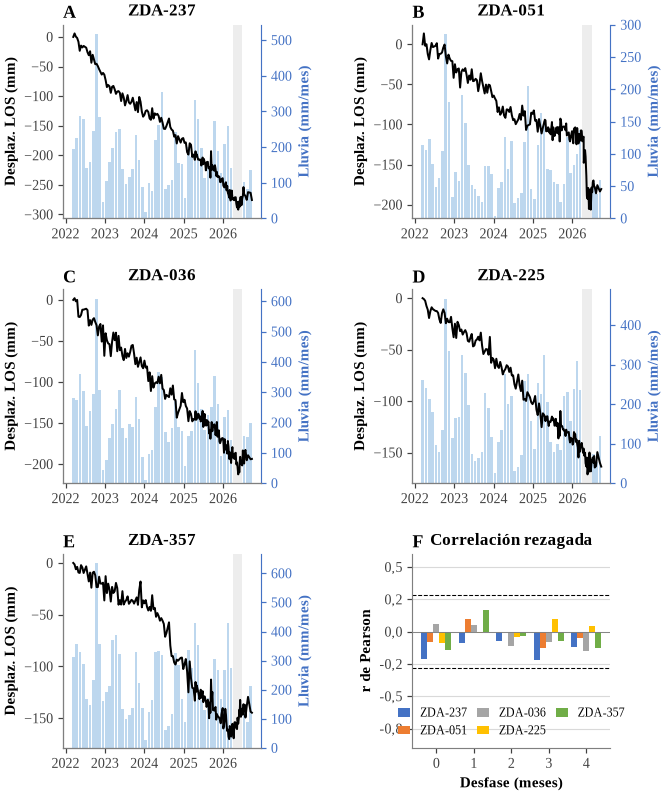

{'correlacion': {'ZDA-237': {0: -0.21, 1: -0.09, 2: -0.07, 3: -0.22, 4: -0.12}, 'ZDA-051': {0: -0.08, 1: 0.1, 2: 0.0, 3: -0.13, 4: -0.05}, 'ZDA-036': {0: 0.06, 1: 0.05, 2: -0.11, 3: -0.08, 4: -0.15}, 'ZDA-225': {0: -0.09, 1: -0.01, 2: -0.04, 3: 0.1, 4: 0.04}, 'ZDA-357': {0: -0.14, 1: 0.17, 2: -0.03, 3: -0.07, 4: -0.13}}, 'umbral_95': np.float64(0.28), 'meses': 48} {'ZDA-237': 2016, 'ZDA-051': 942, 'ZDA-036': 2439, 'ZDA-225': 1935, 'ZDA-357': 2616}


In [ ]:
CH = f'{R}/03_resultados/tablas/chirps_mensual_zonas.csv'
meses = pd.date_range('2022-03-01', '2026-09-01', freq='MS')
a_geo = Transformer.from_crs(32618, 4326, always_xy=True)
pts = {z: a_geo.transform(*zda[zda.ZDA == z].geometry.iloc[0].centroid.coords[0]) for z in ZONAS}
lluvia = pd.read_csv(CH, parse_dates=['mes']).set_index('mes') if os.path.exists(CH) else pd.DataFrame(index=meses)
faltan = [z for z in pts if z not in lluvia.columns]
if faltan:
    import time # el servidor limita las peticiones parciales, se baja cada mapa completo (unos 22 MB)
    from rasterio.io import MemoryFile
    for mes in meses:
        u = f'https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/tifs/chirps-v3.0.{mes:%Y.%m}.tif'
        for intento in range(6):
            r = requests.get(u, timeout=300)
            if r.status_code == 200: break
            time.sleep(15 * (intento + 1))
        else: raise RuntimeError(f'CHIRPS no respondió para {mes:%Y-%m}')
        with MemoryFile(r.content) as mf, mf.open() as ds:
            for z, v in zip(faltan, ds.sample([pts[z] for z in faltan])): lluvia.loc[mes, z] = float(v[0])
    lluvia.index.name = 'mes'; lluvia.to_csv(CH)
LAGS = range(0, 5); FIN = '2026-03-31'; CORR = {}
fig, ejes_l = plt.subplots(3, 2, figsize=(FIG_ANCHO, 19 * CM))
ejes_l = ejes_l.ravel()
for k_, z in enumerate(ZONAS):
    fechas, px, _, _ = SERIES[z]; s = pd.Series(px.mean(axis=1), index=fechas)
    p = lluvia[z].astype(float)
    ax = ejes_l[k_]; ax2 = ax.twinx()
    ax2.bar(p.index + pd.Timedelta(days=14), p.values, width=24, color='#BDD7EE', zorder=1)
    ax2.set_ylabel('Lluvia (mm/mes)', color=AZUL, fontsize=10); ax2.tick_params(axis='y', colors=AZUL, labelsize=9)
    ax2.spines['right'].set_visible(True); ax2.spines['right'].set_color(AZUL); ax2.spines['top'].set_visible(False)
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.plot(s.index, s.values, color='black', lw=1.3)
    ax.axvspan(pd.Timestamp('2026-04-01'), pd.Timestamp('2026-06-30'), color='#EDEDED', zorder=0, lw=0)
    ax.set_ylabel('Desplaz. LOS (mm)', fontsize=10); ejes(ax, None); eje_anios(ax); ax.tick_params(labelsize=9)
    ax.set_title(z, pad=6); letra_panel(ax, 'ABCDE'[k_])
    tasa = s.resample('D').mean().interpolate().resample('MS').mean().diff()
    df = pd.concat([p.rename('p'), tasa.rename('v')], axis=1).loc[:FIN].dropna()
    vdt = df.v - np.polyval(np.polyfit(np.arange(len(df)), df.v, 1), np.arange(len(df)))
    CORR[z] = {L: round(float(np.corrcoef(df.p.values[:len(df) - L], vdt.values[L:])[0, 1]), 2) for L in LAGS}
    ZONAS[z]['lluvia_anual_mm'] = round(float(p.loc['2023-01-01':'2025-12-31'].sum() / 3))
umbral = 1.96 / np.sqrt(len(df))
ax = ejes_l[5]; w = 0.8 / len(CORR)
PAL_Z = [AZUL, NARANJA, GRIS, ORO, VERDE]
for i, (z, cc) in enumerate(CORR.items()):
    ax.bar(np.array(list(LAGS)) + (i - (len(CORR) - 1) / 2) * w, list(cc.values()), w, label=z, color=PAL_Z[i % 5])
for u_ in (umbral, -umbral): ax.axhline(u_, color='black', lw=0.7, ls='--')
ax.axhline(0, color='#7F7F7F', lw=0.6); ax.set_ylim(-0.9, 0.6); ax.set_xticks(list(LAGS))
ax.set_xlabel('Desfase (meses)', fontsize=10); ax.set_ylabel('r de Pearson', fontsize=10); ax.tick_params(labelsize=9)
ax.legend(fontsize=8, ncol=3, loc='lower center', columnspacing=0.8, handlelength=1.0); ejes(ax)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt(v)))
ax.set_title('Correlación rezagada', pad=6); letra_panel(ax, 'F')
fig.tight_layout(h_pad=1.6, w_pad=2.5)
titulo_figura('Lluvia mensual y desplazamiento en las zonas representativas y correlación rezagada')
plt.show()
CIFRAS['lluvia'] = dict(correlacion=CORR, umbral_95=round(umbral, 2), meses=int(len(df)))
json.dump(CIFRAS, open(f'{PAN}/cifras_paneles.json', 'w'), ensure_ascii=False, indent=1, default=float)
print(CIFRAS['lluvia'], {z: ZONAS[z]['lluvia_anual_mm'] for z in ZONAS})